# H&M Personalized Fashion Recommendations

## Recommendation Engines group project: proof of concept for the CEO

**Team:** Avisa Ansari · Patrick Morton · Marie Chikovani · Karim Samaan · Jade Beeks

**Business problem:** H&M shows products at random, so customers rarely see what they want. This notebook designs, builds and evaluates a recommender that serves every customer, then estimates its added value.

## Executive summary

**Recommendation:** replace the random display with our hybrid recommender, starting with a 14-day A/B test on 291,600 customers.

We trained on 3.66 million purchases from 12 weeks of 2020 and tested on a sealed week with 68,984 customers.

| Model | Shoppers who bought from their 12 (hit rate) | MAP@12 | Recall@12 | NDCG@12 | Catalogue coverage | Personalization |
|---|---|---|---|---|---|---|
| Random (today) | 0.03% | 0.0000 | 0.0001 | 0.0000 | 99.96% | 1.00 |
| Trending now | 6.13% | 0.0072 | 0.0250 | 0.0140 | 0.01% | 0.00 |
| Buy again | 10.37% | 0.0232 | 0.0536 | 0.0352 | 24.45% | 0.80 |
| **Final hybrid** | **10.97%** | **0.0278** | **0.0592** | **0.0405** | **23.04%** | **0.91** |

- **The final system** gives new customers trends for their age group and gives returning customers a 50/50 blend of Content + Trends and Buy Again.
- **It works for every client:** all 1,371,980 customers received 12 distinct products in 5.6 minutes on a laptop.
- **Estimated added value:** about €15m to €90m in extra online sales a year, based on published lifts of 0.3% to 1.8%. A live A/B test is needed to confirm the real effect.

## Contents

| Part | What it covers | Lead |
|---|---|---|
| 0 | Setup: packages, data, configuration | Team |
| 1 | Data exploration, preprocessing, time-based split, scoring tool | Avisa Ansari |
| 2 | Non-personalized recommenders: random, popular, trending, demographic, buy again | Patrick Morton |
| 3 | Collaborative filtering: item-item, ALS, tuning, RMSE and MAE | Marie Chikovani |
| 4 | Content-based: BoW, TF-IDF, lemmatization, BERT, NER, new products | Karim Samaan |
| 5 | Hybrid: switching, weighted, mixed, beyond accuracy, CVTT | Jade Beeks |
| 6 | Context-aware recommender | Jade Beeks |
| 7 | Exploration-exploitation with bandits | Jade Beeks |
| 8 | Business value | Jade Beeks |
| 9 | End-to-end system for all clients and customer demo | Jade Beeks |
| 10 | A/B test, deployment, scalability, monitoring, ethics | Jade Beeks, Avisa Ansari |
| 11 | Conclusions | Team |

## How to run

Run all cells from top to bottom. The saved outputs come from a complete run on the full data.

1. Put `transactions_train.csv`, `customers.csv` and `articles.csv` from the Kaggle competition [H&M Personalized Fashion Recommendations](https://www.kaggle.com/competitions/h-and-m-personalized-fashion-recommendations/data) next to this notebook or in a `data` folder.
2. If the files are missing, the notebook downloads them with your Kaggle credentials. You must have accepted the competition rules.
3. Use at least 8 GB of memory. A complete run takes about one hour on a laptop. To skip the two slowest steps, set `RUN_SENTENCE_BERT = False` and `RUN_ALL_CUSTOMERS = False` in section 0.2.

# Part 0. Setup

## 0.1 Packages

In [1]:
import importlib.util
import subprocess
import sys

for package, module_name in [('implicit', 'implicit'), ('recmetrics', 'recmetrics'), ('spacy', 'spacy'),
                             ('sentence-transformers', 'sentence_transformers'), ('seaborn', 'seaborn'),
                             ('tqdm', 'tqdm'), ('kaggle', 'kaggle')]:
  if importlib.util.find_spec(module_name) is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', package])

if importlib.util.find_spec('en_core_web_sm') is None:
  subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
                         'https://github.com/explosion/spacy-models/releases/download/en_core_web_sm-3.8.0/en_core_web_sm-3.8.0-py3-none-any.whl'])

## 0.2 Imports and configuration

In [2]:
import gc
import os
import random
import time
import zipfile
import zlib
from abc import ABC, abstractmethod
from collections import Counter
from pathlib import Path
from typing import Iterable, Sequence

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import recmetrics
import scipy.sparse as sp
import seaborn as sns
import spacy
from implicit.als import AlternatingLeastSquares
from scipy.sparse import coo_matrix, csr_matrix, vstack
from scipy.stats import norm
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import normalize
from tqdm import tqdm

RUN_SENTENCE_BERT = True
RUN_ALL_CUSTOMERS = True

my_seed = 1234
SEED = 42
VAL_SEED = 42
TREND_WEEKS = 2

random.seed(my_seed)
np.random.seed(my_seed)

pd.set_option('display.float_format', '{:.4f}'.format)
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', 70)


def free(*names):
  for name in names:
    globals().pop(name, None)
  gc.collect()

## 0.3 Data files

In [3]:
COMPETITION = 'h-and-m-personalized-fashion-recommendations'
DATA_FILES = ['transactions_train.csv', 'customers.csv', 'articles.csv']
search_dirs = [Path.cwd(), Path.cwd() / 'data', Path.cwd() / 'data' / 'raw', Path('/content')]
DATA_DIR = next((d for d in search_dirs if all((d / f).exists() for f in DATA_FILES)), None)


def setup_kaggle():  # S19 Colab setup
  from google.colab import files
  files.upload()
  os.makedirs('/root/.kaggle', exist_ok=True)
  os.replace('kaggle.json', '/root/.kaggle/kaggle.json')
  os.chmod('/root/.kaggle/kaggle.json', 0o600)


if DATA_DIR is None:
  if 'google.colab' in sys.modules:
    setup_kaggle()
  DATA_DIR = Path.cwd() / 'data'
  DATA_DIR.mkdir(exist_ok=True)
  for file_name in DATA_FILES:
    subprocess.check_call([sys.executable, '-m', 'kaggle', 'competitions', 'download', '-c', COMPETITION,
                           '-f', file_name, '-p', str(DATA_DIR)])
    zipped = DATA_DIR / f'{file_name}.zip'
    if zipped.exists():
      with zipfile.ZipFile(zipped) as z:
        z.extractall(DATA_DIR)
      zipped.unlink()

print('Data found:', all((DATA_DIR / f).exists() for f in DATA_FILES))

Data found: True


# Part 1. Data exploration and evaluation setup

**Lead:** Avisa Ansari (Member 1)

## 1.1 Preprocessing and time-based split

In [4]:
from __future__ import annotations

def make_subset(transactions: pd.DataFrame, train_weeks: int = 12) -> pd.DataFrame:

    if train_weeks < 1:
        raise ValueError("train_weeks must be at least 1.")

    if "t_dat" not in transactions.columns:
        raise ValueError("Transactions must contain a 't_dat' column.")

    if transactions.empty:
        return transactions.copy()

    dates = pd.to_datetime(transactions["t_dat"])

    end_date = dates.max().normalize() + pd.Timedelta(days=1)

    start_date = end_date - pd.Timedelta(weeks=train_weeks + 1)

    mask = (dates >= start_date) & (dates < end_date)

    return transactions.loc[mask].copy()


def temporal_split(transactions: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:

    if transactions.empty:
        raise ValueError("Cannot split an empty dataset.")

    if "t_dat" not in transactions.columns:
        raise ValueError("Transactions must contain a 't_dat' column.")

    dates = pd.to_datetime(transactions["t_dat"])

    if dates.isna().any():
        raise ValueError("Transaction dates cannot contain missing values.")

    end_date = dates.max().normalize() + pd.Timedelta(days=1)
    test_start = end_date - pd.Timedelta(days=7)

    train = transactions.loc[dates < test_start].copy().reset_index(drop=True)
    test = transactions.loc[(dates >= test_start) & (dates < end_date)].copy().reset_index(drop=True)

    if train.empty or test.empty:
        raise ValueError("Both training and testing datasets must contain transactions.")

    return train, test


def assign_segments(train: pd.DataFrame, customer_ids: pd.Series) -> pd.Series:

    if "customer_id" not in train.columns:
        raise ValueError("Training data must contain a 'customer_id' column.")

    purchase_counts = train.groupby("customer_id", observed=True).size()

    counts = customer_ids.astype("string").map(purchase_counts).fillna(0).astype("int64")

    segments = pd.cut(
        counts,
        bins=[-1, 0, 4, float("inf")],
        labels=["new", "light", "regular"],
    )

    return segments.rename("segment")


def new_items(train: pd.DataFrame, test: pd.DataFrame) -> set[int]:

    if "article_id" not in train.columns or "article_id" not in test.columns:
        raise ValueError("Both datasets must contain an 'article_id' column.")

    train_items = set(map(int, train["article_id"].dropna().unique()))
    test_items = set(map(int, test["article_id"].dropna().unique()))

    return test_items - train_items

In [5]:
start_date = '2020-06-24'
end_date = '2020-09-22'

transaction_dtypes = {'t_dat': 'string', 'customer_id': 'string', 'article_id': 'int32',
                      'price': 'float32', 'sales_channel_id': 'int8'}

chunks = []
for chunk in pd.read_csv(DATA_DIR / 'transactions_train.csv', dtype=transaction_dtypes, chunksize=250_000):
  filtered = chunk.loc[chunk['t_dat'].between(start_date, end_date)]
  if not filtered.empty:
    chunks.append(filtered.copy())

transactions = pd.concat(chunks, ignore_index=True)
transactions['t_dat'] = pd.to_datetime(transactions['t_dat'])
subset = make_subset(transactions, train_weeks=12)
train, test = temporal_split(subset)
free('chunks', 'chunk', 'filtered', 'transactions', 'subset')

for df in (train, test):
  df['customer_id'] = df['customer_id'].astype(str)

articles = pd.read_csv(DATA_DIR / 'articles.csv', dtype={'article_id': 'int64'})
customers = pd.read_csv(DATA_DIR / 'customers.csv', usecols=['customer_id', 'age'])

test_customers = pd.Series(test['customer_id'].unique())
segments = assign_segments(train, test_customers)
segments.index = test_customers

## 1.2 Scoring tool and shared recommender interface

In [6]:
from __future__ import annotations

from abc import ABC, abstractmethod
from typing import Iterable

import pandas as pd


class Recommender(ABC):
    """Base class for all recommenders.

    Every subclass must:
    - learn from the training transactions in ``fit``;
    - return exactly ``k`` article_ids for ANY customer_id in ``recommend``,
      including customers it has never seen (use a fallback such as popularity).
    """

    name: str = "base"

    @abstractmethod
    def fit(
        self,
        train: pd.DataFrame,
        articles: pd.DataFrame | None = None,
        customers: pd.DataFrame | None = None,
    ) -> "Recommender":
        """Learn from training data. Must return ``self``."""

    @abstractmethod
    def recommend(self, customer_id: str, k: int = 12) -> list[int]:
        """Return a ranked list of ``k`` article_ids for one customer."""

    def recommend_all(self, customer_ids: Iterable[str], k: int = 12) -> dict[str, list[int]]:
        """Recommend for many customers. Override if your model can batch faster."""
        return {c: self.recommend(c, k) for c in customer_ids}

    def __repr__(self) -> str:
        return f"<{type(self).__name__} name={self.name!r}>"

In [7]:
from __future__ import annotations

import pandas as pd

import numpy as np

from collections import Counter
K = 12

def average_precision_at_k(actual: set[int], predicted: list[int], k: int = K) -> float:

    if k < 1:
        raise ValueError("k must be at least 1.")

    if not actual:
        return 0.0

    score = 0.0
    hits = 0
    seen = set()

    for rank, item in enumerate(predicted[:k], start=1):

        if item in actual and item not in seen:
            hits += 1
            score += hits / rank

        seen.add(item)

    return score / min(len(actual), k)


def map_at_k(actual: dict[str, set[int]], predicted: dict[str, list[int]], k: int = K) -> float:

    if k < 1:
        raise ValueError("k must be at least 1.")

    customers = [customer_id for customer_id, items in actual.items() if items]

    if not customers:
        return 0.0

    scores = [
        average_precision_at_k(
            actual[customer_id],
            predicted.get(customer_id, []),
            k
        )
        for customer_id in customers
    ]

    return sum(scores) / len(scores)


def recall_at_k(actual: dict[str, set[int]], predicted: dict[str, list[int]], k: int = K) -> float:

    if k < 1:
        raise ValueError("k must be at least 1.")

    customers = [customer_id for customer_id, items in actual.items() if items]

    if not customers:
        return 0.0

    scores = []

    for customer_id in customers:
        relevant_items = actual[customer_id]
        recommended_items = set(predicted.get(customer_id, [])[:k])

        hits = len(relevant_items & recommended_items)
        scores.append(hits / len(relevant_items))

    return sum(scores) / len(scores)


def ndcg_at_k(actual: dict[str, set[int]], predicted: dict[str, list[int]], k: int = K) -> float:

    if k < 1:
        raise ValueError("k must be at least 1.")

    customers = [customer_id for customer_id, items in actual.items() if items]

    if not customers:
        return 0.0

    scores = []

    for customer_id in customers:
        relevant_items = actual[customer_id]
        recommendations = predicted.get(customer_id, [])[:k]

        dcg = 0.0
        seen = set()

        for rank, item in enumerate(recommendations, start=1):
            if item in relevant_items and item not in seen:
                dcg += 1 / np.log2(rank + 1)

            seen.add(item)

        ideal_hits = min(len(relevant_items), k)

        idcg = sum(
            1 / np.log2(rank + 1)
            for rank in range(1, ideal_hits + 1)
        )

        scores.append(dcg / idcg)

    return sum(scores) / len(scores)


def hit_rate_at_k(actual: dict[str, set[int]], predicted: dict[str, list[int]], k: int = K) -> float:

    if k < 1:
        raise ValueError("k must be at least 1.")

    customers = [customer_id for customer_id, items in actual.items() if items]

    if not customers:
        return 0.0

    hits = 0

    for customer_id in customers:
        relevant_items = actual[customer_id]
        recommended_items = set(predicted.get(customer_id, [])[:k])

        if relevant_items & recommended_items:
            hits += 1

    return hits / len(customers)


def catalog_coverage(predicted: dict[str, list[int]], n_items: int) -> float:

    if n_items <= 0:
        raise ValueError("n_items must be greater than zero.")

    recommended_items = {
        item
        for recommendations in predicted.values()
        for item in recommendations
    }

    if len(recommended_items) > n_items:
        raise ValueError("Recommended items exceed the catalogue size.")

    return len(recommended_items) / n_items


def gini_index(predicted: dict[str, list[int]]) -> float:

    item_counts = Counter(
        item
        for recommendations in predicted.values()
        for item in recommendations
    )

    if not item_counts:
        return 0.0

    frequencies = sorted(item_counts.values())
    n = len(frequencies)
    total = sum(frequencies)

    weighted_sum = sum(
        rank * count
        for rank, count in enumerate(frequencies, start=1)
    )

    return (2 * weighted_sum) / (n * total) - (n + 1) / n



def intra_list_diversity(
    predicted: dict[str, list[int]],
    articles: pd.DataFrame,
    attribute: str = "product_group_name"
) -> float:

    if "article_id" not in articles.columns or attribute not in articles.columns:
        raise ValueError("Articles must contain article_id and the selected attribute.")

    if articles["article_id"].duplicated().any():
        raise ValueError("Article IDs must be unique.")

    item_groups = articles.set_index("article_id")[attribute].to_dict()

    scores = []

    for recommendations in predicted.values():
        if not recommendations:
            scores.append(0.0)
            continue

        groups = {
            item_groups[item]
            for item in recommendations
            if item in item_groups and pd.notna(item_groups[item])
        }

        scores.append(len(groups) / len(recommendations))

    return sum(scores) / len(scores) if scores else 0.0



def novelty(predicted: dict[str, list[int]], item_popularity: pd.Series) -> float:

    if item_popularity.empty:
        return 0.0

    counts = pd.to_numeric(item_popularity)

    if counts.isna().any() or (counts < 0).any():
        raise ValueError("Item popularity must contain valid non-negative counts.")

    total_purchases = counts.sum()

    if total_purchases <= 0:
        return 0.0

    denominator = total_purchases + len(counts) + 1

    scores = []

    for recommendations in predicted.values():
        for item in recommendations:
            count = counts.get(item, 0)
            probability = (count + 1) / denominator
            scores.append(-np.log2(probability))

    return float(np.mean(scores)) if scores else 0.0



def evaluate(
    model: Recommender,
    test: pd.DataFrame,
    segments: pd.Series | None = None,
    k: int = K,
    *,
    train: pd.DataFrame | None = None,
    articles: pd.DataFrame | None = None,
    customers: pd.DataFrame | None = None,
) -> pd.DataFrame:

    if k < 1:
        raise ValueError("k must be at least 1.")

    if not {"customer_id", "article_id"}.issubset(test.columns) or test.empty:
        raise ValueError("Test data must contain customer_id and article_id rows.")

    if test[["customer_id", "article_id"]].isna().any().any():
        raise ValueError("Test customer and article IDs cannot be missing.")

    actual = {
        str(customer_id): set(map(int, items))
        for customer_id, items in test.groupby(
            "customer_id", sort=False, observed=True
        )["article_id"]
    }

    customer_ids = list(actual)
    predicted = model.recommend_all(customer_ids, k=k)

    if set(predicted) != set(customer_ids):
        raise ValueError("Model must return recommendations for every test customer.")

    if any(len(items) != k or len(set(items)) != k for items in predicted.values()):
        raise ValueError("Each customer must receive k distinct recommendations.")

    if segments is None and train is not None:
        segments = assign_segments(train, pd.Series(customer_ids))

    segment_labels = None

    if segments is not None:
        if segments.index.is_unique and all(cid in segments.index for cid in customer_ids):
            segment_labels = segments.loc[customer_ids].astype("string").tolist()
        elif len(segments) == len(customer_ids):
            segment_labels = segments.astype("string").tolist()
        else:
            raise ValueError("Segments must align with the test customer IDs.")

    n_items = articles["article_id"].nunique() if articles is not None else None

    popularity = (
        train.groupby("article_id", observed=True).size()
        if train is not None else None
    )

    groups = {"all": customer_ids}

    if segment_labels is not None:
        for label in ("new", "light", "regular"):
            groups[label] = [
                cid
                for cid, group in zip(customer_ids, segment_labels)
                if group == label
            ]

    if customers is not None:
        if not {"customer_id", "age"}.issubset(customers.columns):
            raise ValueError("Customer data must contain customer_id and age.")

        age_lookup = customers.drop_duplicates(
            "customer_id"
        ).set_index("customer_id")["age"]

        ages = pd.to_numeric(
            pd.Series(customer_ids).map(age_lookup),
            errors="coerce"
        )

        age_labels = pd.cut(
            ages,
            bins=[0, 24, 34, 44, 54, 64, float("inf")],
            labels=["0-24", "25-34", "35-44", "45-54", "55-64", "65+"]
        ).astype("string").fillna("unknown").tolist()

        for label in dict.fromkeys(age_labels):
            groups[f"age:{label}"] = [
                cid
                for cid, group in zip(customer_ids, age_labels)
                if group == label
            ]

    rows = []

    for name, ids in groups.items():
        relevant = {cid: actual[cid] for cid in ids}
        recommendations = {cid: predicted[cid] for cid in ids}
        present = bool(ids)

        rows.append({
            "group": name,
            "n_customers": len(ids),
            f"MAP@{k}": map_at_k(relevant, recommendations, k) if present else np.nan,
            f"Recall@{k}": recall_at_k(relevant, recommendations, k) if present else np.nan,
            f"NDCG@{k}": ndcg_at_k(relevant, recommendations, k) if present else np.nan,
            f"HitRate@{k}": hit_rate_at_k(relevant, recommendations, k) if present else np.nan,
            "coverage": catalog_coverage(recommendations, n_items) if present and n_items else np.nan,
            "gini": gini_index(recommendations) if present else np.nan,
            "diversity": intra_list_diversity(recommendations, articles) if present and articles is not None else np.nan,
            "novelty": novelty(recommendations, popularity) if present and popularity is not None else np.nan,
        })

    return pd.DataFrame(rows).set_index("group")

### Data overview

In [8]:
print("Training transactions:", len(train))
print("Testing transactions:", len(test))

print("\nTraining period:")
print(train["t_dat"].min(), "to", train["t_dat"].max())

print("\nTesting period:")
print(test["t_dat"].min(), "to", test["t_dat"].max())

print("\nTraining data preview:")
display(train.head())

Training transactions: 3664080
Testing transactions: 240311

Training period:
2020-06-24 00:00:00 to 2020-09-15 00:00:00

Testing period:
2020-09-16 00:00:00 to 2020-09-22 00:00:00

Training data preview:


,t_dat,customer_id,article_id,price,sales_channel_id
0,2020-06-24,0001b0127d3e5ff8dadcfc6e5043682dba2070f2667081623faeb31c996242a6,844409002,0.0169,1
1,2020-06-24,0001b0127d3e5ff8dadcfc6e5043682dba2070f2667081623faeb31c996242a6,876053003,0.0254,1
2,2020-06-24,000493dd9fc463df1acc2081450c9e75ef8e87d5dd17ed6396773839f6bf71a9,831269004,0.0135,1
3,2020-06-24,000493dd9fc463df1acc2081450c9e75ef8e87d5dd17ed6396773839f6bf71a9,886223001,0.0441,1
4,2020-06-24,000493dd9fc463df1acc2081450c9e75ef8e87d5dd17ed6396773839f6bf71a9,868955003,0.0191,1


## 1.3 Sales over time

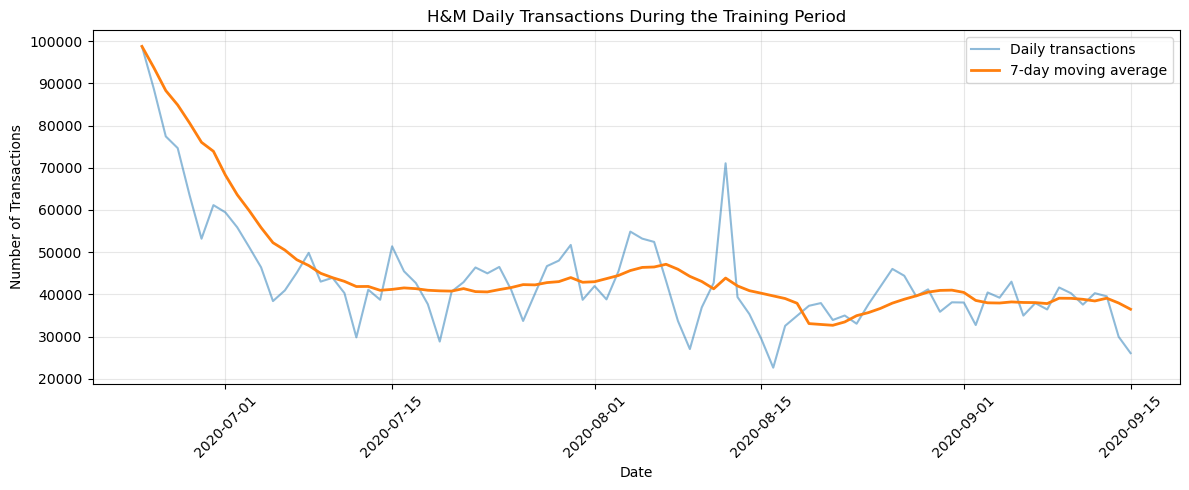

Average daily transactions: 43620
Highest daily transactions: 98790
Lowest daily transactions: 22613
Sales trend check passed!


In [9]:
daily_sales = train.groupby("t_dat").size().sort_index()
rolling_sales = daily_sales.rolling(window=7, min_periods=1).mean()

plt.figure(figsize=(12, 5))

plt.plot(daily_sales.index, daily_sales.values, alpha=0.5, label="Daily transactions")
plt.plot(rolling_sales.index, rolling_sales.values, linewidth=2, label="7-day moving average")

plt.title("H&M Daily Transactions During the Training Period")
plt.xlabel("Date")
plt.ylabel("Number of Transactions")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Average daily transactions:", round(daily_sales.mean()))
print("Highest daily transactions:", daily_sales.max())
print("Lowest daily transactions:", daily_sales.min())

assert daily_sales.sum() == len(train)
print("Sales trend check passed!")

Daily transactions decreased significantly at the beginning of the training period and became more stable afterwards.

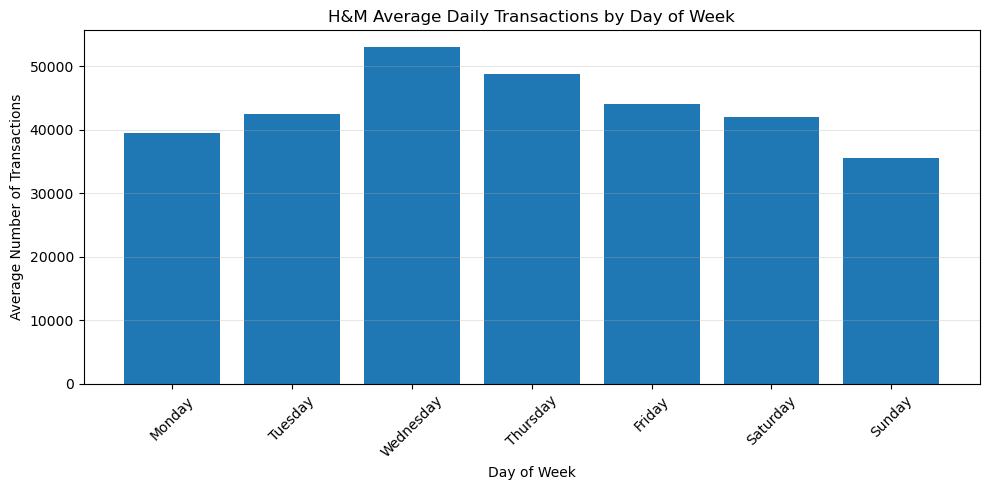

Highest average sales day: Wednesday
Lowest average sales day: Sunday
Weekly seasonality check passed!


In [10]:
weekdays = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

weekday_sales = daily_sales.groupby(
    daily_sales.index.day_name()
).mean().reindex(weekdays)

plt.figure(figsize=(10, 5))
plt.bar(weekday_sales.index, weekday_sales.values)

plt.title("H&M Average Daily Transactions by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Number of Transactions")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("Highest average sales day:", weekday_sales.idxmax())
print("Lowest average sales day:", weekday_sales.idxmin())

assert len(weekday_sales) == 7
assert weekday_sales.notna().all()

print("Weekly seasonality check passed!")

Wednesday has the highest average number of transactions and Sunday had the lowest.

## 1.4 Customers

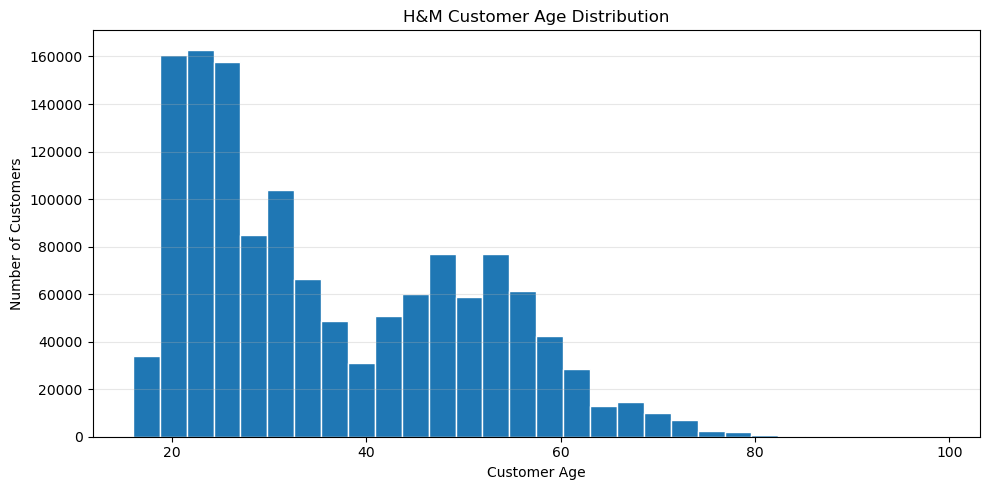

Total customers: 1371980
Average age: 36.4
Median age: 32.0
Missing ages: 15861
Customer age analysis passed!


In [11]:
customers_eda = pd.read_csv(
    DATA_DIR / "customers.csv",
    usecols=["age", "fashion_news_frequency"],
    dtype={
        "age": "float32",
        "fashion_news_frequency": "category"
    }
)

ages = customers_eda["age"].dropna()

plt.figure(figsize=(10, 5))
plt.hist(ages, bins=30, edgecolor="white")

plt.title("H&M Customer Age Distribution")
plt.xlabel("Customer Age")
plt.ylabel("Number of Customers")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("Total customers:", len(customers_eda))
print("Average age:", round(ages.mean(), 1))
print("Median age:", ages.median())
print("Missing ages:", customers_eda["age"].isna().sum())

assert len(ages) > 0
assert len(ages) + customers_eda["age"].isna().sum() == len(customers_eda)

print("Customer age analysis passed!")

The average customer age was 36.4 years with a median of 32.

,Customers,Percentage
fashion_news_frequency,,
NONE,877711,64.0000
Regularly,477416,34.8000
Missing,16011,1.2000
Monthly,842,0.1000


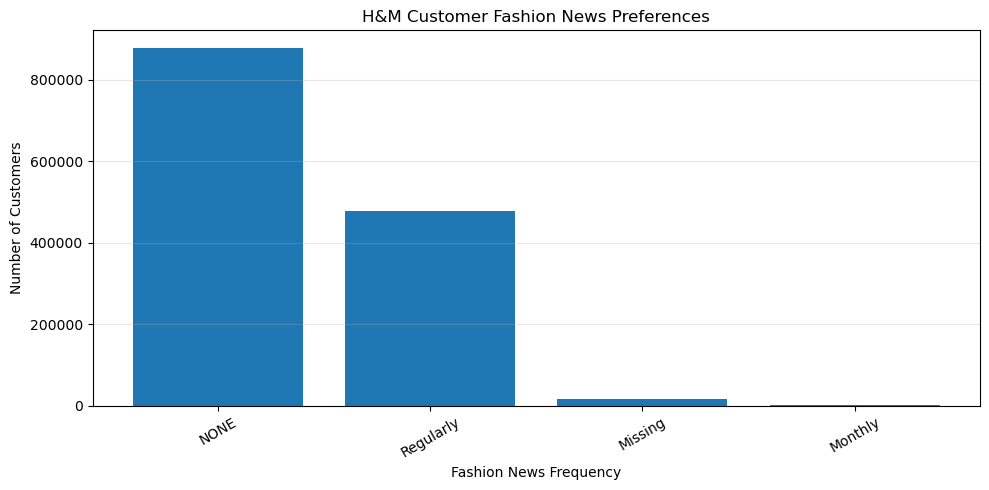

Most common preference: NONE
Total customers: 1371980
Fashion news analysis passed!


In [12]:
news_counts = customers_eda["fashion_news_frequency"].astype("string").fillna("Missing").value_counts()

news_percentages = (news_counts / len(customers_eda) * 100).round(1)

news_summary = pd.DataFrame({
    "Customers": news_counts,
    "Percentage": news_percentages
})

display(news_summary)

plt.figure(figsize=(10, 5))
plt.bar(news_counts.index, news_counts.values)

plt.title("H&M Customer Fashion News Preferences")
plt.xlabel("Fashion News Frequency")
plt.ylabel("Number of Customers")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("Most common preference:", news_counts.idxmax())
print("Total customers:", news_counts.sum())

assert news_counts.sum() == len(customers_eda)

print("Fashion news analysis passed!")

64% of the customers did not receive fashion news.

## 1.5 Product popularity

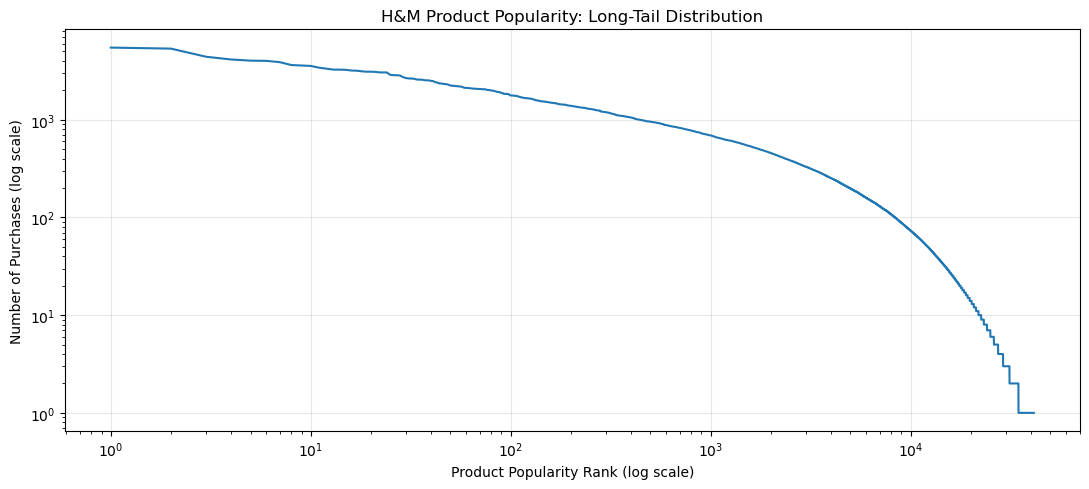

Unique purchased products: 41376
Most purchased product: 706016001
Purchases of most popular product: 5474
Median purchases per product: 13.0
Purchases from top 1% of products: 18.07 %
Products purchased only once: 16.29 %
Product popularity analysis passed!


In [13]:
item_counts = train["article_id"].value_counts().sort_values(ascending=False)

ranks = np.arange(1, len(item_counts) + 1)

plt.figure(figsize=(11, 5))
plt.loglog(ranks, item_counts.values)

plt.title("H&M Product Popularity: Long-Tail Distribution")
plt.xlabel("Product Popularity Rank (log scale)")
plt.ylabel("Number of Purchases (log scale)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

top_n = max(1, int(np.ceil(len(item_counts) * 0.01)))

top_share = item_counts.iloc[:top_n].sum() / len(train) * 100
single_purchase = (item_counts == 1).sum() / len(item_counts) * 100

print("Unique purchased products:", len(item_counts))
print("Most purchased product:", item_counts.index[0])
print("Purchases of most popular product:", item_counts.iloc[0])
print("Median purchases per product:", item_counts.median())
print("Purchases from top 1% of products:", round(top_share, 2), "%")
print("Products purchased only once:", round(single_purchase, 2), "%")

assert item_counts.sum() == len(train)
assert item_counts.index.is_unique
assert 0 <= top_share <= 100

print("Product popularity analysis passed!")

The popularity was not evenly distributed. The top 1% of products accounted for 18.07% of transactions whereas 16.29% of products were purchased only once.

## 1.6 Repeat purchases

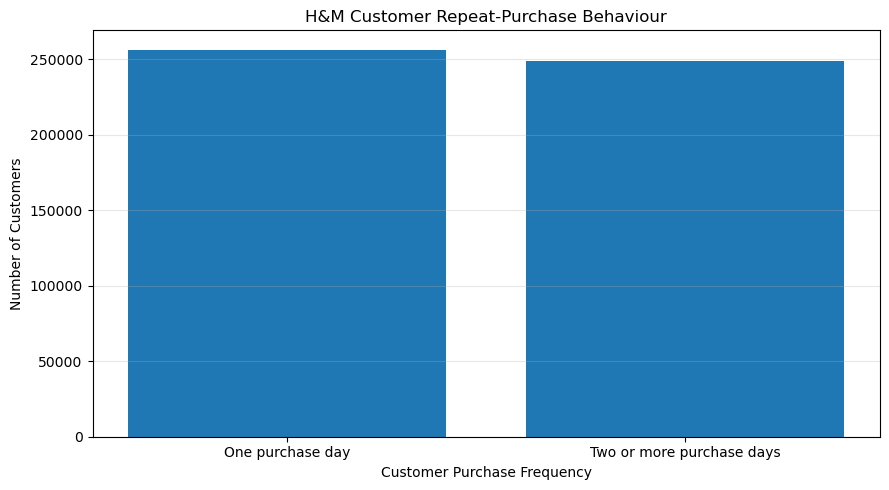

Total purchasing customers: 505310
Customers purchasing on one day: 256266
Repeat customers: 249044
Repeat-purchase rate: 49.29 %
Average purchase days per customer: 2.18
Repeat-purchase analysis passed!


In [14]:
customer_purchase_days = train.groupby(
    "customer_id", observed=True
)["t_dat"].nunique()

one_day_customers = (customer_purchase_days == 1).sum()
repeat_customers = (customer_purchase_days >= 2).sum()

repeat_rate = repeat_customers / len(customer_purchase_days) * 100

plt.figure(figsize=(9, 5))

plt.bar(
    ["One purchase day", "Two or more purchase days"],
    [one_day_customers, repeat_customers]
)

plt.title("H&M Customer Repeat-Purchase Behaviour")
plt.xlabel("Customer Purchase Frequency")
plt.ylabel("Number of Customers")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("Total purchasing customers:", len(customer_purchase_days))
print("Customers purchasing on one day:", one_day_customers)
print("Repeat customers:", repeat_customers)
print("Repeat-purchase rate:", round(repeat_rate, 2), "%")
print("Average purchase days per customer:", round(customer_purchase_days.mean(), 2))

assert one_day_customers + repeat_customers == len(customer_purchase_days)
assert customer_purchase_days.min() >= 1

print("Repeat-purchase analysis passed!")

49.29% of purchasing customers bought items on more than one day during the training period.

## 1.7 Sales channels

,Transactions,Percentage
sales_channel_id,,
1,1280296,34.9400
2,2383784,65.0600


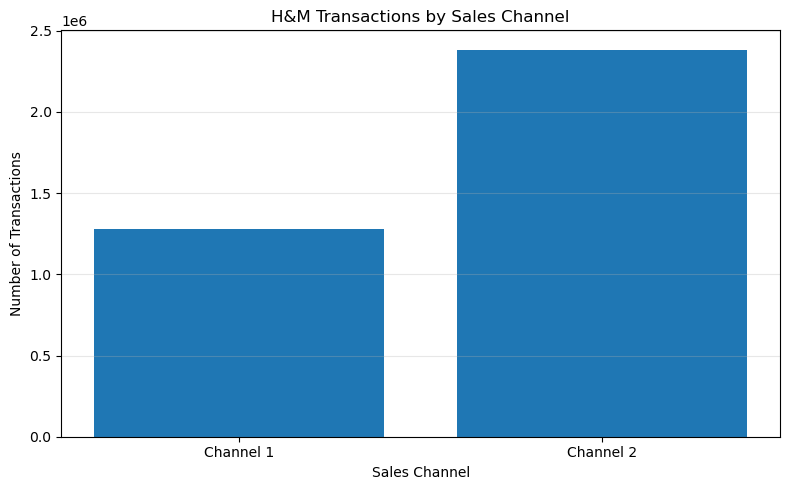

Most used sales channel: 2
Total transactions: 3664080
Sales channel analysis passed!


In [15]:
channel_counts = train["sales_channel_id"].value_counts().reindex([1, 2], fill_value=0)

channel_percentages = (channel_counts / len(train) * 100).round(2)

channel_summary = pd.DataFrame({
    "Transactions": channel_counts,
    "Percentage": channel_percentages
})

display(channel_summary)

plt.figure(figsize=(8, 5))
plt.bar(["Channel 1", "Channel 2"], channel_counts.values)

plt.title("H&M Transactions by Sales Channel")
plt.xlabel("Sales Channel")
plt.ylabel("Number of Transactions")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("Most used sales channel:", channel_counts.idxmax())
print("Total transactions:", channel_counts.sum())

assert channel_counts.sum() == len(train)
assert set(train["sales_channel_id"].unique()) == {1, 2}

print("Sales channel analysis passed!")

Channel 2 was the dominant sales channel.

## 1.8 Customer segments and new products

,Customers,Percentage
segment,,
new,19765,28.6500
light,16051,23.2700
regular,33168,48.0800


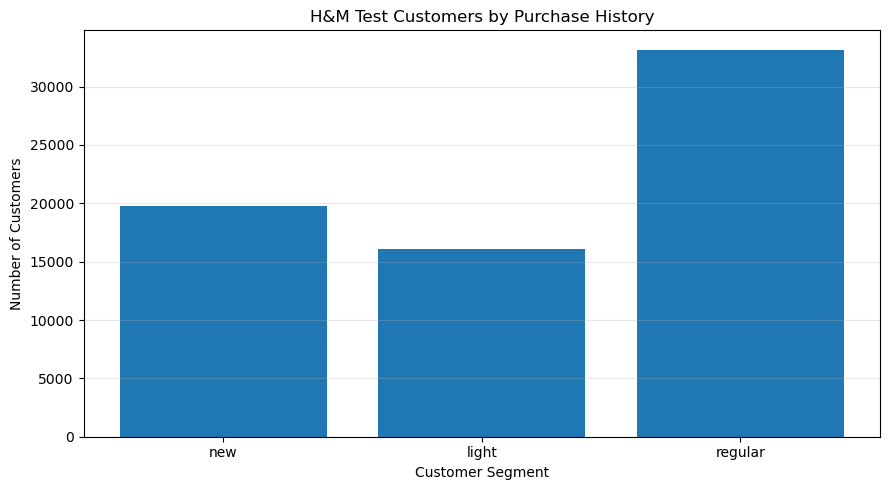

New products in testing: 922
Test transactions involving new products: 9904
New-product transaction percentage: 4.12 %


Customer segmentation and cold-start checks passed!

In [16]:
segment_counts = segments.value_counts().reindex(
    ["new", "light", "regular"], fill_value=0
)

segment_percentages = (segment_counts / len(test_customers) * 100).round(2)

segment_summary = pd.DataFrame({
    "Customers": segment_counts,
    "Percentage": segment_percentages
})

display(segment_summary)

plt.figure(figsize=(9, 5))
plt.bar(segment_counts.index, segment_counts.values)

plt.title("H&M Test Customers by Purchase History")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

new_products = new_items(train, test)

new_product_transactions = test["article_id"].isin(new_products).sum()

print("New products in testing:", len(new_products))
print("Test transactions involving new products:", new_product_transactions)
print("New-product transaction percentage:", round(new_product_transactions / len(test) * 100, 2), "%")

assert segment_counts.sum() == len(test_customers)
assert segments.notna().all()
assert new_products.isdisjoint(set(train["article_id"]))

print("Customer segmentation and cold-start checks passed!")

Regular customers represented 48.08% of test customers while 28.65% had no purchases in the training window.

## 1.9 Data quality and leakage checks

In [17]:
missing_summary = pd.DataFrame({
    "Training Missing": train.isna().sum(),
    "Training Missing (%)": (train.isna().mean() * 100).round(2),
    "Testing Missing": test.isna().sum(),
    "Testing Missing (%)": (test.isna().mean() * 100).round(2)
})

display(missing_summary)

print("Training period:", train["t_dat"].min(), "to", train["t_dat"].max())
print("Testing period:", test["t_dat"].min(), "to", test["t_dat"].max())

assert train["t_dat"].max() < test["t_dat"].min()
assert len(train) == 3664080
assert len(test) == 240311

assert train["customer_id"].notna().all()
assert test["customer_id"].notna().all()

assert train["article_id"].notna().all()
assert test["article_id"].notna().all()

assert new_products == (
    set(test["article_id"]) - set(train["article_id"])
)

print("Missing customer and article IDs: None")
print("Training and testing dates do not overlap")
print("New-product identification: Correct")
print("Data quality and temporal leakage checks passed!")

,Training Missing,Training Missing (%),Testing Missing,Testing Missing (%)
t_dat,0,0.0000,0,0.0000
customer_id,0,0.0000,0,0.0000
article_id,0,0.0000,0,0.0000
price,0,0.0000,0,0.0000
sales_channel_id,0,0.0000,0,0.0000


Training period: 2020-06-24 00:00:00 to 2020-09-15 00:00:00
Testing period: 2020-09-16 00:00:00 to 2020-09-22 00:00:00


Missing customer and article IDs: None
Training and testing dates do not overlap
New-product identification: Correct
Data quality and temporal leakage checks passed!


In [18]:
train_days = (train["t_dat"].max() - train["t_dat"].min()).days + 1
test_days = (test["t_dat"].max() - test["t_dat"].min()).days + 1

total_days = train_days + test_days

print("Training days:", train_days)
print("Testing days:", test_days)
print("Total days:", total_days)
print("Training transactions:", len(train))
print("Testing transactions:", len(test))

assert train_days == 84
assert test_days == 7
assert total_days == 91
assert train["t_dat"].max() + pd.Timedelta(days=1) == test["t_dat"].min()

print("Training window validation passed!")

Training days: 84
Testing days: 7
Total days: 91
Training transactions: 3664080
Testing transactions: 240311
Training window validation passed!


We used 12 weeks of training data and one week for testing. No missing values were found.

# Part 2. Non-personalized recommenders and the new-customer path

**Lead:** Patrick Morton (Member 2)

### Questions this part answers
1. **What does today's random display cost?** We score random recommendations, the company's current strategy.
2. **How far do simple, non-personalised ideas get us?** We try all-time best sellers, "trending now" (last 1–2 weeks), best sellers by age band, and "buy again".
3. **What do we show a customer we know nothing about?** We build the *new-customer path*: trends for their age band, or global trends if we don't know their age.
4. **What is the catch?** Popular items take most of the exposure. We measure how concentrated the recommendations are and which products are never shown.
5. **Which baseline must the personalised models beat?** "Trending now", not random. The last section explains why.

### Code: baseline recommenders

In [19]:
from __future__ import annotations

import zlib
from typing import Iterable

import numpy as np
import pandas as pd

# Age bands used for demographic filtering. Ten-year bands from 25 up; the
# youngest H&M customers (16-24) are a large, distinct group, so they get their own band.
AGE_BINS = [0, 25, 35, 45, 55, 65, 200]
AGE_LABELS = ["16-24", "25-34", "35-44", "45-54", "55-64", "65+"]
UNKNOWN_AGE = "unknown"


# ---------------------------------------------------------------------------
# helpers
# ---------------------------------------------------------------------------
def _last_weeks(train: pd.DataFrame, weeks: int | None) -> pd.DataFrame:
    """Rows from the final ``weeks`` weeks of ``train`` (all rows if ``weeks`` is None)."""
    if weeks is None:
        return train
    dates = pd.to_datetime(train["t_dat"])
    cutoff = dates.max() - pd.Timedelta(weeks=weeks)
    return train[dates > cutoff]


def _rank_items(df: pd.DataFrame, count_by: str = "customers") -> list[int]:
    """Article ids from most to least popular.

    ``count_by="customers"`` counts distinct buyers, so one shopper buying ten
    of the same item does not make it "popular". ``"rows"`` counts transactions.
    """
    if df.empty:
        return []
    if count_by == "customers":
        counts = df.groupby("article_id", observed=True)["customer_id"].nunique()
    elif count_by == "rows":
        counts = df["article_id"].value_counts()
    else:
        raise ValueError("count_by must be 'customers' or 'rows'")
    # stable tie-break on article_id so results are reproducible
    counts = counts.rename("n").reset_index().sort_values(
        ["n", "article_id"], ascending=[False, True])
    return counts["article_id"].astype(int).tolist()


def _top_up(items: list[int], fallback: Iterable[int], k: int) -> list[int]:
    """Fill ``items`` up to ``k`` with unseen items from ``fallback``, keeping order."""
    out = list(dict.fromkeys(items))[:k]
    if len(out) < k:
        seen = set(out)
        for item in fallback:
            if item not in seen:
                out.append(item)
                seen.add(item)
                if len(out) == k:
                    break
    return out


def age_band(age: pd.Series) -> pd.Series:
    """Map ages to the bands in ``AGE_LABELS``; missing ages become ``'unknown'``."""
    bands = pd.cut(age, bins=AGE_BINS, labels=AGE_LABELS, right=False)
    return bands.astype(object).where(bands.notna(), UNKNOWN_AGE)


def customer_age_bands(customers: pd.DataFrame) -> pd.Series:
    """Age band per customer, indexed by ``customer_id``. Handy for ``evaluate(segments=...)``."""
    return pd.Series(age_band(customers["age"]).to_numpy(),
                     index=customers["customer_id"], name="age_band")


# ---------------------------------------------------------------------------
# 1. Random: what the company does today
# ---------------------------------------------------------------------------
class RandomRecommender(Recommender):
    """Random products: the company's current display strategy.

    The pool is the whole catalogue when ``articles`` is given (what a random
    display really shows), otherwise the items seen in ``train``.
    The draw is seeded per customer, so results are reproducible.
    """
    name = "random"

    def __init__(self, seed: int = 42):
        self.seed = seed

    def fit(self, train, articles=None, customers=None):
        if articles is not None:
            pool = articles["article_id"]
        else:
            pool = train["article_id"]
        self.pool_ = np.unique(pool.to_numpy()).astype(np.int64)
        return self

    def recommend(self, customer_id, k=12):
        rng = np.random.default_rng([self.seed, zlib.crc32(str(customer_id).encode())])
        size = min(k, len(self.pool_))
        return rng.choice(self.pool_, size=size, replace=False).tolist()


# ---------------------------------------------------------------------------
# 2 + 3. Global popularity and "trending now"
# ---------------------------------------------------------------------------
class PopularityRecommender(Recommender):
    """Most-bought items, over all of train or only the last ``weeks`` weeks ("trending now").

    Everyone gets the same list. ``weeks=None`` gives all-time best sellers;
    ``weeks=1`` or ``2`` gives "trending now", which reacts to seasons and new
    collections and is the baseline every personalised model has to beat.
    """

    def __init__(self, weeks: int | None = None, count_by: str = "customers"):
        self.weeks = weeks
        self.count_by = count_by
        self.name = "popularity" if weeks is None else f"trending_{weeks}w"

    def fit(self, train, articles=None, customers=None):
        self.recent_ = _rank_items(_last_weeks(train, self.weeks), self.count_by)
        # always-available fallback in case the window is very short
        self.ranking_ = _top_up(self.recent_, _rank_items(train, self.count_by),
                                k=max(len(self.recent_), 1000))
        return self

    def recommend(self, customer_id, k=12):
        return self.ranking_[:k]

    def recommend_all(self, customer_ids, k=12):
        top = self.ranking_[:k]
        return {c: list(top) for c in customer_ids}


# ---------------------------------------------------------------------------
# 4. Demographic filtering, which is also the new-customer path
# ---------------------------------------------------------------------------
class AgeBandPopularityRecommender(Recommender):
    """Demographic filtering: trending items within the customer's age band.

    - age known      -> best sellers of the last ``weeks`` weeks among people of that age band;
    - age unknown,
      or customer not
      in ``customers`` -> global "trending now".
    Short band lists are topped up with global trends, so every customer gets ``k`` items.
    This is the new-customer path used by the hybrid.
    """
    name = "popularity_by_age"

    def __init__(self, weeks: int | None = 1, count_by: str = "customers"):
        self.weeks = weeks
        self.count_by = count_by

    def fit(self, train, articles=None, customers=None):
        if customers is None:
            raise ValueError("AgeBandPopularityRecommender needs the customers table (for age)")
        self.global_ = PopularityRecommender(self.weeks, self.count_by).fit(train)
        self.band_of_ = customer_age_bands(customers).to_dict()

        recent = _last_weeks(train, self.weeks)
        recent = recent.assign(age_band=recent["customer_id"].map(self.band_of_).fillna(UNKNOWN_AGE))
        global_list = self.global_.ranking_
        self.band_ranking_ = {
            band: _top_up(_rank_items(grp, self.count_by), global_list, k=100)
            for band, grp in recent.groupby("age_band")
            if band != UNKNOWN_AGE
        }
        return self

    def band(self, customer_id) -> str:
        """The age band used for this customer (``'unknown'`` if no age)."""
        return self.band_of_.get(customer_id, UNKNOWN_AGE)

    def recommend(self, customer_id, k=12):
        ranking = self.band_ranking_.get(self.band(customer_id))
        if ranking is None:
            return self.global_.recommend(customer_id, k)
        return _top_up(ranking[:k], self.global_.ranking_, k)

    def recommend_all(self, customer_ids, k=12):
        cache = {b: self.recommend_band(b, k) for b in [*self.band_ranking_, UNKNOWN_AGE]}
        return {c: list(cache.get(self.band(c), cache[UNKNOWN_AGE])) for c in customer_ids}

    def recommend_band(self, band: str, k: int = 12) -> list[int]:
        """The list shown to everyone in ``band`` (useful for the demo slides)."""
        ranking = self.band_ranking_.get(band)
        if ranking is None:
            return self.global_.ranking_[:k]
        return _top_up(ranking[:k], self.global_.ranking_, k)


class NewCustomerRecommender(AgeBandPopularityRecommender):
    """The new-customer path for the hybrid (Member 5).

    Same logic as ``AgeBandPopularityRecommender``: age-band trends when age is
    known, global trends when it isn't. It has its own name so the hybrid and
    the slides can refer to it directly.
    """
    name = "new_customer_path"


# ---------------------------------------------------------------------------
# 5. Buy again
# ---------------------------------------------------------------------------
class BuyAgainRecommender(Recommender):
    """The customer's own most frequently bought items, topped up with trends.

    Items are ranked by how many times the customer bought them, then by how
    recently. If ``weeks`` is set, only purchases in that window count (fashion
    goes out of stock quickly). Remaining slots come from ``fallback``, by
    default the new-customer path, so customers we know nothing about still get a full list.
    """
    name = "buy_again"

    def __init__(self, weeks: int | None = None, fallback: Recommender | None = None,
                 fallback_weeks: int = 1):
        self.weeks = weeks
        self.fallback = fallback
        self.fallback_weeks = fallback_weeks

    def fit(self, train, articles=None, customers=None):
        if self.fallback is None:
            self.fallback = (NewCustomerRecommender(self.fallback_weeks) if customers is not None
                             else PopularityRecommender(self.fallback_weeks))
        self.fallback.fit(train, articles, customers)

        hist = _last_weeks(train, self.weeks)
        agg = (hist.groupby(["customer_id", "article_id"], observed=True)
                   .agg(n=("t_dat", "size"), last=("t_dat", "max"))
                   .reset_index()
                   .sort_values(["customer_id", "n", "last", "article_id"],
                                ascending=[True, False, False, True]))
        self.history_ = (agg.groupby("customer_id", observed=True)["article_id"]
                            .agg(lambda s: s.astype(int).tolist())
                            .to_dict())
        return self

    def recommend(self, customer_id, k=12):
        own = self.history_.get(customer_id, [])[:k]
        if len(own) == k:
            return own
        return _top_up(own, self.fallback.recommend(customer_id, 2 * k), k)


# ---------------------------------------------------------------------------
# Popularity-bias analysis
# ---------------------------------------------------------------------------
def exposure_table(predicted: dict[str, list[int]], train: pd.DataFrame,
                   articles: pd.DataFrame | None = None) -> pd.DataFrame:
    """One row per article sold in train: units sold, times recommended, and attributes.

    Used to answer "which items never get shown?". ``articles`` adds product
    group / type columns when given.
    """
    sold = train["article_id"].value_counts().rename("sold")
    shown = pd.Series(
        [i for recs in predicted.values() for i in recs], dtype="int64"
    ).value_counts().rename("shown")
    tab = pd.concat([sold, shown], axis=1).fillna(0).astype(int)
    tab.index.name = "article_id"
    tab = tab.reset_index()
    if articles is not None:
        cols = [c for c in ["article_id", "prod_name", "product_type_name", "product_group_name",
                            "index_group_name", "colour_group_name"] if c in articles.columns]
        tab = tab.merge(articles[cols], on="article_id", how="left")
    return tab.sort_values("sold", ascending=False, ignore_index=True)


def popularity_bias_summary(predicted: dict[str, list[int]], train: pd.DataFrame,
                            top_share: float = 0.01) -> dict[str, float]:
    """Plain-language numbers on how concentrated a model's recommendations are.

    - ``distinct_items_shown``: how many different products anyone sees;
    - ``share_slots_top_items``: share of all recommendation slots taken by the top
      ``top_share`` best-selling items;
    - ``share_sold_items_never_shown``: share of items that sold in train but are never recommended;
    - ``share_sales_never_shown``: share of train sales coming from those never-shown items.
    The Gini index itself comes from ``evaluate()`` (Member 1).
    """
    tab = exposure_table(predicted, train)
    sold_items = tab[tab["sold"] > 0]
    n_top = max(1, int(round(top_share * len(sold_items))))
    top_items = set(sold_items.head(n_top)["article_id"])
    total_slots = tab["shown"].sum()
    never = sold_items[sold_items["shown"] == 0]
    return {
        "distinct_items_shown": int((tab["shown"] > 0).sum()),
        "share_slots_top_items": float(tab.loc[tab["article_id"].isin(top_items), "shown"].sum()
                                       / max(total_slots, 1)),
        "share_sold_items_never_shown": float(len(never) / max(len(sold_items), 1)),
        "share_sales_never_shown": float(never["sold"].sum() / max(sold_items["sold"].sum(), 1)),
    }


def lorenz_curve(predicted: dict[str, list[int]], n_items: int) -> tuple[np.ndarray, np.ndarray]:
    """Points for a Lorenz curve of recommendation exposure over ``n_items`` catalogue items.

    x = cumulative share of items (least to most shown), y = cumulative share of slots.
    A diagonal line means every item is shown equally; a curve hugging the
    bottom-right corner means a handful of items take all the exposure.
    """
    counts = pd.Series([i for r in predicted.values() for i in r]).value_counts().to_numpy()
    counts = np.concatenate([np.zeros(max(n_items - len(counts), 0)), np.sort(counts)])
    y = np.concatenate([[0], np.cumsum(counts) / max(counts.sum(), 1)])
    x = np.linspace(0, 1, len(y))
    return x, y

## 2.1 Data

We use the shared train/test split from Member 1: the last 12 weeks for training and the week after for testing, split by time so no future information leaks into training.

Here we only need two small columns from the customer table (age) and a few product attributes for the bias analysis, so we read just those.

In [20]:
age_bands = customer_age_bands(customers).reindex(test_customers).fillna("unknown")

print(f"train: {len(train):,} rows, {train['t_dat'].min():%Y-%m-%d} to {train['t_dat'].max():%Y-%m-%d}")
print(f"test : {len(test):,} rows, {test['customer_id'].nunique():,} customers")
print("test customers by segment:"); print(segments.value_counts())

train: 3,664,080 rows, 2020-06-24 to 2020-09-15
test : 240,311 rows, 68,984 customers
test customers by segment:
segment
regular    33168
new        19765
light      16051
Name: count, dtype: int64


In [21]:
def tidy(results: pd.DataFrame, model_name: str) -> pd.DataFrame:
    """Put evaluate() output in long form: one row per (model, group)."""
    r = results.copy()
    if "segment" in r.columns:
        r = r.set_index("segment")
    r.index.name = "group"
    return r.reset_index().assign(model=model_name)

def col(df: pd.DataFrame, key: str) -> str:
    """Find a metric column by part of its name, e.g. col(df, 'hit') -> 'hit_rate@12'."""
    return next(c for c in df.columns if key.lower() in c.lower())

## 2.2 Choosing the "trending now" window (validation, not test)

How many recent weeks should "trending now" count: 1, 2 or 4? To choose without touching the test week, we hold out the **last week of the training data** as a validation week, fit on the weeks before it, and pick the window that scores best there. Then we refit on all training data. The same idea as the test split, just one week earlier.

In [22]:
val_start = train["t_dat"].max() - pd.Timedelta(days=6)
fit_part, val_part = train[train["t_dat"] < val_start], train[train["t_dat"] >= val_start]

window_rows = []
for weeks in [1, 2, 4, None]:
    m = PopularityRecommender(weeks=weeks).fit(fit_part)
    window_rows.append(tidy(evaluate(m, val_part), m.name).query("group == 'all'"))
window_scores = pd.concat(window_rows, ignore_index=True).set_index("model")
display(window_scores)

best = window_scores[col(window_scores, "map")].idxmax()
TREND_WEEKS = None if best == "popularity" else int(best.split("_")[1].rstrip("w"))
print("chosen trending window (weeks):", TREND_WEEKS)

,group,n_customers,MAP@12,Recall@12,NDCG@12,HitRate@12,coverage,gini,diversity,novelty
model,,,,,,,,,,
trending_1w,all,72019,0.0069,0.0231,0.0134,0.0600,NaN,0.0000,NaN,NaN
trending_2w,all,72019,0.0070,0.0222,0.0132,0.0556,NaN,0.0000,NaN,NaN
trending_4w,all,72019,0.0049,0.0220,0.0112,0.0546,NaN,0.0000,NaN,NaN
popularity,all,72019,0.0036,0.0099,0.0069,0.0302,NaN,0.0000,NaN,NaN


chosen trending window (weeks): 2


**Reading this:** fashion moves fast. If the shortest window wins, it means last week's best sellers predict next week far better than best sellers from three months ago, because collections, weather and campaigns change week to week. We use the winning window for every popularity-based model below.

## 2.3 The five baselines

| Model | What the customer sees | Personal data needed |
|---|---|---|
| **Random** | Random products from the catalogue (today) | none |
| **Global popularity** | All-time best sellers of the training period | none |
| **Trending now** | Best sellers of the last week(s) | none |
| **Popularity by age band** | Trending among people of the same age | age |
| **Buy again** | Products the customer bought before, topped up with age-band trends | purchase history |

Popularity counts **distinct buyers**, not rows, so one shopper buying ten of the same item does not make it "popular". Every model returns 12 products for *any* customer ID, including ones it has never seen.

In [23]:
models = {
    "Random (today)": RandomRecommender(seed=42),
    "Global popularity": PopularityRecommender(weeks=None),
    "Trending now": PopularityRecommender(weeks=TREND_WEEKS),
    "Popularity by age band": AgeBandPopularityRecommender(weeks=TREND_WEEKS),
    "Buy again": BuyAgainRecommender(fallback=NewCustomerRecommender(weeks=TREND_WEEKS)),
}
for name, m in models.items():
    m.fit(train, articles, customers)

by_segment = pd.concat(
    [tidy(evaluate(m, test, segments=segments, train=train, articles=articles), name)
     for name, m in models.items()],
    ignore_index=True,
)
by_segment.set_index(["group", "model"]).sort_index()

n_customers  MAP@12  Recall@12  NDCG@12  HitRate@12  coverage   gini  diversity  novelty
group   model                                                                                                           
all     Buy again                     68984  0.0232     0.0536   0.0352      0.1037    0.2445 0.8667     0.2888  11.9107
        Global popularity             68984  0.0038     0.0122   0.0077      0.0359    0.0001 0.0000     0.4167   9.8630
        Popularity by age band        68984  0.0094     0.0291   0.0173      0.0696    0.0004 0.4227     0.2440  10.8643
        Random (today)                68984  0.0000     0.0001   0.0000      0.0003    0.9996 0.1998     0.4310  20.1911
        Trending now                  68984  0.0072     0.0250   0.0140      0.0613    0.0001 0.0000     0.2500  10.5660
light   Buy again                     16051  0.0346     0.0623   0.0456      0.1054    0.1101 0.9004     0.2712  11.2594
        Global popularity             16051  0.0042     0.0137   0.0082      0.0353    0.0001 0.0000     0.4167   9.8630
        Popularity by age band        16051  0.0105     0.0318   0.0184      0.0672    0.0004 0.4193     0.2413  10.8657
        Random (today)                16051  0.0000     0.0002   0.0001      0.0004    0.8381 0.2881     0.4307  20.1951
        Trending now                  16051  0.0080     0.0274   0.0151      0.0599    0.0001 0.0000     0.2500  10.5660
new     Buy again                     19765  0.0092     0.0307   0.0176      0.0732    0.0004 0.4146     0.2432  10.8681
        Global popularity             19765  0.0045     0.0147   0.0092      0.0419    0.0001 0.0000     0.4167   9.8630
        Popularity by age band        19765  0.0092     0.0307   0.0176      0.0732    0.0004 0.4146     0.2432  10.8681
        Random (today)                19765  0.0000     0.0001   0.0001      0.0003    0.8945 0.2908     0.4309  20.1883
        Trending now                  19765  0.0072     0.0258   0.0142      0.0620    0.0001 0.0000     0.2500  10.5660
regular Buy again                     33168  0.0261     0.0630   0.0407      0.1210    0.2380 0.7476     0.3246  12.8472
        Global popularity             33168  0.0032     0.0099   0.0066      0.0326    0.0001 0.0000     0.4167   9.8630
        Popularity by age band        33168  0.0090     0.0267   0.0165      0.0685    0.0004 0.4317     0.2459  10.8613
        Random (today)                33168  0.0000     0.0000   0.0000      0.0002    0.9767 0.2688     0.4311  20.1907
        Trending now                  33168  0.0068     0.0233   0.0135      0.0615    0.0001 0.0000     0.2500  10.5660

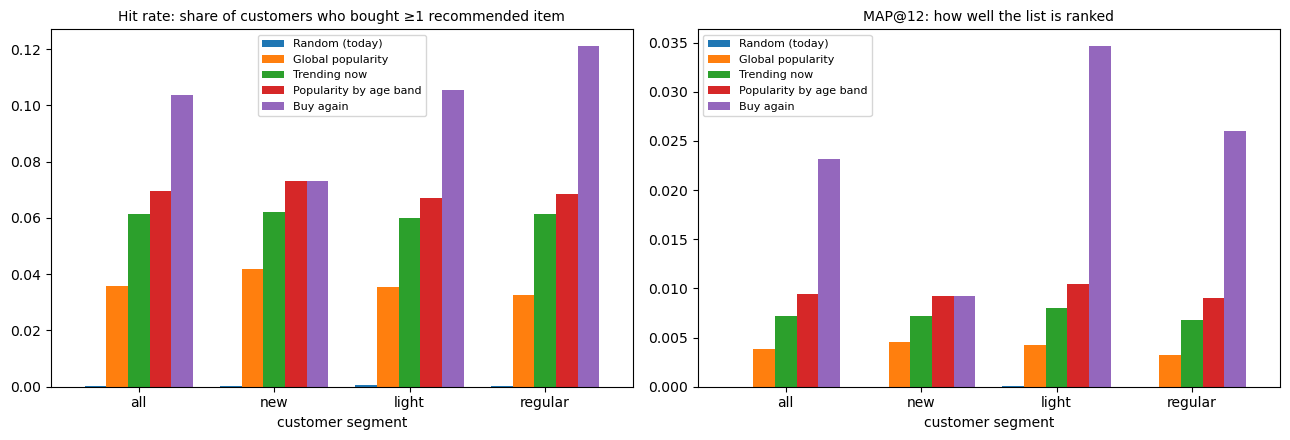

,HitRate@12,MAP@12,hit rate vs random
model,,,
Random (today),0.0003,0.0000,1.0000
Global popularity,0.0359,0.0038,137.5000
Trending now,0.0613,0.0072,234.8333
Popularity by age band,0.0696,0.0094,266.5556
Buy again,0.1037,0.0232,397.3333


In [24]:
HIT, MAP = col(by_segment, "hit"), col(by_segment, "map")
order = list(models)
groups = [g for g in ["all", "new", "light", "regular"] if g in set(by_segment["group"])]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, metric, title in [(axes[0], HIT, "Hit rate: share of customers who bought ≥1 recommended item"),
                          (axes[1], MAP, "MAP@12: how well the list is ranked")]:
    (by_segment.pivot(index="group", columns="model", values=metric)
               .loc[groups, order].plot.bar(ax=ax, rot=0, width=0.8))
    ax.set_title(title, fontsize=10); ax.set_xlabel("customer segment"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

summary = by_segment.query("group == 'all'").set_index("model").loc[order, [HIT, MAP]]
rand_hit = summary.loc["Random (today)", HIT]
summary["hit rate vs random"] = summary[HIT] / rand_hit if rand_hit > 0 else np.inf
summary

**What this means for the business**

- **Random display almost never shows a customer something they go on to buy.** With over 100,000 products in the catalogue, 12 random picks are a needle-in-a-haystack bet. This is the cost of today's strategy.
- **Simply showing what is selling right now multiplies hits many times over**, for every customer, with no personal data at all. It is the cheapest quick win available.
- **Age bands help where tastes differ by age** (compare the age-band chart below). It is a light form of personalisation that works even for first-time visitors, as long as we know their age.
- **"Buy again" is strongest for customers with history** (light and regular), because people often re-buy basics (check which product types dominate its hits). For new customers it falls back to age-band trends, so it never does worse than the new-customer path.

## 2.4 Results by age band

`evaluate()` breaks results down by any grouping we give it, so we pass the age bands instead of the purchase segments.

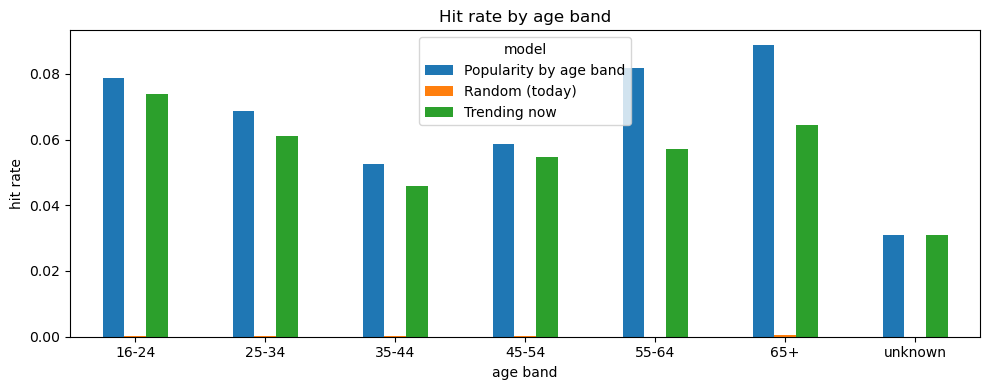

In [25]:
by_age = pd.concat(
    [tidy(evaluate(models[n], test, customers=customers), n)
     for n in ["Random (today)", "Trending now", "Popularity by age band"]],
    ignore_index=True,
)
by_age = by_age[by_age["group"].str.startswith("age:")].copy()
by_age["group"] = by_age["group"].str.removeprefix("age:").replace({"0-24": "16-24"})
band_order = [b for b in ["16-24", "25-34", "35-44", "45-54", "55-64", "65+", "unknown"]
              if b in set(by_age["group"])]
ax = (by_age.pivot(index="group", columns="model", values=HIT)
            .loc[band_order].plot.bar(rot=0, figsize=(10, 4)))
ax.set_title("Hit rate by age band"); ax.set_xlabel("age band"); ax.set_ylabel("hit rate")
plt.tight_layout(); plt.show()

In [26]:
# What each age band is shown: the top 5 product types per band
age_model = models["Popularity by age band"]
top_types = {}
for band in band_order:
    ids = age_model.recommend_band(band, k=12)
    top_types[band] = (articles.set_index("article_id").loc[ids, "product_type_name"]
                       .value_counts().head(5).index.tolist())
top_df = pd.DataFrame.from_dict(top_types, orient="index")
top_df.columns = [f"#{i}" for i in range(1, top_df.shape[1] + 1)]
top_df

,#1,#2,#3,#4,#5
16-24,Trousers,Sweater,Hoodie,Leggings/Tights,Dress
25-34,Sweater,Trousers,Dress,Leggings/Tights,Blazer
35-44,Trousers,Leggings/Tights,Dress,Sweater,Cardigan
45-54,Trousers,Sweater,Cardigan,Shirt,Blouse
55-64,Trousers,Cardigan,Sweater,T-shirt,Shirt
65+,Trousers,Cardigan,Sweater,T-shirt,Top
unknown,Trousers,Sweater,Dress,Leggings/Tights,Cardigan


**Reading this:** if the age-band model beats global trending mostly for the youngest and oldest bands, that is because those groups buy differently from the average customer, which is dominated by 25–45 year olds. Where the bars are equal, age adds nothing and global trends are enough.

## 2.5 The new-customer path

A **new** customer has no purchases in the training period, so collaborative filtering and "buy again" have nothing to work with. Our rule:

1. **Age known** → best sellers of the last week(s) among people in the same age band.
2. **Age unknown, or a customer ID we have never seen** → global "trending now".
3. If an age band has fewer than 12 trending items, top it up with global trends, so the list is always full.

This is `NewCustomerRecommender`, which Member 5's switching hybrid uses for the *new* segment.

In [27]:
new_only = by_segment.query("group == 'new'").set_index("model").loc[
    ["Random (today)", "Global popularity", "Trending now", "Popularity by age band"]]
display(new_only[[HIT, MAP]])

new_path = NewCustomerRecommender(weeks=TREND_WEEKS).fit(train, articles, customers)
print("never-seen customer ->", new_path.recommend("this-id-does-not-exist"))

,HitRate@12,MAP@12
model,,
Random (today),0.0003,0.0000
Global popularity,0.0419,0.0045
Trending now,0.0620,0.0072
Popularity by age band,0.0732,0.0092


never-seen customer -> [915526001, 751471001, 909370001, 918292001, 751471043, 918522001, 915529003, 706016001, 448509014, 863595006, 896152002, 865799006]


## 2.6 Popularity bias: who gets left out?

Popularity-based models show everyone almost the same few products. That is good for short-term hits but has costs:
- **Long-tail products are never shown**, so they can never become popular: a self-reinforcing loop.
- **New collections get no exposure** until they are already selling.
- Customers with less mainstream taste are served poorly.

We measure, for each model, how many different products anyone sees, what share of all recommendation slots go to the top 1% of best sellers, and how much of last quarter's sales came from products that are never recommended. (The Gini index from `evaluate()` gives the same picture as a single number.)

In [28]:
preds = {name: m.recommend_all(test_customers) for name, m in models.items()}
bias = pd.DataFrame({name: popularity_bias_summary(p, train) for name, p in preds.items()}).T
gini_cols = [c for c in by_segment.columns if "gini" in c.lower() or "coverage" in c.lower()]
bias = bias.join(by_segment.query("group == 'all'").set_index("model")[gini_cols])
bias.loc[order]

,distinct_items_shown,share_slots_top_items,share_sold_items_never_shown,share_sales_never_shown,coverage,gini
Random (today),105505.0000,0.0039,0.0003,0.0002,0.9996,0.1998
Global popularity,12.0000,1.0000,0.9997,0.9868,0.0001,0.0000
Trending now,12.0000,0.9167,0.9997,0.9908,0.0001,0.0000
Popularity by age band,38.0000,0.8483,0.9991,0.9810,0.0004,0.4227
Buy again,25801.0000,0.5832,0.3764,0.0171,0.2445,0.8667


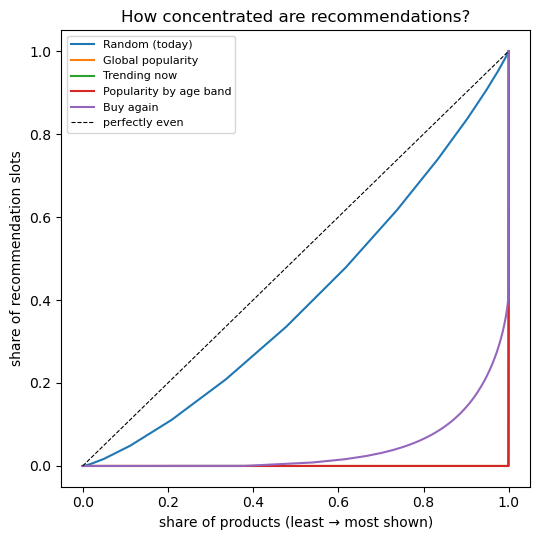

In [29]:
n_items = train["article_id"].nunique()
fig, ax = plt.subplots(figsize=(5.5, 5.5))
for name in order:
    x, y = lorenz_curve(preds[name], n_items)
    ax.plot(x, y, label=name)
ax.plot([0, 1], [0, 1], "k--", lw=0.8, label="perfectly even")
ax.set_xlabel("share of products (least → most shown)"); ax.set_ylabel("share of recommendation slots")
ax.set_title("How concentrated are recommendations?"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [30]:
# Which kinds of products never get shown by "trending now"?
exp = exposure_table(preds["Trending now"], train, articles)
by_group = (exp.assign(never_shown=exp["shown"] == 0)
              .groupby("product_group_name")
              .agg(items_sold=("article_id", "size"), units_sold=("sold", "sum"),
                   share_items_never_shown=("never_shown", "mean"), slots=("shown", "sum")))
by_group["share_of_sales"] = by_group["units_sold"] / by_group["units_sold"].sum()
by_group["share_of_slots"] = by_group["slots"] / by_group["slots"].sum()
by_group.sort_values("units_sold", ascending=False)[
    ["items_sold", "share_of_sales", "share_of_slots", "share_items_never_shown"]].head(12)

,items_sold,share_of_sales,share_of_slots,share_items_never_shown
product_group_name,,,,
Garment Upper body,15274,0.3607,0.4167,0.9997
Garment Lower body,8444,0.2174,0.5000,0.9993
Garment Full body,5703,0.1353,0.0833,0.9998
Swimwear,1816,0.0944,0.0000,1.0000
Underwear,2452,0.0820,0.0000,1.0000
Accessories,4028,0.0496,0.0000,1.0000
Shoes,1901,0.0220,0.0000,1.0000
Socks & Tights,966,0.0190,0.0000,1.0000
Unknown,108,0.0103,0.0000,1.0000


**Reading this:** a product group with a large share of sales but a tiny share of recommendation slots (or none) is being ignored by popularity models, even though customers clearly want it. These gaps are what personalised models (Members 3 and 4) and the exploration idea in Member 5's bandit sketch are meant to close.

## 2.7 Why "trending now" is the real baseline to beat

Comparing our final system with random display would make any model look brilliant, because random is so weak. The honest question for the CEO is: **is personalisation worth it compared with the simplest sensible alternative?** That alternative is "trending now":

1. **It is nearly free.** One count of last week's sales, one list for everyone. No personal data, no model to maintain, easy to explain.
2. **It is already much stronger than random**, as section 2.3 shows, so most of the gain over today comes from *any* sensible strategy.
3. **It reacts to fashion cycles.** New collections, seasons and campaigns show up in it within a week.
4. **It is safe.** It needs no customer data, so it raises no privacy concerns, and it works for every customer from day one.

So in the business case we report **two numbers** for every model: the gain over random (what the company gains versus today) and the gain over trending now (what *personalisation itself* adds). A personalised model that cannot beat trending now is not worth its extra complexity.

In [31]:
headline = by_segment.query("group == 'all'").set_index("model").loc[order, [HIT, MAP]]
trend_hit = headline.loc["Trending now", HIT]
for name, row in headline.iterrows():
    print(f"{name:<24} hit rate {row[HIT]:6.2%} | "
          f"x{row[HIT] / max(rand_hit, 1e-9):6.1f} vs random | x{row[HIT] / max(trend_hit, 1e-9):4.2f} vs trending")

Random (today)           hit rate  0.03% | x   1.0 vs random | x0.00 vs trending
Global popularity        hit rate  3.59% | x 137.5 vs random | x0.59 vs trending
Trending now             hit rate  6.13% | x 234.8 vs random | x1.00 vs trending
Popularity by age band   hit rate  6.96% | x 266.6 vs random | x1.14 vs trending
Buy again                hit rate 10.37% | x 397.3 vs random | x1.69 vs trending


## 2.8 Quick wins and hand-off

**Quick wins the company could ship next week, with no machine learning:**
1. Replace random display with **"trending now"**: one list for everyone, refreshed weekly.
2. Where age is known, show **trending in your age band** instead.
3. For returning customers, add a **"buy it again"** row for basics.

In [32]:
free('models', 'preds', 'by_segment', 'by_age', 'bias', 'exp', 'age_model', 'new_path', 'window_rows', 'fit_part', 'val_part')

# Part 3. Collaborative filtering

**Lead:** Marie Chikovani (Member 3)

### Code: collaborative filtering models

In [33]:
from __future__ import annotations

import numpy as np
import pandas as pd
from scipy.sparse import coo_matrix, csr_matrix, vstack

from implicit.als import AlternatingLeastSquares


class ItemItemCF(Recommender):
    """"Customers who bought X also bought Y", from items bought by the same customers.

    Purchases are binary implicit feedback: repeat transactions by one customer
    do not increase that customer's influence. Similarities are computed one
    item row at a time and truncated to ``n_neighbors``, avoiding a dense
    item-by-item matrix.
    """
    name = "item_item_cf"

    def __init__(self, n_neighbors: int = 100):
        if n_neighbors < 1:
            raise ValueError("n_neighbors must be at least 1.")
        self.n_neighbors = n_neighbors

    def fit(self, train, articles=None, customers=None):
        required = {"customer_id", "article_id"}
        if not required.issubset(train.columns):
            raise ValueError("Training data must contain customer_id and article_id.")
        if train.empty:
            raise ValueError("Training data must contain at least one interaction.")
        if train[["customer_id", "article_id"]].isna().any().any():
            raise ValueError("Training customer and article IDs cannot be missing.")

        customer_ids = train["customer_id"].astype("string")
        customer_codes, unique_customers = pd.factorize(customer_ids, sort=True)
        self.customer_index_ = {
            str(customer_id): index
            for index, customer_id in enumerate(unique_customers)
        }

        article_values = pd.to_numeric(train["article_id"], errors="raise").to_numpy(
            dtype=np.int64
        )
        self.article_ids_, article_codes = np.unique(
            article_values, return_inverse=True
        )

        # Sum duplicate COO coordinates, then replace counts with binary feedback.
        interactions = coo_matrix(
            (
                np.ones(len(train), dtype=np.int32),
                (customer_codes, article_codes),
            ),
            shape=(len(unique_customers), len(self.article_ids_)),
        ).tocsr()
        interactions.data.fill(1)
        self.interaction_matrix_ = interactions.astype(np.float32)
        self.interaction_matrix_.sort_indices()

        item_customers = self.interaction_matrix_.T.tocsr()
        item_support = np.asarray(item_customers.getnnz(axis=1))
        n_items = len(self.article_ids_)

        similarity_rows = []

        for item_index in range(n_items):
            cooccurrences = item_customers.getrow(item_index) @ self.interaction_matrix_
            neighbor_indices = cooccurrences.indices
            not_self = neighbor_indices != item_index
            neighbor_indices = neighbor_indices[not_self]
            cooccurrence_counts = cooccurrences.data[not_self]

            if len(neighbor_indices):
                similarities = cooccurrence_counts / np.sqrt(
                    item_support[item_index] * item_support[neighbor_indices]
                )
                order = np.lexsort(
                    (self.article_ids_[neighbor_indices], -similarities)
                )[: self.n_neighbors]
                neighbor_indices = neighbor_indices[order].astype(np.int32, copy=False)
                similarities = similarities[order].astype(np.float32, copy=False)
            else:
                similarities = np.empty(0, dtype=np.float32)

            similarity_rows.append(
                coo_matrix(
                    (
                        similarities,
                        (np.zeros(len(neighbor_indices), dtype=np.int32), neighbor_indices),
                    ),
                    shape=(1, n_items),
                ).tocsr()
            )

        self.similarity_matrix_ = vstack(
            similarity_rows, format="csr", dtype=np.float32
        )

        self.fallback_ = PopularityRecommender().fit(train)
        return self

    def recommend(self, customer_id, k=12):
        if k < 0:
            raise ValueError("k must be non-negative.")
        if k == 0:
            return []

        customer_index = self.customer_index_.get(str(customer_id))
        purchased: set[int] = set()
        ranked: list[int] = []

        if customer_index is not None:
            history = self.interaction_matrix_.getrow(customer_index)
            purchased = set(self.article_ids_[history.indices].tolist())
            scores = history @ self.similarity_matrix_
            candidate_indices = scores.indices
            candidate_scores = scores.data
            eligible = np.array(
                [
                    self.article_ids_[index] not in purchased
                    for index in candidate_indices
                ],
                dtype=bool,
            )
            candidate_indices = candidate_indices[eligible]
            candidate_scores = candidate_scores[eligible]
            order = np.lexsort(
                (self.article_ids_[candidate_indices], -candidate_scores)
            )
            ranked = self.article_ids_[candidate_indices[order]].astype(int).tolist()

        recommendations = ranked[:k]
        if len(recommendations) < k:
            seen = purchased | set(recommendations)
            for article_id in self.fallback_.recommend(
                customer_id, k=len(self.fallback_.ranking_)
            ):
                article_id = int(article_id)
                if article_id not in seen:
                    recommendations.append(article_id)
                    seen.add(article_id)
                    if len(recommendations) == k:
                        break

        return recommendations


class ALSRecommender(Recommender):
    """Matrix factorisation for purchase data (``implicit`` library).

    Each distinct purchase is a positive implicit interaction. ``alpha=40``
    gives observed interactions confidence 40 while unobserved pairs retain
    the library's baseline confidence of 1.
    """
    name = "als"

    def __init__(self, factors: int = 64, regularization: float = 0.01, iterations: int = 15):
        self.factors = factors
        self.regularization = regularization
        self.iterations = iterations

    def fit(self, train, articles=None, customers=None):
        required = {"customer_id", "article_id"}
        if not required.issubset(train.columns):
            raise ValueError("Training data must contain customer_id and article_id.")
        if train.empty:
            raise ValueError("Training data must contain at least one interaction.")
        if train[["customer_id", "article_id"]].isna().any().any():
            raise ValueError("Training customer and article IDs cannot be missing.")

        customer_ids = train["customer_id"].astype("string")
        customer_codes, unique_customers = pd.factorize(customer_ids, sort=True)
        self.customer_index_ = {
            str(customer_id): index
            for index, customer_id in enumerate(unique_customers)
        }

        article_values = pd.to_numeric(train["article_id"], errors="raise").to_numpy(
            dtype=np.int64
        )
        self.article_ids_, article_codes = np.unique(
            article_values, return_inverse=True
        )

        interactions = coo_matrix(
            (
                np.ones(len(train), dtype=np.float32),
                (customer_codes, article_codes),
            ),
            shape=(len(unique_customers), len(self.article_ids_)),
        ).tocsr()
        interactions.data.fill(1.0)
        self.interaction_matrix_ = interactions
        self.interaction_matrix_.sort_indices()

        self.model_ = AlternatingLeastSquares(
            factors=self.factors,
            regularization=self.regularization,
            iterations=self.iterations,
            alpha=40.0,
            random_state=42,
        )
        self.model_.fit(self.interaction_matrix_, show_progress=False)
        self.fallback_ = PopularityRecommender().fit(train)
        return self

    def recommend(self, customer_id, k=12):
        if k < 0:
            raise ValueError("k must be non-negative.")
        if k == 0:
            return []

        customer_index = self.customer_index_.get(str(customer_id))
        if customer_index is None:
            return self.fallback_.recommend(customer_id, k)

        history = self.interaction_matrix_.getrow(customer_index)
        purchased = set(self.article_ids_[history.indices].tolist())
        available_count = len(self.article_ids_) - len(purchased)
        if available_count:
            item_indices, _ = self.model_.recommend(
                customer_index,
                history,
                N=min(k, available_count),
                filter_already_liked_items=True,
            )
        else:
            item_indices = []

        recommendations: list[int] = []
        seen = purchased.copy()
        for item_index in item_indices:
            if item_index < 0 or item_index >= len(self.article_ids_):
                continue
            article_id = int(self.article_ids_[item_index])
            if article_id not in seen:
                recommendations.append(article_id)
                seen.add(article_id)
                if len(recommendations) == k:
                    return recommendations

        for article_id in self.fallback_.recommend(
            customer_id, k=len(self.fallback_.ranking_)
        ):
            article_id = int(article_id)
            if article_id not in seen:
                recommendations.append(article_id)
                seen.add(article_id)
                if len(recommendations) == k:
                    break

        return recommendations

## 3.1 Interaction matrix

Rows represent customers and columns represent articles. A nonzero entry marks a purchase; repeated transactions are collapsed to one interaction. CSR storage keeps this large matrix sparse.

## 3.2 Item-to-item collaborative filtering

Cosine similarity links articles bought by the same customers. Each article keeps at most 100 neighbours. A customer's purchase history scores other articles; purchased items are excluded and popularity fills any remaining slots. Both models exclude prior purchases, so repeat purchases in the test week cannot count as hits and may lower evaluation scores.

## 3.3 ALS with implicit feedback

ALS learns latent customer and article factors from positive purchase signals, not ratings. The `implicit` library scales observed interaction confidence by `alpha=40` (a binary purchase therefore has confidence 40; unobserved pairs retain baseline confidence 1). A fixed random seed supports reproducibility.

## 3.4 ALS parameter comparison

Use the final seven days of `train.parquet` for validation and fit on the earlier training rows. The final test week is not loaded. A fixed sample of 10,000 validation customers keeps the comparison manageable; every setting uses the same customers and all their validation transactions.

Compare 32 and 64 factors with regularization 0.01 and 0.1. Keep 15 iterations and `alpha=40` fixed. Select by MAP@12, with Recall@12 and NDCG@12 as supporting metrics.

### 3.4.1 Internal validation split

The last week of the training period is held out chronologically. Only the training parquet and the columns needed for collaborative filtering are read.

In [34]:
transactions = train[["t_dat", "customer_id", "article_id"]]

validation_start = transactions["t_dat"].max().normalize() - pd.Timedelta(days=6)
fit_train = transactions.loc[transactions["t_dat"] < validation_start].copy()
validation = transactions.loc[transactions["t_dat"] >= validation_start].copy()

validation_customer_ids = (
    validation["customer_id"].astype("string").drop_duplicates()
)
sampled_customer_ids = validation_customer_ids.sample(
    n=min(10_000, len(validation_customer_ids)), random_state=42
)
validation_sample = validation.loc[
    validation["customer_id"].astype("string").isin(sampled_customer_ids)
].copy()

print(f"Fit period: {fit_train['t_dat'].min().date()} to {fit_train['t_dat'].max().date()}")
print(f"Validation period: {validation['t_dat'].min().date()} to {validation['t_dat'].max().date()}")
print(f"Fit rows: {len(fit_train):,}; validation rows: {len(validation):,}")
print(f"Validation sample: {len(sampled_customer_ids):,} customers, {len(validation_sample):,} transactions")

Fit period: 2020-06-24 to 2020-09-08
Validation period: 2020-09-09 to 2020-09-15
Fit rows: 3,408,839; validation rows: 255,241
Validation sample: 10,000 customers, 35,031 transactions


### 3.4.2 Fit and evaluate each setting

The shared `evaluate()` function scores the same validation sample for each model. The output reports the three ranking metrics and fit/evaluation times.

In [35]:
results = []
for factors in (32, 64):
    for regularization in (0.01, 0.1):
        model = ALSRecommender(
            factors=factors, regularization=regularization, iterations=15
        )
        fit_start = time.perf_counter()
        model.fit(fit_train)
        fit_seconds = time.perf_counter() - fit_start

        evaluation_start = time.perf_counter()
        metrics = evaluate(model, validation_sample, k=12, train=fit_train)
        evaluation_seconds = time.perf_counter() - evaluation_start
        results.append({
            "factors": factors,
            "regularization": regularization,
            "iterations": 15,
            "MAP@12": metrics.loc["all", "MAP@12"],
            "Recall@12": metrics.loc["all", "Recall@12"],
            "NDCG@12": metrics.loc["all", "NDCG@12"],
            "fit_seconds": fit_seconds,
            "evaluation_seconds": evaluation_seconds,
        })

results = pd.DataFrame(results).sort_values("MAP@12", ascending=False)
display(results.reset_index(drop=True))

,factors,regularization,iterations,MAP@12,Recall@12,NDCG@12,fit_seconds,evaluation_seconds
0,64,0.0100,15,0.0075,0.0195,0.0128,48.7602,3.6979
1,64,0.1000,15,0.0074,0.0192,0.0126,46.5799,3.8298
2,32,0.0100,15,0.0065,0.0176,0.0113,31.5362,3.0689
3,32,0.1000,15,0.0064,0.0173,0.0112,31.7939,3.4594


### 3.4.3 Parameter choice

The 64-factor model with regularization 0.01 had the highest MAP@12 (0.0075), so it was selected. It also led on Recall@12 (0.0195) and NDCG@12 (0.0128). The 64-factor settings took about twice as long to fit as the 32-factor settings, but improved all three validation metrics.

## 3.5 Refit the selected model

After selecting by validation MAP@12, refit that configuration on all rows in the original training period, including the internal validation week. The final test period remains unused.

In [36]:
best = results.iloc[0]
selected_model = ALSRecommender(
    factors=int(best["factors"]),
    regularization=float(best["regularization"]),
    iterations=15,
)
refit_start = time.perf_counter()
selected_model.fit(transactions)
refit_seconds = time.perf_counter() - refit_start

print(
    f"Selected factors={selected_model.factors}, "
    f"regularization={selected_model.regularization}, "
    f"iterations={selected_model.iterations}; "
    f"full-training refit took {refit_seconds:.1f} seconds."
)

Selected factors=64, regularization=0.01, iterations=15; full-training refit took 49.5 seconds.


## 3.6 Final model comparison

Fit all three models on the official training split and evaluate them on the full held-out week (16-22 September 2020). Passing training data to `evaluate()` lets it derive the team's customer segments and training popularity; article metadata supplies catalogue coverage and diversity. Test transactions are used only as evaluation targets.

In [37]:
official_train = transactions
official_test = test[["customer_id", "article_id"]]
article_info = articles[["article_id", "product_group_name"]]

models = [
    ("ItemItemCF (100 neighbors)", ItemItemCF(n_neighbors=100), None),
    ("ALS (64 factors, reg=0.01)", selected_model, refit_seconds),
    ("Trending Now (2 weeks)", PopularityRecommender(weeks=2), None),
]
model_scores = {}
comparison_rows = []
new_test_articles = len(new_items(official_train, official_test))

for name, model, fit_seconds in models:
    if fit_seconds is None:
        fit_start = time.perf_counter()
        model.fit(official_train)
        fit_seconds = time.perf_counter() - fit_start

    evaluation_start = time.perf_counter()
    scores = evaluate(
        model, official_test, k=12,
        train=official_train, articles=article_info,
    )
    evaluation_seconds = time.perf_counter() - evaluation_start
    model_scores[name] = scores
    overall = scores.loc["all"]
    comparison_rows.append({
        "Model": name,
        "Fit (s)": fit_seconds,
        "Evaluation (s)": evaluation_seconds,
        **{metric: overall[metric] for metric in [
            "MAP@12", "Recall@12", "NDCG@12", "HitRate@12",
            "coverage", "gini", "diversity", "novelty",
        ]},
    })

overall_results = pd.DataFrame(comparison_rows)
print(
    f"Full test customers: {official_test['customer_id'].nunique():,}; "
    f"test-only articles: {new_test_articles:,}"
)
display(overall_results)

Full test customers: 68,984; test-only articles: 922


,Model,Fit (s),Evaluation (s),MAP@12,Recall@12,NDCG@12,HitRate@12,coverage,gini,diversity,novelty
0,ItemItemCF (100 neighbors),10.6063,19.5991,0.0070,0.0182,0.0120,0.0428,0.3204,0.7809,0.3466,14.1931
1,"ALS (64 factors, reg=0.01)",49.5138,35.4052,0.0075,0.0205,0.0132,0.0493,0.0330,0.7779,0.2725,11.1926
2,Trending Now (2 weeks),1.0354,5.5284,0.0072,0.0250,0.0140,0.0613,0.0001,0.0000,0.2500,10.5660


## 3.7 Performance by customer segment

The shared evaluator uses the project definitions: new customers have no training purchases, light customers have 1-4, and regular customers have 5 or more. The table shows the four ranking metrics for the same full test customer set.

In [38]:
segment_rows = []
for model_name, scores in model_scores.items():
    for segment in ("new", "light", "regular"):
        row = scores.loc[segment]
        segment_rows.append({
            "Model": model_name,
            "Segment": segment,
            "Customers": int(row["n_customers"]),
            "MAP@12": row["MAP@12"],
            "Recall@12": row["Recall@12"],
            "NDCG@12": row["NDCG@12"],
            "HitRate@12": row["HitRate@12"],
        })
segment_results = pd.DataFrame(segment_rows)
display(segment_results)

,Model,Segment,Customers,MAP@12,Recall@12,NDCG@12,HitRate@12
0,ItemItemCF (100 neighbors),new,19765,0.0045,0.0147,0.0092,0.0419
1,ItemItemCF (100 neighbors),light,16051,0.0101,0.0218,0.0150,0.0389
2,ItemItemCF (100 neighbors),regular,33168,0.0070,0.0185,0.0123,0.0452
3,"ALS (64 factors, reg=0.01)",new,19765,0.0045,0.0147,0.0092,0.0419
4,"ALS (64 factors, reg=0.01)",light,16051,0.0108,0.0256,0.0168,0.0479
5,"ALS (64 factors, reg=0.01)",regular,33168,0.0077,0.0215,0.0139,0.0544
6,Trending Now (2 weeks),new,19765,0.0072,0.0258,0.0142,0.0620
7,Trending Now (2 weeks),light,16051,0.0080,0.0274,0.0151,0.0599
8,Trending Now (2 weeks),regular,33168,0.0068,0.0233,0.0135,0.0615


## 3.8 Limitations and hybrid implications

- **New customers:** ItemItemCF and ALS have no purchase history to score, so both return their all-time popularity fallback. Their new-segment results are identical and below the official two-week Trending Now baseline on all four ranking metrics.
- **Light customers:** ALS has higher MAP@12 and NDCG@12 than the official two-week Trending Now baseline, but lower Recall@12 and HitRate@12. ItemItemCF has a small MAP@12 advantage, while trailing on the other ranking metrics. Results are mixed rather than a clear win.
- **Regular customers:** ALS has higher MAP@12 and NDCG@12 than Trending Now (2 weeks); ItemItemCF has a slightly higher MAP@12. Trending Now has higher Recall@12 and HitRate@12 than both CF models in this test week. CF should not be assumed to improve results just because a customer has more history.
- **New articles:** 922 articles in the test week were absent from training. Neither CF model has a learned item representation for those IDs, and a sales-based popularity model cannot rank them either. A content model can use article attributes to give new products scores.
- **Hybrid:** Use recent popularity for customers without history and content-based recommendations for unseen products. CF can remain one signal for customers with history, but the comparison suggests evaluating any blend against the official two-week Trending Now baseline, especially for regular customers.

ItemItemCF has higher catalogue coverage, diversity, and novelty overall than the other two models. Popularity's zero Gini comes from showing the same 12 items to everyone; its catalogue coverage is correspondingly very low.

## 3.9 Conclusion

On the full held-out week, ALS achieved slightly higher MAP@12 than the official two-week Trending Now baseline, while Trending Now achieved a higher HitRate@12. Item-to-item CF offered substantially broader catalogue coverage than either alternative. These results support testing CF and content as hybrid signals, not replacing the trending baseline. The evidence covers one test week, so it should not be treated as a general performance guarantee.

## 3.10 Regression metrics: RMSE and MAE

In [39]:
n_sample = 500  # S10 + S13 metrics, applied to bought / not bought because H&M has no ratings
rng = np.random.default_rng(my_seed)
known_test = [c for c in test_customers if c in selected_model.customer_index_]
sample_ids = rng.choice(known_test, size=min(n_sample, len(known_test)), replace=False).tolist()
sample_rows = [selected_model.customer_index_[c] for c in sample_ids]
item_index = pd.Index(selected_model.article_ids_)

sample_test = test[test['customer_id'].isin(sample_ids)][['customer_id', 'article_id']]
known_items = sample_test[sample_test['article_id'].isin(item_index)].drop_duplicates()
y_true = csr_matrix((np.ones(len(known_items), dtype=np.float32),
                     (pd.Index(sample_ids).get_indexer(known_items['customer_id']),
                      item_index.get_indexer(known_items['article_id']))),
                    shape=(len(sample_ids), len(item_index))).toarray().ravel()
y_als = np.clip(selected_model.model_.user_factors[sample_rows] @ selected_model.model_.item_factors.T, 0, 1).ravel()

regression_predictions = {'ALS': y_als, 'Same low rate for every product': np.full_like(y_true, y_true.mean()),
                          'Predict no purchase for anyone': np.zeros_like(y_true)}
als_hit = evaluate(selected_model, sample_test).loc['all', 'HitRate@12']
regression_df = pd.DataFrame({name: {'RMSE': np.sqrt(mean_squared_error(y_true, pred)),
                                     'MAE': mean_absolute_error(y_true, pred)}
                              for name, pred in regression_predictions.items()}).T
regression_df['can rank products'] = ['yes', 'no', 'no']
regression_df['HitRate@12'] = [als_hit, np.nan, 0.0]
print(f'{len(y_true):,} customer-product pairs, {y_true.mean():.4%} bought')
regression_df

20,688,000 customer-product pairs, 0.0068% bought


,RMSE,MAE,can rank products,HitRate@12
ALS,0.0388,0.0101,yes,0.0400
Same low rate for every product,0.0083,0.0001,no,NaN
Predict no purchase for anyone,0.0083,0.0001,no,0.0000


**Finding.** Only 0.0068% of the 20.7 million customer-product pairs were bought. A model that predicts no purchase for anyone gets a better RMSE (0.0083) than ALS (0.0388) while recommending nothing, so regression metrics are misleading for purchase data. This is why we choose models with ranking metrics such as MAP@12.

In [40]:
free('models', 'selected_model', 'model_scores', 'transactions', 'fit_train', 'validation', 'validation_sample', 'official_train', 'official_test', 'y_true', 'y_als', 'regression_predictions', 'sample_test', 'known_items')

# Part 4. Content-based recommender and new products

**Lead:** Karim Samaan (Member 4)

Members 2 and 3 recommend from purchase data: what sells, and what similar customers bought. Both go quiet in two places. A customer with one or two purchases gives collaborative filtering almost nothing to learn from, and a product launched this week has no sales at all, so neither popularity nor CF can rank it. Every article does come with a written description and a set of attributes, though. This part builds a recommender on those, and checks where it actually earns its place in the hybrid.

### Questions this part answers

1. **How should a product become text, and which text representation works best?** Bag of Words, TF-IDF, TF-IDF on lemmas and sentence-BERT, judged by which products they call "similar" and by what customers bought next.
2. **How much should recent purchases count?** Customer profiles with different recency half-lives.
3. **Does content beat "trending now"?** Overall and for light customers, on the same test week and with the same `evaluate()` as everyone else.
4. **Can we sell brand-new products?** A personal "new in for you" row, and launch audiences for marketing.
5. **Are the lists too samey?** The "all black T-shirts" problem, measured.

### Code: content-based recommender

In [41]:
from __future__ import annotations

from typing import Iterable, Sequence

import numpy as np
import pandas as pd
import scipy.sparse as sp
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.preprocessing import normalize

# Attribute columns of articles.csv that describe what the product *is*.
# Codes and numeric ids are left out: they duplicate the names.
ATTRIBUTE_COLUMNS = (
    "product_type_name",
    "product_group_name",
    "graphical_appearance_name",
    "colour_group_name",
    "perceived_colour_value_name",
    "perceived_colour_master_name",
    "department_name",
    "index_name",
    "index_group_name",
    "section_name",
    "garment_group_name",
)
TEXT_FIELDS = ("name", "attributes", "description")
_MISSING = {"", "nan", "none", "unknown", "undefined", "-1"}


# ---------------------------------------------------------------------------
# 1. Item text
# ---------------------------------------------------------------------------
def _clean(col: pd.Series) -> pd.Series:
    s = col.astype("string").fillna("").str.strip()
    return s.where(~s.str.lower().isin(_MISSING), "")


def build_item_text(articles: pd.DataFrame,
                    fields: Sequence[str] = TEXT_FIELDS) -> pd.Series:
    """One text per article: product name, attributes and description.

    ``fields`` picks the parts: any of ``"name"``, ``"attributes"``,
    ``"description"``. Placeholder values such as "Unknown" are dropped, so
    they don't make unrelated products look alike.

    Returns a Series of strings indexed by ``article_id``.
    """
    unknown = set(fields) - set(TEXT_FIELDS)
    if unknown:
        raise ValueError(f"unknown text fields {unknown}; use {TEXT_FIELDS}")
    if "article_id" not in articles.columns:
        raise ValueError("articles must have an article_id column")

    parts = []
    if "name" in fields and "prod_name" in articles.columns:
        parts.append(_clean(articles["prod_name"]))
    if "attributes" in fields:
        cols = [c for c in ATTRIBUTE_COLUMNS if c in articles.columns]
        if cols:
            attrs = pd.concat([_clean(articles[c]) for c in cols], axis=1)
            parts.append(attrs.apply(lambda r: " ".join(v for v in r if v), axis=1))
    if "description" in fields and "detail_desc" in articles.columns:
        parts.append(_clean(articles["detail_desc"]))

    if parts:
        table = pd.concat(parts, axis=1)
        text = table.apply(lambda r: ". ".join(v for v in r if v), axis=1)
    else:
        text = pd.Series("", index=articles.index)
    return pd.Series(text.to_numpy(dtype=object),
                     index=articles["article_id"].astype("int64").to_numpy(),
                     name="text")


_LEMMA_CACHE: dict[str, str] = {}


def lemmatize(texts: pd.Series, model: str = "en_core_web_sm",
              batch_size: int = 500) -> pd.Series:
    """Lower-cased lemmas of each text ("pockets" -> "pocket", "covered" -> "cover").

    Needs spaCy and its small English model:
    ``pip install spacy && python -m spacy download en_core_web_sm``.
    Many articles share a description (colour variants), so each distinct
    text is processed once, and results are cached for the session.
    """
    todo = [t for t in pd.unique(texts.to_numpy(dtype=object)) if t not in _LEMMA_CACHE]
    if todo:
        try:
            import spacy
        except ImportError as err:  # pragma: no cover - optional dependency
            raise ImportError("lemmatize() needs spaCy: pip install spacy && "
                              "python -m spacy download en_core_web_sm") from err
        nlp = spacy.load(model, disable=["parser", "ner"])
        for text, doc in zip(todo, nlp.pipe(todo, batch_size=batch_size)):
            _LEMMA_CACHE[text] = " ".join(t.lemma_.lower() for t in doc if t.is_alpha)
    return texts.map(_LEMMA_CACHE)


def sentence_embeddings(texts: pd.Series, model_name: str = "all-MiniLM-L6-v2", batch_size: int = 256,
                        max_length: int = 128) -> pd.DataFrame:  # S16 sentence_transformers
    from sentence_transformers import SentenceTransformer

    model = SentenceTransformer(model_name)
    model.max_seq_length = max_length
    unique = pd.unique(texts.fillna("").to_numpy(dtype=object))
    vectors = model.encode(list(unique), batch_size=batch_size, normalize_embeddings=True,
                           convert_to_numpy=True, show_progress_bar=False)
    row = pd.Index(unique).get_indexer(texts.fillna("").to_numpy(dtype=object))
    return pd.DataFrame(vectors[row].astype(np.float32), index=texts.index)


def vectorize(texts: pd.Series, method: str = "tfidf", min_df: int = 2,
              ngram_range: tuple[int, int] = (1, 1)):
    """Bag of Words or TF-IDF matrix (one L2-normalised row per text) and the fitted vectorizer.

    English stop words are removed and words in fewer than ``min_df`` articles
    are dropped (typos and one-off names).
    """
    if method == "bow":
        vec = CountVectorizer(stop_words="english", min_df=min_df, ngram_range=ngram_range)
    elif method == "tfidf":
        vec = TfidfVectorizer(stop_words="english", min_df=min_df, ngram_range=ngram_range,
                              sublinear_tf=True)
    else:
        raise ValueError("method must be 'bow' or 'tfidf'")
    X = vec.fit_transform(texts.fillna(""))
    return normalize(X.astype(np.float32)), vec


def _dense(m) -> np.ndarray:
    return m.toarray() if sp.issparse(m) else np.asarray(m)


# ---------------------------------------------------------------------------
# 2. The recommender
# ---------------------------------------------------------------------------
class ContentBasedRecommender(Recommender):
    """Recommends products that look like what the customer bought, recent purchases first.

    Parameters
    ----------
    vectorizer : ``"tfidf"`` (default) or ``"bow"``. Ignored if ``item_vectors`` is given.
    recency_half_life_days : purchases this many days old count half. ``None`` = all equal.
    lemmatize : lemmatise the item text before vectorising (needs spaCy).
    text_fields : which parts of the item text to use (see ``build_item_text``).
    item_vectors : optional DataFrame (index ``article_id``) of precomputed
        embeddings, e.g. sentence-BERT. Replaces BoW/TF-IDF.
    candidate_weeks : only recommend items sold in the last ``candidate_weeks``
        weeks of train ("still in the shop"). ``None`` = the whole catalogue.
    candidate_items : extra article ids that are always candidates (launches).
    only_candidate_items : recommend *only* ``candidate_items`` (the new-item path).
    popularity_weight : bonus for items selling in the last ``popularity_weeks``
        weeks, added to the cosine score. 0 = pure content.
    exclude_purchased : never recommend an item the customer already bought.
    one_per_product : at most one colour variant of each ``product_code`` per list.
    fallback : model for customers with no purchases (default: trending now).
    """

    def __init__(self, vectorizer: str = "tfidf", recency_half_life_days: float | None = 14.0,
                 *, lemmatize: bool = False, text_fields: Sequence[str] = TEXT_FIELDS,
                 item_vectors: pd.DataFrame | None = None,
                 candidate_weeks: int | None = 2, candidate_items: Iterable[int] | None = None,
                 only_candidate_items: bool = False,
                 popularity_weight: float = 0.0, popularity_weeks: int = 1,
                 exclude_purchased: bool = True, one_per_product: bool = False,
                 fallback: Recommender | None = None, min_df: int = 2,
                 batch_size: int = 1000):
        self.vectorizer = vectorizer
        self.recency_half_life_days = recency_half_life_days
        self.lemmatize = lemmatize
        self.text_fields = tuple(text_fields)
        self.item_vectors = item_vectors
        self.candidate_weeks = candidate_weeks
        self.candidate_items = None if candidate_items is None else list(candidate_items)
        self.only_candidate_items = only_candidate_items
        self.popularity_weight = popularity_weight
        self.popularity_weeks = popularity_weeks
        self.exclude_purchased = exclude_purchased
        self.one_per_product = one_per_product
        self.fallback = fallback
        self.min_df = min_df
        self.batch_size = batch_size

    @property
    def name(self) -> str:
        base = "content_vectors" if self.item_vectors is not None else f"content_{self.vectorizer}"
        if self.lemmatize and self.item_vectors is None:
            base += "_lemma"
        if self.only_candidate_items:
            base += "_launches"
        if self.popularity_weight:
            base += "+trends"
        return base

    # -- fitting -------------------------------------------------------------
    def fit(self, train, articles=None, customers=None):
        if articles is None:
            raise ValueError("ContentBasedRecommender needs the articles table")
        if self.only_candidate_items and not self.candidate_items:
            raise ValueError("only_candidate_items=True needs candidate_items")

        articles = articles.drop_duplicates("article_id")
        self.profile_norms_ = None
        self._fit_items(articles)
        train = train[train["article_id"].isin(self.item_index_)]
        self._fit_profiles(train)
        self._fit_popularity(train)
        self._fit_candidates(train)

        if self.fallback is None:
            self.fallback = PopularityRecommender(weeks=self.popularity_weeks)
        self.fallback.fit(train, articles, customers)
        self.fallback_list_ = [int(i) for i in self.fallback.recommend("__unknown__", k=500)]
        return self

    def _fit_items(self, articles: pd.DataFrame) -> None:
        if self.item_vectors is not None:
            vecs = self.item_vectors
            vecs = vecs[~vecs.index.duplicated()]
            ids = vecs.index.astype("int64")
            X = normalize(np.asarray(vecs, dtype=np.float32))
            self.texts_ = None
        else:
            texts = build_item_text(articles, self.text_fields)
            if self.lemmatize:
                texts = lemmatize(texts)
            self.texts_ = texts
            X, self.vectorizer_ = vectorize(texts, self.vectorizer, self.min_df)
            ids = texts.index
        self.item_index_ = pd.Index(np.asarray(ids, dtype=np.int64))
        self.X_ = X.tocsr() if sp.issparse(X) else X
        codes = (articles.set_index("article_id")["product_code"]
                 if "product_code" in articles.columns else None)
        self.product_code_ = (codes.reindex(self.item_index_).to_numpy()
                              if codes is not None else self.item_index_.to_numpy())

    def _fit_profiles(self, train: pd.DataFrame) -> None:
        dates = pd.to_datetime(train["t_dat"])
        self.end_date_ = dates.max()
        days = (self.end_date_ - dates).dt.days.to_numpy(dtype=np.float32)
        hl = self.recency_half_life_days
        weights = np.ones_like(days) if not hl else np.power(0.5, days / float(hl))

        cust = train["customer_id"].astype(str)
        self.customer_index_ = pd.Index(pd.unique(cust.to_numpy()))
        rows = self.customer_index_.get_indexer(cust)
        cols = self.item_index_.get_indexer(train["article_id"].astype("int64"))
        W = sp.csr_matrix((weights, (rows, cols)),
                          shape=(len(self.customer_index_), len(self.item_index_)),
                          dtype=np.float32)
        W.sum_duplicates()
        self.W_ = W

    def _fit_popularity(self, train: pd.DataFrame) -> None:
        recent = _last_weeks(train, self.popularity_weeks)
        buyers = recent.groupby("article_id", observed=True)["customer_id"].nunique()
        pop = np.zeros(len(self.item_index_), dtype=np.float32)
        pos = self.item_index_.get_indexer(buyers.index.astype("int64"))
        pop[pos] = np.log1p(buyers.to_numpy(dtype=np.float32))
        self.popularity_ = pop / pop.max() if pop.max() > 0 else pop
        # "what is selling now", as a content profile: used for customers with
        # no history in the launch-only mode
        trend = self.popularity_
        self.trend_profile_ = normalize(
            sp.csr_matrix(trend[None, :]) @ self.X_ if sp.issparse(self.X_)
            else trend[None, :] @ self.X_)

    def _fit_candidates(self, train: pd.DataFrame) -> None:
        if self.only_candidate_items:
            pool = pd.Index(self.candidate_items, dtype="int64")
        else:
            if self.candidate_weeks is None:
                pool = self.item_index_
            else:
                pool = pd.Index(_last_weeks(train, self.candidate_weeks)["article_id"]
                                .astype("int64").unique())
            if self.candidate_items:
                pool = pool.union(pd.Index(self.candidate_items, dtype="int64"))
        pos = self.item_index_.get_indexer(pool)
        pos = np.unique(pos[pos >= 0])
        if len(pos) == 0:
            raise ValueError("no candidate items with a text/vector")
        self.pool_pos_ = pos
        self.pool_ids_ = self.item_index_.to_numpy()[pos]
        self.C_ = self.X_[pos]
        self.col_to_pool_ = np.full(len(self.item_index_), -1, dtype=np.int64)
        self.col_to_pool_[pos] = np.arange(len(pos))

    # -- scoring -------------------------------------------------------------
    def _profiles(self, rows: np.ndarray):
        """L2-normalised recency-weighted profiles for customer rows."""
        P = self.W_[rows] @ self.X_
        return normalize(P) if sp.issparse(P) else normalize(np.asarray(P))

    def _scores(self, rows: np.ndarray) -> np.ndarray:
        S = _dense(self._profiles(rows) @ self.C_.T).astype(np.float32, copy=False)
        if self.popularity_weight:
            S += self.popularity_weight * self.popularity_[self.pool_pos_][None, :]
        if self.exclude_purchased:
            bought = self.W_[rows]
            r, c = bought.nonzero()
            p = self.col_to_pool_[c]
            keep = p >= 0
            S[r[keep], p[keep]] = -np.inf
        return S

    def _top_from_scores(self, S: np.ndarray, k: int) -> list[list[int]]:
        n = S.shape[1]
        m = min(n, k * 4 if self.one_per_product else k)
        top = np.argpartition(-S, m - 1, axis=1)[:, :m] if m < n else np.tile(np.arange(n), (len(S), 1))
        order = np.take_along_axis(S, top, axis=1).argsort(axis=1)[:, ::-1]
        top = np.take_along_axis(top, order, axis=1)
        out = []
        for i, row in enumerate(top):
            items, seen_codes = [], set()
            for p in row:
                if not np.isfinite(S[i, p]):
                    break
                if self.one_per_product:
                    code = self.product_code_[self.pool_pos_[p]]
                    if code in seen_codes:
                        continue
                    seen_codes.add(code)
                items.append(int(self.pool_ids_[p]))
                if len(items) == k:
                    break
            out.append(items)
        return out

    def _cold_lists(self, k: int) -> list[int]:
        """Launch-only mode, no history: launches closest to what is selling now."""
        s = _dense(self.trend_profile_ @ self.C_.T).ravel()
        return self._top_from_scores(s[None, :], k)[0]

    def recommend_all(self, customer_ids, k=12):
        ids = [str(c) for c in customer_ids]
        rows = self.customer_index_.get_indexer(ids)
        out: dict[str, list[int]] = {}

        cold = [c for c, r in zip(ids, rows) if r < 0]
        if cold:
            if self.only_candidate_items:
                shared = _top_up(self._cold_lists(k), self.fallback_list_, k)
                out.update({c: list(shared) for c in cold})
            else:
                out.update({c: list(v) for c, v in
                            self.fallback.recommend_all(cold, k=k).items()})

        warm = [(c, r) for c, r in zip(ids, rows) if r >= 0]
        for start in range(0, len(warm), self.batch_size):
            chunk = warm[start:start + self.batch_size]
            lists = self._top_from_scores(self._scores(np.array([r for _, r in chunk])), k)
            for (c, r), items in zip(chunk, lists):
                if len(items) < k:
                    items = self._top_up_unbought(items, r, k)
                out[c] = items
        return {c: out[c] for c in ids}

    def _top_up_unbought(self, items: list[int], row: int, k: int) -> list[int]:
        bought = set()
        if self.exclude_purchased:
            bought = set(self.item_index_.to_numpy()[self.W_[row].indices].tolist())
        pool = [i for i in self.fallback_list_ if i not in bought]
        out = _top_up(items, pool, k)
        if len(out) < k:  # tiny catalogues (tests): allow anything
            out = _top_up(out, self.fallback_list_ + self.pool_ids_.tolist(), k)
        return out

    def recommend(self, customer_id, k=12):
        return self.recommend_all([customer_id], k)[str(customer_id)]

    # -- extras for the notebook, the hybrid and the demo ------------------------
    def history(self, customer_id) -> pd.DataFrame:
        """What the customer bought and how much each purchase weighs in the profile."""
        r = self.customer_index_.get_indexer([str(customer_id)])[0]
        if r < 0:
            return pd.DataFrame(columns=["article_id", "weight"])
        row = self.W_[r]
        return (pd.DataFrame({"article_id": self.item_index_.to_numpy()[row.indices],
                              "weight": row.data})
                  .sort_values("weight", ascending=False, ignore_index=True))

    def explain(self, customer_id, article_id: int, top: int = 3) -> pd.DataFrame:
        """"Because you bought...": the past purchases most similar to ``article_id``."""
        hist = self.history(customer_id)
        if hist.empty:
            return hist.assign(similarity=[])
        pos = self.item_index_.get_indexer([int(article_id)])[0]
        if pos < 0:
            raise KeyError(article_id)
        target = self.X_[[pos]]
        past = self.X_[self.item_index_.get_indexer(hist["article_id"])]
        sims = _dense(past @ target.T).ravel()
        return (hist.assign(similarity=sims)
                    .sort_values("similarity", ascending=False, ignore_index=True)
                    .head(top))

    def similar_items(self, article_id: int, k: int = 12,
                      within: Iterable[int] | None = None) -> pd.Series:
        """"More like this": the ``k`` items most similar to one article (cosine)."""
        pos = self.item_index_.get_indexer([int(article_id)])[0]
        if pos < 0:
            raise KeyError(article_id)
        cand = (np.arange(len(self.item_index_)) if within is None
                else self.item_index_.get_indexer(pd.Index(list(within), dtype="int64")))
        cand = cand[(cand >= 0) & (cand != pos)]
        sims = _dense(self.X_[cand] @ self.X_[pos].T).ravel()
        best = np.argsort(-sims)[:k]
        return pd.Series(sims[best], index=self.item_index_.to_numpy()[cand[best]],
                         name="similarity")

    def profile_norms(self) -> np.ndarray:
        """Length of every customer's (unnormalised) profile; cached. Used by ``audience``."""
        if self.profile_norms_ is None:
            norms = np.empty(self.W_.shape[0], dtype=np.float32)
            step = 20_000
            for s in range(0, self.W_.shape[0], step):
                P = self.W_[s:s + step] @ self.X_
                norms[s:s + step] = (np.sqrt(P.multiply(P).sum(axis=1)).A1 if sp.issparse(P)
                                     else np.linalg.norm(P, axis=1))
            norms[norms == 0] = 1.0
            self.profile_norms_ = norms
        return self.profile_norms_

    def audience(self, article_ids: Iterable[int], n: int = 1000,
                 universe: Iterable[str] | None = None,
                 batch: int = 50) -> dict[int, list[str]]:
        """For each article, the ``n`` customers whose profile matches it best.

        This is the new-item path seen from marketing: who should hear about a
        launch. Only customers with purchase history can be ranked;
        ``universe`` limits the choice further (e.g. recently active customers).
        """
        ids = [int(a) for a in article_ids]
        pos = self.item_index_.get_indexer(pd.Index(ids, dtype="int64"))
        if (pos < 0).any():
            raise KeyError([a for a, p in zip(ids, pos) if p < 0])
        norms = self.profile_norms()
        allowed = None
        if universe is not None:
            rows = self.customer_index_.get_indexer(pd.Index([str(c) for c in universe]))
            allowed = np.zeros(len(self.customer_index_), dtype=bool)
            allowed[rows[rows >= 0]] = True
        n = min(n, len(self.customer_index_) if allowed is None else int(allowed.sum()))
        cust = self.customer_index_.to_numpy()
        out = {}
        for s in range(0, len(ids), batch):
            sims_items = _dense(self.X_ @ self.X_[pos[s:s + batch]].T)  # items x batch
            scores = np.asarray(self.W_ @ sims_items) / norms[:, None]  # customers x batch
            if allowed is not None:
                scores[~allowed] = -np.inf
            top = np.argpartition(-scores, n - 1, axis=0)[:n]
            for j in range(scores.shape[1]):
                col = top[:, j]
                col = col[np.argsort(-scores[col, j])]
                out[ids[s + j]] = cust[col].tolist()
        return out


# ---------------------------------------------------------------------------
# 3. A no-personal-data baseline for launches
# ---------------------------------------------------------------------------
class AttributePopularityRecommender(Recommender):
    """Ranks candidate items by how well their *attribute* is selling right now.

    A brand-new item has no sales, but its product type (or department, colour...)
    does. This is what a merchandiser would do without any model: push the
    launches in the categories that sell. With ``spread=True`` the list takes
    one launch per category in turn (best-selling category first), so twelve
    slots are not all trousers; launches inside a category are in a fixed
    random order, since nothing else distinguishes them. Everyone gets the same
    list, so this is the baseline a personalised launch row has to beat.
    """
    name = "attribute_popularity"

    def __init__(self, candidate_items: Iterable[int], attribute: str = "product_type_name",
                 weeks: int = 1, spread: bool = True, seed: int = 42):
        self.candidate_items = list(candidate_items)
        self.attribute = attribute
        self.weeks = weeks
        self.spread = spread
        self.seed = seed

    def fit(self, train, articles=None, customers=None):
        if articles is None:
            raise ValueError("AttributePopularityRecommender needs the articles table")
        attr = articles.drop_duplicates("article_id").set_index("article_id")[self.attribute]
        recent = _last_weeks(train, self.weeks)
        sales = (recent.assign(a=recent["article_id"].map(attr))
                       .groupby("a", observed=True)["customer_id"].nunique())
        cand = pd.DataFrame({"article_id": pd.Index(self.candidate_items, dtype="int64").unique()})
        cand["attr"] = cand["article_id"].map(attr)
        cand["score"] = cand["attr"].map(sales).astype(float).fillna(0)
        cand["tie"] = np.random.default_rng(self.seed).permutation(len(cand))
        cand = cand.sort_values(["score", "tie"], ascending=[False, True])
        if self.spread:
            # round-robin: 1st launch of each category, then the 2nd of each, ...
            cand["turn"] = cand.groupby("attr", sort=False, dropna=False).cumcount()
            cand = cand.sort_values(["turn", "score", "tie"], ascending=[True, False, True])
        self.ranking_ = _top_up(cand["article_id"].astype(int).tolist(),
                                PopularityRecommender(self.weeks).fit(train).ranking_, 500)
        return self

    def recommend(self, customer_id, k=12):
        return self.ranking_[:k]

    def recommend_all(self, customer_ids, k=12):
        return {c: list(self.ranking_[:k]) for c in customer_ids}

## 4.1 Data

Same files as everyone else: Member 1's time-based split (12 weeks of training, then one test week) plus the full article table, which is where the descriptions live. Customer ages are only used by the fallback for customers with no purchases (Member 2's new-customer path).

"Launches" here means articles that sell in the test week but never sold in training, the same definition as `new_items()`.

In [42]:
info = articles.set_index("article_id")

launches = sorted(new_items(train, test))

print(f"train: {len(train):,} rows, {train['t_dat'].min():%d %b} to {train['t_dat'].max():%d %b %Y}")
print(f"test : {len(test):,} rows, {len(test_customers):,} customers")
print(segments.value_counts().to_string())
print(f"\ncatalogue: {len(articles):,} articles, {articles['product_code'].nunique():,} products "
      f"(colour variants share a product_code)")
print(f"articles without a description: {articles['detail_desc'].isna().sum():,}")
is_launch = test["article_id"].isin(launches)
print(f"\nlaunches (sold in the test week, never in train): {len(launches):,}")
print(f"  share of test purchases: {is_launch.mean():.2%}")
print(f"  test customers who bought at least one: "
      f"{test.loc[is_launch, 'customer_id'].nunique():,} "
      f"({test.loc[is_launch, 'customer_id'].nunique() / len(test_customers):.1%})")
sold_codes = set(info.loc[info.index.intersection(train["article_id"].unique()), "product_code"])
launch_codes = info.loc[launches, "product_code"]
print(f"  new colour or version of a product that already sells: {launch_codes.isin(sold_codes).mean():.0%}")
print(f"  product code never sold in the 12 training weeks: {(~launch_codes.isin(sold_codes)).mean():.0%}")

train: 3,664,080 rows, 24 Jun to 15 Sep 2020
test : 240,311 rows, 68,984 customers
segment
regular    33168
new        19765
light      16051

catalogue: 105,542 articles, 47,224 products (colour variants share a product_code)
articles without a description: 416

launches (sold in the test week, never in train): 922
  share of test purchases: 4.12%
  test customers who bought at least one: 6,134 (8.9%)
  new colour or version of a product that already sells: 48%
  product code never sold in the 12 training weeks: 52%


## 4.2 Turning a product into text

`build_item_text` joins three things for each article:

- the **product name** (`prod_name`),
- the **attributes** that describe what the product is: type, group, pattern, colour (three versions of it), department, index, section and garment group,
- the **written description** (`detail_desc`).

Codes and numeric ids are left out because they repeat the names. Placeholder values like "Unknown" or "undefined" are dropped, otherwise two products would look alike just because both are missing a field.

Two examples below are colour variants of the same product. They share a `product_code` and almost all of their text, so any text model will call them near-identical. That matters later: it's the root of the "same T-shirt in five colours" risk.

In [43]:
texts = build_item_text(articles)
variant_counts = info.groupby("product_code").size()
best_seller = next(a for a in PopularityRecommender(weeks=1).fit(train).ranking_
                   if variant_counts[info.loc[a, "product_code"]] > 1)
code_ = info.loc[best_seller, "product_code"]
variant = info.index[(info["product_code"] == code_) & (info.index != best_seller)][:1].tolist()
other = info.index[info["product_group_name"] == "Swimwear"][:1].tolist()
for a in [best_seller, *variant, *other]:
    print(f"{a}: {texts[a]}\n")

words = texts.str.split().str.len()
print(f"words per article: median {words.median():.0f}, 90th percentile {words.quantile(.9):.0f}")
print(f"distinct texts: {texts.nunique():,} for {len(texts):,} articles")

865799006: Pink HW barrel. Trousers Garment Lower body Solid Light Beige Dusty Light Beige Trouser Ladieswear Ladieswear Womens Everyday Collection Trousers. 5-pocket, ankle-length trousers in washed cotton twill with a high waist and wide, tapered legs with decorative seams at the hems.

865799001: Pink woven. Trousers Garment Lower body Solid Light Beige Dusty Light Beige Trouser Ladieswear Ladieswear Womens Everyday Collection Trousers. 5-pocket, ankle-length trousers in washed cotton twill with a high waist and wide, tapered legs with decorative seams at the hems.

184121021: FIFTY SHADES moulded halternec. Bikini top Swimwear All over pattern White Light White Swimwear Lingeries/Tights Ladieswear Womens Swimwear, beachwear Swimwear. Bikini top with underwired, moulded, lightly padded cups, a metal fastener at the back, ties at the back of the neck and a bow at the front.



words per article: median 43, 90th percentile 60
distinct texts: 100,094 for 105,542 articles


## 4.3 From text to vectors

Four representations, from simplest to most "semantic":

| Representation | What it does | Why try it |
|---|---|---|
| **Bag of Words** | counts each word (English stop words removed, words in fewer than 2 articles dropped) | the simplest baseline |
| **TF-IDF** | same counts, but words that appear in many articles ("garment", "ladieswear") weigh less and rare, specific ones ("broderie", "lyocell") weigh more | stops generic words dominating similarity |
| **TF-IDF + lemmas** | TF-IDF after spaCy lemmatisation, so "pockets" and "pocket" are one word | descriptions are short, so merging word forms could matter |
| **Sentence-BERT** | a small transformer (all-MiniLM-L6-v2) reads the whole text and returns one 384-number vector | catches meaning that word counts miss ("cropped" vs "short") |

All vectors are scaled to length 1, so the dot product of two products is their cosine similarity.

In [44]:
t0 = time.time()
lemma_texts = lemmatize(texts)
print(f"lemmatised {texts.nunique():,} distinct texts in {time.time() - t0:.0f}s")
print("before:", texts[best_seller][:110])
print("after :", lemma_texts[best_seller][:110])

reps = {}
reps["BoW"], bow_vec = vectorize(texts, "bow")
reps["TF-IDF"], tfidf_vec = vectorize(texts, "tfidf")
reps["TF-IDF + lemmas"], _ = vectorize(lemma_texts, "tfidf")
for name, X in reps.items():
    print(f"{name:<16} vocabulary {X.shape[1]:>6,} words, {X.nnz / X.shape[0]:.0f} non-zero per article")

lemmatised 100,094 distinct texts in 177s
before: Pink HW barrel. Trousers Garment Lower body Solid Light Beige Dusty Light Beige Trouser Ladieswear Ladieswear 
after : pink hw barrel trouser garment lower body solid light beige dusty light beige trouser ladieswear ladieswear wo


BoW              vocabulary 11,190 words, 28 non-zero per article
TF-IDF           vocabulary 11,190 words, 28 non-zero per article
TF-IDF + lemmas  vocabulary 10,159 words, 27 non-zero per article


### Sentence-BERT

The model is all-MiniLM-L6-v2, loaded with `sentence_transformers` as in S16. Each distinct product text is embedded once. Set `RUN_SENTENCE_BERT = False` in section 4.0.2 to skip this comparison.

In [45]:
sbert = None
if RUN_SENTENCE_BERT:
    t0 = time.time()
    sbert = sentence_embeddings(texts)
    sbert.columns = sbert.columns.astype(str)
    print(f"embedded {texts.nunique():,} distinct texts in {time.time() - t0:.0f}s")
if sbert is not None:
    reps["Sentence-BERT"] = sbert.reindex(texts.index).to_numpy(dtype=np.float32)
    print("sentence-BERT vectors:", reps["Sentence-BERT"].shape)

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

embedded 100,094 distinct texts in 205s
sentence-BERT vectors: (105542, 384)


### 4.3.1 Which products does each method call "similar"?

Before any customer is involved, a sanity check. For 1,000 products that sold in the last two weeks, I take the 10 nearest neighbours under each representation and count how often a neighbour shares the product's type, colour or department, and how often it's literally the same product in another colour. Random pairs give the reference point.

In [46]:
def nearest(X, rows, k=10, chunk=250):
    """The k most similar articles (by row position) for each row in ``rows``, excluding itself."""
    out = []
    for s in range(0, len(rows), chunk):
        r = rows[s:s + chunk]
        S = X[r] @ X.T
        S = S.toarray() if hasattr(S, "toarray") else np.asarray(S)
        S[np.arange(len(r)), r] = -np.inf
        top = np.argpartition(-S, k, axis=1)[:, :k]
        order = np.take_along_axis(S, top, axis=1).argsort(axis=1)[:, ::-1]
        out.append(np.take_along_axis(top, order, axis=1))
    return np.vstack(out)

recent_items = PopularityRecommender(weeks=TREND_WEEKS).fit(train).recent_
rng = np.random.default_rng(SEED)
sample_ids = rng.choice(recent_items, size=min(1000, len(recent_items)), replace=False)
rows = texts.index.get_indexer(sample_ids)
attrs = {"same product, other colour": "product_code", "same product type": "product_type_name",
         "same colour": "colour_group_name", "same department": "department_name"}
ref = info.reindex(texts.index)

agree = {}
for name, X in reps.items():
    nb = nearest(X, rows)
    agree[name] = {label: (ref[col].to_numpy()[nb] == ref[col].to_numpy()[rows][:, None]).mean()
                   for label, col in attrs.items()}
random_pairs = {label: (ref[col].to_numpy()[rng.integers(len(ref), size=10_000)] ==
                        ref[col].to_numpy()[rng.integers(len(ref), size=10_000)]).mean()
                for label, col in attrs.items()}
agree["random pairs"] = random_pairs
neighbour_table = pd.DataFrame(agree).T
neighbour_table

,"same product, other colour",same product type,same colour,same department
BoW,0.2800,0.9164,0.5492,0.8936
TF-IDF,0.3421,0.8981,0.3322,0.8724
TF-IDF + lemmas,0.3373,0.8960,0.3506,0.8740
Sentence-BERT,0.3262,0.9041,0.3003,0.8425
random pairs,0.0001,0.0474,0.0807,0.0127


In [47]:
show_cols = ["prod_name", "product_type_name", "colour_group_name", "department_name"]
query = texts.index.get_indexer([best_seller])
print("query:", info.loc[texts.index[query[0]], show_cols].to_dict())
examples = {}
for name in ["BoW", "TF-IDF", *(["Sentence-BERT"] if "Sentence-BERT" in reps else [])]:
    nb = nearest(reps[name], query, k=5)[0]
    examples[name] = info.loc[texts.index[nb], show_cols].reset_index(drop=True)
del reps, nb   # the comparison matrices are not needed any more; the notebook is memory-hungry
gc.collect()
pd.concat(examples, axis=1)

query: {'prod_name': 'Pink HW barrel', 'product_type_name': 'Trousers', 'colour_group_name': 'Light Beige', 'department_name': 'Trouser'}


BoW                                                              TF-IDF                                                                    Sentence-BERT                    \
        prod_name product_type_name colour_group_name department_name       prod_name product_type_name colour_group_name department_name                    prod_name product_type_name   
0      Pink woven          Trousers       Light Beige         Trouser  Pink HW barrel          Trousers        Light Grey         Trouser               Pink HW barrel          Trousers   
1  Pink HW barrel          Trousers        Light Grey         Trouser      Pink woven          Trousers       Light Beige         Trouser         Pink HW barrel denim          Trousers   
2      Pink woven          Trousers             White         Trouser      Pink woven          Trousers             White         Trouser         Pink HW barrel denim          Trousers   
3      Pink woven          Trousers        Light Blue         Trouser      Pink woven          Trousers        Light Blue         Trouser  Pink HW barrell leg trouser          Trousers   
4  ED Pink HW trs          Trousers       Light Beige   Woven bottoms  ED Pink HW trs          Trousers       Light Beige   Woven bottoms                  Woodland HW          Trousers   

                                     
  colour_group_name department_name  
0        Light Grey         Trouser  
1         Dark Grey         Trouser  
2         Dark Blue         Trouser  
3        Light Blue         Trouser  
4          Dark Red         Trouser

**Reading this.** Every method puts products of the same type next to each other about 90% of the time (random pairs: under 5%), and mostly from the same department. So the text carries real product meaning. The differences are in what else each method latches onto:

- **Bag of Words leans on colour.** The colour appears three times in the attribute text (colour group, perceived colour, colour family), and raw counts reward that repetition, so 55% of BoW neighbours share the colour. TF-IDF knows words like "black" or "beige" appear in thousands of articles and gives them little weight, which drops that to a third.
- **About a third of every method's neighbours are the same product in another colour.** Variants share a name and a description, so they're the closest match by any text measure. Useful for "this, in another colour", risky in a 12-slot list. Section 4.8 comes back to this.
- **Sentence-BERT looks further.** For the best-selling trousers above, the word-based methods return mostly the same "Pink woven" product in other colours; sentence-BERT returns the denim and barrel-leg versions of the same cut and a different high-waist style. It's the least tied to colour (30%) and to department (84%).

Lemmatisation changes very little. H&M descriptions are short and written in a house style, so word forms vary less than in free text, and it took three minutes for a vocabulary only 9% smaller.

## 4.4 Choosing the settings on a validation week (the test week stays untouched)

Same method as Members 2 and 3: hold out the **last week of training** as a validation week, fit on the weeks before it, and choose every setting there. A fixed sample of 20,000 validation customers keeps each run to a few seconds. Only then is the final model refitted on all training data and scored once on the test week.

I tune one thing at a time, in the order below, keeping the best value of each step for the next. It's a greedy search, so it could miss a combination that only works together, but with five settings a full grid would be hundreds of runs.

Customers with no purchases get Member 2's new-customer path in every run, so differences between settings come entirely from light and regular customers. The selection metric is MAP@12, as in Parts 2 and 3.

In [48]:
val_start = train["t_dat"].max().normalize() - pd.Timedelta(days=6)
fit_part = train[train["t_dat"] < val_start]
val_part = train[train["t_dat"] >= val_start]
val_ids = val_part["customer_id"].drop_duplicates().sample(
    n=min(20_000, val_part["customer_id"].nunique()), random_state=SEED)
val_sample = val_part[val_part["customer_id"].isin(val_ids)]
val_segments = assign_segments(fit_part, pd.Series(val_sample["customer_id"].unique()))
print(f"fit on {fit_part['t_dat'].min():%d %b} to {fit_part['t_dat'].max():%d %b}, "
      f"validate on {val_part['t_dat'].min():%d %b} to {val_part['t_dat'].max():%d %b}")
print(f"validation sample: {val_sample['customer_id'].nunique():,} customers, {len(val_sample):,} purchases")
print(val_segments.value_counts().to_string())

val_fallback = NewCustomerRecommender(weeks=TREND_WEEKS)
runs = []

def validate(label, step, **params):
    """Fit a content model on fit_part, score it on the validation sample, keep a row."""
    t0 = time.time()
    model = ContentBasedRecommender(fallback=val_fallback, **params).fit(fit_part, articles, customers)
    fit_s = time.time() - t0
    res = evaluate(model, val_sample, train=fit_part)
    row = {"step": step, "setting": label,
           "MAP@12": res.loc["all", "MAP@12"], "HitRate@12": res.loc["all", "HitRate@12"],
           "MAP@12 light": res.loc["light", "MAP@12"], "MAP@12 regular": res.loc["regular", "MAP@12"],
           "fit+score (s)": time.time() - t0}
    runs.append(row)
    return row

def best_of(step):
    df = pd.DataFrame([r for r in runs if r["step"] == step]).set_index("setting")
    display(df.drop(columns="step"))
    return df["MAP@12"].idxmax()

for name in ["trending now (reference)"]:
    ref_model = NewCustomerRecommender(weeks=TREND_WEEKS).fit(fit_part, articles, customers)
    r = evaluate(ref_model, val_sample, train=fit_part)
    print(f"\nreference, trending in age band: MAP@12 {r.loc['all', 'MAP@12']:.4f}, "
          f"light {r.loc['light', 'MAP@12']:.4f}, regular {r.loc['regular', 'MAP@12']:.4f}")

fit on 24 Jun to 08 Sep, validate on 09 Sep to 15 Sep
validation sample: 20,000 customers, 70,342 purchases
segment
regular    9365
new        5914
light      4721



reference, trending in age band: MAP@12 0.0085, light 0.0093, regular 0.0079


### 4.4.1 Representation, then which parts of the text to use

Every run below uses the same starting settings (14-day half-life, candidates sold in the last two weeks), so only the representation changes. The winner is then tested on three versions of the text: description only, name + attributes only, and everything.

In [49]:
base = dict(recency_half_life_days=14, candidate_weeks=2)
validate("Bag of Words", "representation", vectorizer="bow", **base)
validate("TF-IDF", "representation", vectorizer="tfidf", **base)
validate("TF-IDF + lemmas", "representation", vectorizer="tfidf", lemmatize=True, **base)
if sbert is not None:
    validate("Sentence-BERT", "representation", item_vectors=sbert, **base)
best_rep = best_of("representation")
print("chosen:", best_rep)

,MAP@12,HitRate@12,MAP@12 light,MAP@12 regular,fit+score (s)
setting,,,,,
Bag of Words,0.0077,0.0467,0.0089,0.0064,20.8556
TF-IDF,0.0092,0.0539,0.0109,0.0087,20.2628
TF-IDF + lemmas,0.0091,0.0535,0.0110,0.0085,22.1609
Sentence-BERT,0.0081,0.0430,0.0106,0.0065,11.3974


chosen: TF-IDF


In [50]:
rep_params = {"Bag of Words": dict(vectorizer="bow"), "TF-IDF": dict(vectorizer="tfidf"),
              "TF-IDF + lemmas": dict(vectorizer="tfidf", lemmatize=True),
              "Sentence-BERT": dict(item_vectors=sbert)}[best_rep]
if "item_vectors" not in rep_params:
    for label, fields in [("description only", ["description"]),
                          ("name + attributes only", ["name", "attributes"])]:
        validate(label, "text fields", text_fields=fields, **rep_params, **base)
    runs.append({**[r for r in runs if r["setting"] == best_rep][0],
                 "step": "text fields", "setting": "name + attributes + description"})
    best_fields = best_of("text fields")
    fields = {"description only": ["description"], "name + attributes only": ["name", "attributes"],
              "name + attributes + description": ["name", "attributes", "description"]}[best_fields]
    rep_params = {**rep_params, "text_fields": fields}
print("chosen:", rep_params if "item_vectors" not in rep_params else best_rep)

,MAP@12,HitRate@12,MAP@12 light,MAP@12 regular,fit+score (s)
setting,,,,,
description only,0.0084,0.0476,0.0100,0.0073,14.6888
name + attributes only,0.0081,0.0463,0.0099,0.0067,17.9154
name + attributes + description,0.0092,0.0539,0.0109,0.0087,20.2628


chosen: {'vectorizer': 'tfidf', 'text_fields': ['name', 'attributes', 'description']}


**Reading this.** TF-IDF wins (MAP@12 0.0092). Bag of Words is clearly behind (0.0077), lemmas add nothing (0.0091), and sentence-BERT, the most "intelligent" option, comes third (0.0081).

The sentence-BERT result is worth a closer look. For light customers it is close to TF-IDF (0.0106 against 0.0109), but for regular customers it's well behind (0.0065 against 0.0087). My reading: H&M's texts are formulaic, and what predicts the next purchase is often very literal (the same product line, the same fabric, the same fit name), which exact word matching captures and a semantic model smooths over. Where we know little about someone, a looser "similar style" match is just as good. Add the extra minutes it takes to embed the catalogue, against seconds for TF-IDF, and plain TF-IDF is the right choice for the team.

Using all three parts of the text works better than either the description or the attributes alone. The attributes say *what* the product is (a sweater, knitwear, Divided), the description says *how* (oversized, ribbed, cropped), and customers seem to care about both. Already at this stage, content on its own (0.0092) edges out the age-band trending list that new customers get (0.0085).

### 4.4.2 How much should recent purchases count?

A purchase made `d` days before the end of training gets weight `0.5 ** (d / half_life)`. With a 14-day half-life, something bought two weeks ago counts half as much as something bought yesterday, and a summer purchase from June counts almost nothing by mid-September. "No recency weighting" treats every purchase equally.

In [51]:
for hl in [3, 7, 14, 30, None]:
    validate(f"half-life {hl} days" if hl else "no recency weighting", "recency",
             recency_half_life_days=hl, candidate_weeks=2, **rep_params)
best_of("recency")
recency_df = pd.DataFrame([r for r in runs if r["step"] == "recency"]).set_index("setting")
close_df = recency_df[(recency_df["MAP@12"] >= recency_df["MAP@12"].max() - 0.0002) & ~recency_df.index.str.startswith("no")]  # gaps under 0.0002 are noise, so keep the shortest memory
best_recency = close_df.index[0]
HALF_LIFE = int(best_recency.split()[1])
print("chosen half-life:", HALF_LIFE)

,MAP@12,HitRate@12,MAP@12 light,MAP@12 regular,fit+score (s)
setting,,,,,
half-life 3 days,0.0093,0.0534,0.0110,0.0089,22.6738
half-life 7 days,0.0094,0.0537,0.0112,0.0088,21.3595
half-life 14 days,0.0092,0.0539,0.0109,0.0087,20.4071
half-life 30 days,0.0089,0.0522,0.0112,0.0078,24.0305
no recency weighting,0.0071,0.0456,0.0098,0.0048,22.6688


chosen half-life: 3


**Reading this.** Recency weighting matters a lot: treating June and September purchases the same costs a quarter of the accuracy (0.0071 against 0.0093). Between 3, 7 and 14 days the differences are tiny and well within what another sample could flip, so I keep the shortest memory, 3 days, without reading much into it.

One pattern is worth keeping in mind, though. Light customers do slightly better with a longer memory (7 to 30 days), regular customers with a short one. That makes sense: if someone only bought twice, throwing away the older purchase leaves nothing to work with.

### 4.4.3 Which products are allowed into the list?

A text model has no idea whether a product is still in the shop. Left alone, it will happily recommend a perfect match that sold its last unit two years ago. As a stand-in for "in stock", the candidate pool is limited to articles that sold in the last few weeks of training (launch items join this pool later, in section 4.7). The whole catalogue is the comparison.

In [52]:
for w in [1, 2, 4, None]:
    validate(f"sold in last {w} week(s)" if w else "whole catalogue", "candidate pool",
             recency_half_life_days=HALF_LIFE, candidate_weeks=w, **rep_params)
best_pool = best_of("candidate pool")
POOL_WEEKS = None if best_pool == "whole catalogue" else int(best_pool.split()[3])
print("chosen pool:", best_pool)

,MAP@12,HitRate@12,MAP@12 light,MAP@12 regular,fit+score (s)
setting,,,,,
sold in last 1 week(s),0.0097,0.0544,0.0115,0.0093,20.3335
sold in last 2 week(s),0.0093,0.0534,0.0110,0.0089,20.5656
sold in last 4 week(s),0.0091,0.0522,0.0107,0.0086,22.7694
whole catalogue,0.0084,0.0474,0.0094,0.0076,60.0837


chosen pool: sold in last 1 week(s)


**Reading this.** The tighter the pool, the better: items that sold last week beat the whole catalogue by 15% on MAP@12, and score in less than half the time. A textual match is only useful if the product is still on the shelf, and "sold last week" is a decent proxy for that. The real fix would be a stock feed, which H&M has and this dataset doesn't.

### 4.4.4 Content + trends

Member 5's plan routes light customers to "content-based plus trends". This is that blend: every candidate's cosine score gets a bonus of `w × popularity`, where popularity is the log of last week's distinct buyers, scaled so the best seller scores 1. With `w = 0` it's pure content; as `w` grows the list drifts towards "trending now", re-ordered by taste.

In [53]:
tuned = dict(recency_half_life_days=HALF_LIFE, candidate_weeks=POOL_WEEKS, **rep_params)
for w in [0.0, 0.1, 0.2, 0.4, 0.8, 1.6]:
    validate(f"trend weight {w}", "content + trends", popularity_weight=w, **tuned)
best_trend = best_of("content + trends")
TREND_WEIGHT = float(best_trend.split()[-1])
print("chosen trend weight:", TREND_WEIGHT)

,MAP@12,HitRate@12,MAP@12 light,MAP@12 regular,fit+score (s)
setting,,,,,
trend weight 0.0,0.0097,0.0544,0.0115,0.0093,18.4253
trend weight 0.1,0.0109,0.0588,0.0131,0.0111,18.0794
trend weight 0.2,0.0114,0.0622,0.0142,0.0117,18.3735
trend weight 0.4,0.0121,0.0668,0.0156,0.0125,18.3623
trend weight 0.8,0.0120,0.0699,0.0162,0.0119,19.6407
trend weight 1.6,0.0109,0.0688,0.0137,0.0109,20.2234


chosen trend weight: 0.4


**Reading this.** A small push towards what's selling helps a lot: weight 0.4 lifts MAP@12 from 0.0097 to 0.0121, a 25% gain, and light customers gain the most (0.0115 to 0.0156). Past 0.8 the list turns back into "trending now" and accuracy falls. So taste decides *which* products, and trends decide which of the matching ones are actually in demand this week. Light customers peak at a higher weight (0.8) than regular ones, which fits: the less we know, the more we should lean on the crowd.

### 4.4.5 Should we show things people already bought?

Collaborative filtering in Part 3 never re-recommends a past purchase. But Member 2 found "buy again" is the strongest baseline, because people re-buy basics. A content profile ranks the customer's own items near the top by construction, so letting them through turns the model partly into "buy again". The validation week decides.

In [54]:
validate("never re-recommend", "repeat purchases", popularity_weight=TREND_WEIGHT,
         exclude_purchased=True, **tuned)
validate("allow re-buying", "repeat purchases", popularity_weight=TREND_WEIGHT,
         exclude_purchased=False, **tuned)
best_rebuy = best_of("repeat purchases")
EXCLUDE = best_rebuy == "never re-recommend"

,MAP@12,HitRate@12,MAP@12 light,MAP@12 regular,fit+score (s)
setting,,,,,
never re-recommend,0.0121,0.0668,0.0156,0.0125,19.8893
allow re-buying,0.0247,0.0974,0.0358,0.0293,19.1420


**Reading this.** The biggest single effect in the notebook. Letting past purchases back in doubles MAP@12 (0.0121 to 0.0247) and lifts the hit rate from 6.7% to 9.7%. H&M customers re-buy, often the same basic in the same or another colour, and a content profile is very good at spotting "the thing you already like". Both versions go to the test week: the re-buying one as the main content model, and the "new-to-you only" one, which is the fairer comparison with ALS and shows what content adds when it isn't allowed to repeat.

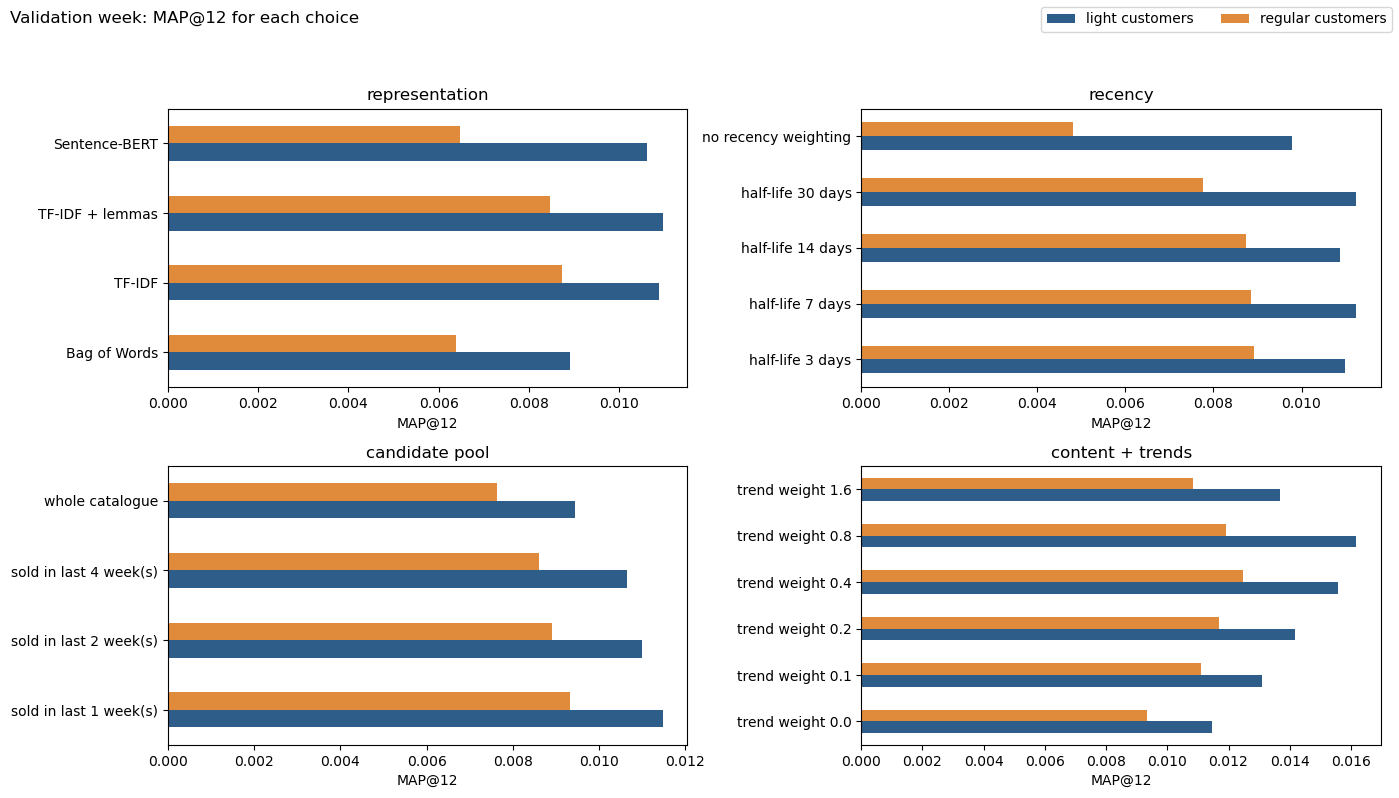

In [55]:
val_log = pd.DataFrame(runs)
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, step in zip(axes.ravel(), ["representation", "recency", "candidate pool", "content + trends"]):
    d = val_log[val_log["step"] == step].set_index("setting")
    d[["MAP@12 light", "MAP@12 regular"]].plot.barh(ax=ax, legend=False, color=["#2F5D8A", "#E08A3C"])
    ax.set_title(step); ax.set_ylabel(""); ax.set_xlabel("MAP@12")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, ["light customers", "regular customers"], loc="upper right", ncol=2)
fig.suptitle("Validation week: MAP@12 for each choice", x=0.01, ha="left", y=0.99)
plt.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

**Chosen settings:** TF-IDF on name + attributes + description, 3-day half-life, candidates sold in the last week, trend weight 0.4, re-buying allowed. Every one of these was picked on the validation week; the test week below has not been looked at yet.

## 4.5 Test week: content against the team's other models

All models are fitted on the full 12 training weeks and scored once on the test week (16 to 22 September 2020) with `evaluate()`. The comparison set:

- **Trending now** and **Trending in age band**: Member 2, two-week window (Member 2's validated choice).
- **Buy again**: Member 2, topped up with the new-customer path.
- **ALS**: Member 3's selected setting (64 factors, regularisation 0.01).
- **Content** and **Content + trends**: this part, with the settings chosen in section 4.4.
- **Content + trends, new-to-you only**: the same model with re-buys switched off, the like-for-like comparison with ALS.

Both content models use Member 2's new-customer path for customers without purchases, so their "new" row matches "Trending in age band" exactly. That's deliberate: the content model only claims the customers it can actually personalise.

In [56]:
final_params = dict(recency_half_life_days=HALF_LIFE, candidate_weeks=POOL_WEEKS,
                    exclude_purchased=EXCLUDE, **rep_params)
fallback = NewCustomerRecommender(weeks=TREND_WEEKS)
models = {
    "Trending now": PopularityRecommender(weeks=TREND_WEEKS),
    "Trending in age band": AgeBandPopularityRecommender(weeks=TREND_WEEKS),
    "Buy again": BuyAgainRecommender(fallback=NewCustomerRecommender(weeks=TREND_WEEKS)),
    "ALS (Member 3)": ALSRecommender(factors=64, regularization=0.01, iterations=15),
    "Content": ContentBasedRecommender(fallback=fallback, **final_params),
    "Content + trends": ContentBasedRecommender(fallback=NewCustomerRecommender(weeks=TREND_WEEKS),
                                                popularity_weight=TREND_WEIGHT, **final_params),
    "Content + trends, new-to-you only": ContentBasedRecommender(
        fallback=NewCustomerRecommender(weeks=TREND_WEEKS), popularity_weight=TREND_WEIGHT,
        **{**final_params, "exclude_purchased": True}),
}
article_info = articles[["article_id", "product_group_name"]]
rows, preds, timing = [], {}, {}
for name, m in models.items():
    t0 = time.time()
    m.fit(train, articles, customers)
    preds[name] = m.recommend_all(list(test_customers))
    res = evaluate(m, test, segments=segments, train=train, articles=article_info)
    timing[name] = time.time() - t0
    rows.append(res.reset_index().assign(model=name))
results = pd.concat(rows, ignore_index=True)
print({k: f"{v:.0f}s" for k, v in timing.items()})
results.set_index(["group", "model"]).loc[["all", "new", "light", "regular"],
    ["n_customers", "MAP@12", "Recall@12", "NDCG@12", "HitRate@12"]]

{'Trending now': '6s', 'Trending in age band': '6s', 'Buy again': '17s', 'ALS (Member 3)': '82s', 'Content': '73s', 'Content + trends': '74s', 'Content + trends, new-to-you only': '75s'}


n_customers  MAP@12  Recall@12  NDCG@12  HitRate@12
group   model                                                                                 
all     Trending now                             68984  0.0072     0.0250   0.0140      0.0613
        Trending in age band                     68984  0.0094     0.0291   0.0173      0.0696
        Buy again                                68984  0.0232     0.0536   0.0352      0.1037
        ALS (Member 3)                           68984  0.0075     0.0205   0.0132      0.0493
        Content                                  68984  0.0236     0.0467   0.0334      0.0860
        Content + trends                         68984  0.0260     0.0530   0.0375      0.0993
        Content + trends, new-to-you only        68984  0.0119     0.0304   0.0199      0.0686
new     Trending now                             19765  0.0072     0.0258   0.0142      0.0620
        Trending in age band                     19765  0.0092     0.0307   0.0176      0.0732
        Buy again                                19765  0.0092     0.0307   0.0176      0.0732
        ALS (Member 3)                           19765  0.0045     0.0147   0.0092      0.0419
        Content                                  19765  0.0092     0.0307   0.0176      0.0732
        Content + trends                         19765  0.0092     0.0307   0.0176      0.0732
        Content + trends, new-to-you only        19765  0.0092     0.0307   0.0176      0.0732
light   Trending now                             16051  0.0080     0.0274   0.0151      0.0599
        Trending in age band                     16051  0.0105     0.0318   0.0184      0.0672
        Buy again                                16051  0.0346     0.0623   0.0456      0.1054
        ALS (Member 3)                           16051  0.0108     0.0256   0.0168      0.0479
        Content                                  16051  0.0331     0.0546   0.0415      0.0791
        Content + trends                         16051  0.0368     0.0633   0.0471      0.0947
        Content + trends, new-to-you only        16051  0.0140     0.0312   0.0210      0.0576
regular Trending now                             33168  0.0068     0.0233   0.0135      0.0615
        Trending in age band                     33168  0.0090     0.0267   0.0165      0.0685
        Buy again                                33168  0.0261     0.0630   0.0407      0.1210
        ALS (Member 3)                           33168  0.0077     0.0215   0.0139      0.0544
        Content                                  33168  0.0276     0.0524   0.0390      0.0970
        Content + trends                         33168  0.0308     0.0613   0.0447      0.1171
        Content + trends, new-to-you only        33168  0.0125     0.0299   0.0208      0.0713

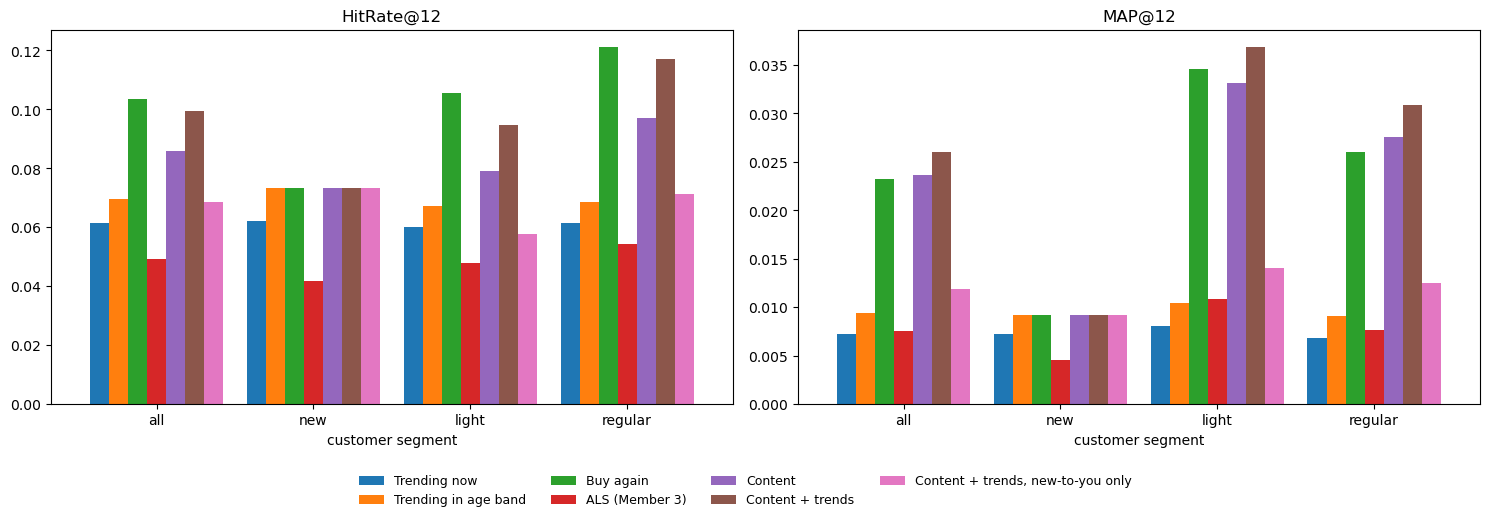

,hit rate vs trending (all),hit rate vs trending (light),hit rate vs trending (regular)
model,,,
Trending now,1.0000,1.0000,1.0000
Trending in age band,1.1351,1.1216,1.1148
Buy again,1.6920,1.7588,1.9686
ALS (Member 3),0.8046,0.7994,0.8847
Content,1.4036,1.3202,1.5777
Content + trends,1.6205,1.5800,1.9049
"Content + trends, new-to-you only",1.1202,0.9605,1.1599


In [57]:
order = list(models)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
for ax, metric in zip(axes, ["HitRate@12", "MAP@12"]):
    (results.pivot(index="group", columns="model", values=metric)
            .loc[["all", "new", "light", "regular"], order].plot.bar(ax=ax, rot=0, width=0.85, legend=False))
    ax.set_title(metric); ax.set_xlabel("customer segment")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, fontsize=9, frameon=False)
plt.tight_layout(rect=(0, 0.1, 1, 1))
plt.show()

head = results.set_index(["group", "model"])
gain = pd.DataFrame({
    seg: head.loc[seg, "HitRate@12"] / head.loc[(seg, "Trending now"), "HitRate@12"]
    for seg in ["all", "light", "regular"]
}).loc[order]
gain.columns = [f"hit rate vs trending ({c})" for c in gain.columns]
gain

**Reading this.** The validation results hold up on the test week.

- **Content + trends ranks better than anything else the team has built.** MAP@12 0.026 overall, against 0.023 for "buy again", 0.009 for trending in age band and 0.008 for ALS. It reaches 1.6 times as many customers as "trending now" (9.9% of test customers buy at least one recommended product, against 6.1%).
- **For light customers specifically**, the segment Member 5 routes to this model, the hit rate goes from 6.0% with "trending now" to 9.5%, and MAP@12 from 0.008 to 0.037.
- **"Buy again" is still the one to respect.** It reaches slightly more customers (10.4% against 9.9%), while content + trends puts the right product higher in the list (higher MAP and NDCG). Section 4.5.1 shows why they're close: they overlap.
- **ALS is weaker than trending on this week**, as Member 3 found. Part of that is that it never repeats a purchase, which section 4.4.5 showed is where a lot of the easy hits are.

New customers get the same list in every content row (Member 2's path), which is why that row matches "Trending in age band" exactly.

### 4.5.1 Where do the hits come from: re-buys or new products?

Re-buys and discovery are different jobs. A re-buy is easy to predict but adds little the customer wouldn't have found anyway; a new product is harder to predict and is where a recommender earns its keep. For every customer with history, I check whether the list hit something they had bought before, something new to them, or both.

In [58]:
past = train[train["customer_id"].isin(test_customers)].groupby("customer_id")["article_id"].agg(set)
actual = test.groupby("customer_id")["article_id"].agg(set)
warm = [c for c in test_customers if segments[c] != "new"]
split = {}
for name in ["Buy again", "ALS (Member 3)", "Content + trends", "Content + trends, new-to-you only"]:
    rebuy = new = 0
    for c in warm:
        hits = set(preds[name][c]) & actual[c]
        rebuy += bool(hits & past[c]); new += bool(hits - past[c])
    split[name] = {"hit on a re-buy (%)": 100 * rebuy / len(warm),
                   "hit on something new to them (%)": 100 * new / len(warm)}
pd.DataFrame(split).T.round(2)

,hit on a re-buy (%),hit on something new to them (%)
Buy again,8.7400,2.9400
ALS (Member 3),0.0000,5.2300
Content + trends,5.9800,5.9100
"Content + trends, new-to-you only",0.0000,6.6800


**Reading this.** The two kinds of hit split cleanly by model:

- **"Buy again"** gets almost all of its hits from re-buys (8.7% of customers with history), and only 2.9% find something new in its list, usually from the trending top-up.
- **Content + trends** is balanced: 6.0% re-buy hits and 5.9% new-product hits. It is the only model that does both jobs reasonably well in one list.
- **For discovery alone**, the new-to-you version is the best model the team has: 6.7% of customers with history buy a product they'd never bought before from it, against 5.2% for ALS, 28% more.

So the honest summary is that content does two things. It finds the basics people re-buy almost as well as "buy again", and it finds *new* products for them better than collaborative filtering. For the hybrid this suggests a split list: a few re-buy slots, and the rest from the new-to-you content model.

## 4.6 Light customers: does a single purchase help?

Light customers bought 1 to 4 items in twelve weeks. Here they're split by exactly how many, to see how fast each model improves as we learn about someone.

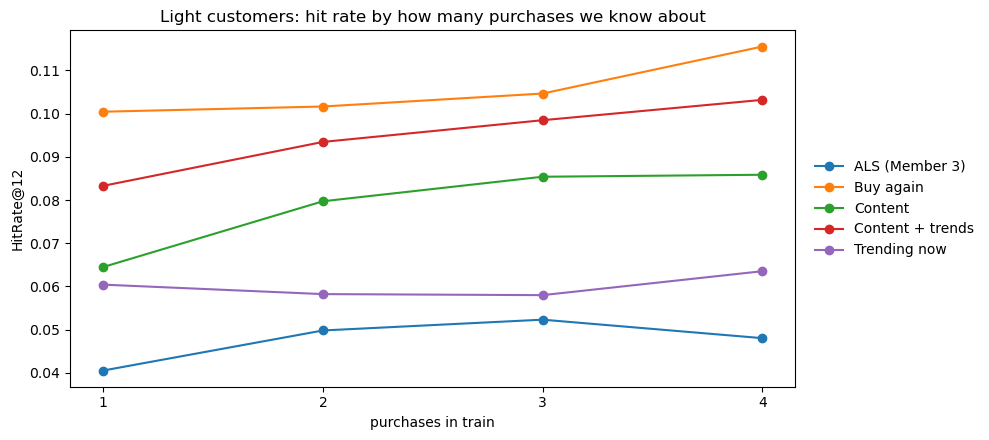

model,ALS (Member 3),Buy again,Content,Content + trends,Trending now,customers
purchases in train,,,,,,
1,0.0406,0.1004,0.0645,0.0833,0.0604,3674
2,0.0498,0.1016,0.0797,0.0934,0.0582,4516
3,0.0523,0.1046,0.0854,0.0985,0.0580,4052
4,0.0480,0.1155,0.0858,0.1032,0.0635,3809


In [59]:
light_ids = segments.index[segments == "light"]
light_test = test[test["customer_id"].isin(light_ids)]
n_bought = train[train["customer_id"].isin(light_ids)].groupby("customer_id").size()
by_history = []
for n in sorted(n_bought.unique()):
    ids = n_bought.index[n_bought == n]
    sub = light_test[light_test["customer_id"].isin(ids)]
    for name in ["Trending now", "Buy again", "ALS (Member 3)", "Content", "Content + trends"]:
        r = evaluate(models[name], sub)
        by_history.append({"purchases in train": n, "model": name, "customers": len(ids),
                           "HitRate@12": r.loc["all", "HitRate@12"]})
by_history = pd.DataFrame(by_history)
ax = by_history.pivot(index="purchases in train", columns="model", values="HitRate@12").plot(
    marker="o", figsize=(10, 4.5))
ax.set_title("Light customers: hit rate by how many purchases we know about")
ax.set_ylabel("HitRate@12"); ax.set_xticks([1, 2, 3, 4])
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False); plt.tight_layout()
plt.show()
by_history.pivot(index="purchases in train", columns="model", values="HitRate@12").assign(
    customers=by_history.groupby("purchases in train")["customers"].first())

**Reading this.** One purchase is already enough for content to beat "trending now" (8.3% against 6.0%), and every extra purchase adds about a point, up to 10.3% at four. ALS stays under trending throughout, since one or two purchases don't place a customer anywhere useful in its factor space. This is the case for routing light customers to content: it's the model that turns a first purchase into a better second visit. "Buy again" is a little higher at every step, so in production I'd show both rows, not one or the other.

## 4.7 Brand-new products

Launches are a blind spot for everything built so far. "Trending now" can't rank a product with no sales, CF has no learned vector for it, and "buy again" never shows anything new. A content model only needs the description, which exists on day one.

**Assumption, stated plainly.** The model needs to know which products are launching. I use the articles that first sell in the test week. In practice the merchandising team knows next week's launches in advance, so this is realistic, but it does use the test week to define the launch list (never to see who bought what).

### 4.7.1 A "new in for you" row

Each customer gets 12 launches. The test is the test week restricted to launch purchases, so the question is "among launches, did we put the ones you bought in front of you?" Two baselines:

- **Random launches**: today's approach, applied to new products.
- **Launches in best-selling types**: no model, no personal data. Rank launches by how well their product type sold last week. This is what a merchandiser would do by hand, and the real bar to clear.

Customers with no purchase history get the launches closest to "what's selling now" (the content profile of last week's sales).

In [60]:
for name in ["ALS (Member 3)", "Trending in age band", "Buy again"]:
    models[name] = None          # scores and lists are kept; the fitted models are not needed any more
gc.collect()

launch_test = test[test["article_id"].isin(launches)]
launch_buyers = pd.Series(launch_test["customer_id"].unique())
launch_segments = segments.loc[launch_buyers]
print(f"{len(launch_buyers):,} test customers bought at least one launch")
print(launch_segments.value_counts().to_string())
buyers_per_launch = launch_test.groupby("article_id")["customer_id"].nunique().sort_values(ascending=False)
print(f"buyers per launch: median {buyers_per_launch.median():.0f}; the 12 biggest launches have "
      f"{buyers_per_launch.iloc[:12].sum() / buyers_per_launch.sum():.0%} of all launch buyers")

launch_info = articles[articles["article_id"].isin(launches)]
launch_models = {
    "Random launches": RandomRecommender(seed=SEED),
    "Launches in best-selling types": AttributePopularityRecommender(launches, weeks=1),
    "Content: launches like your purchases": ContentBasedRecommender(
        candidate_items=launches, only_candidate_items=True, popularity_weight=0.0,
        **{k: v for k, v in final_params.items() if k != "candidate_weeks"}),
}
launch_rows = []
for name, m in launch_models.items():
    m.fit(train, launch_info if name.startswith("Random") else articles, customers)
    r = evaluate(m, launch_test, segments=launch_segments)
    launch_rows.append(r.reset_index().assign(model=name))
launch_results = pd.concat(launch_rows, ignore_index=True)
launch_results.set_index(["group", "model"]).loc[["all", "new", "light", "regular"],
    ["n_customers", "MAP@12", "Recall@12", "HitRate@12"]]

6,134 test customers bought at least one launch
segment
regular    3388
new        1581
light      1165
buyers per launch: median 1; the 12 biggest launches have 29% of all launch buyers


n_customers  MAP@12  Recall@12  HitRate@12
group   model                                                                            
all     Random launches                               6134  0.0040     0.0131      0.0189
        Launches in best-selling types                6134  0.0028     0.0066      0.0098
        Content: launches like your purchases         6134  0.0244     0.0620      0.0706
new     Random launches                               1581  0.0041     0.0127      0.0183
        Launches in best-selling types                1581  0.0024     0.0061      0.0089
        Content: launches like your purchases         1581  0.0110     0.0343      0.0392
light   Random launches                               1165  0.0047     0.0145      0.0206
        Launches in best-selling types                1165  0.0013     0.0044      0.0060
        Content: launches like your purchases         1165  0.0259     0.0673      0.0738
regular Random launches                               3388  0.0037     0.0129      0.0186
        Launches in best-selling types                3388  0.0036     0.0076      0.0115
        Content: launches like your purchases         3388  0.0301     0.0731      0.0841

**Reading this.** The personal launch row works: 7.1% of launch buyers had one of their launches in their 12 slots, against 1.9% with random launches, so **3.7 times as many**. MAP@12 goes from 0.004 to 0.024. It helps most for regular customers (8.4%), where the profile is richest, but even customers with no history do twice as well as random (3.9% against 1.8%) just from "launches that look like what's selling now".

The merchandiser rule does *worse than random* (1.0%), which surprised me. The reason is in how launches sell. Demand is extremely concentrated: the 12 biggest launches account for 29% of all launch buyers, and the median launch had a single buyer all week. Knowing that sweaters sell tells you nothing about *which* of the dozens of new sweaters will be the hit. Matching a launch to people who already buy that kind of product does tell you something.

About half the launches (48%) are new colours or versions of products that were already selling, which probably makes this easier: a customer who bought the black version is an obvious candidate for the new beige one. The other 52% are product codes that hadn't sold at all in the twelve weeks.

### 4.7.2 Launch audiences: who should hear about a new product?

The same model, read the other way round. For each launch, rank every customer with purchase history by how well their profile matches the product, and pick the top 1,000, the size of a targeted email or app push. A hit is a targeted customer who bought that launch in the test week.

Baselines: 1,000 random customers (the expected number of buyers is computable exactly) and the 1,000 most active customers of the last four weeks, who are likelier to buy *anything*. That second one is the honest comparison, since heavy shoppers inflate any targeting rule.

In [61]:
content_model = models["Content"]
known = pd.Index(content_model.customer_index_)
buyers_by_item = (launch_test[launch_test["customer_id"].isin(known)]
                  .groupby("article_id")["customer_id"].agg(set))
items = buyers_by_item.index.tolist()
N = 1000
recent_activity = train[train["t_dat"] > train["t_dat"].max() - pd.Timedelta(weeks=4)]
active = recent_activity.groupby("customer_id").size().sort_values(ascending=False)

t0 = time.time()
aud_all = content_model.audience(items, n=N)
aud_active = content_model.audience(items, n=N, universe=active.index)
aud_top5k = content_model.audience(items, n=N, universe=active.index[:5_000])
aud_top20k = content_model.audience(items, n=N, universe=active.index[:20_000])
print(f"audiences for {len(items)} launches in {time.time() - t0:.0f}s")

most_active = set(active.index[:N])
tot_buyers = sum(len(b) for b in buyers_by_item)
rows = {
    "Random customers (expected)": tot_buyers * N / len(known),
    "Most active customers": sum(len(b & most_active) for b in buyers_by_item),
    "Content match, all customers": sum(len(b & set(aud_all[i])) for i, b in buyers_by_item.items()),
    "Content match, active in last 4 weeks": sum(len(b & set(aud_active[i]))
                                                 for i, b in buyers_by_item.items()),
    "Content match within the 20,000 most active": sum(len(b & set(aud_top20k[i]))
                                                       for i, b in buyers_by_item.items()),
    "Content match within the 5,000 most active": sum(len(b & set(aud_top5k[i]))
                                                      for i, b in buyers_by_item.items()),
}
audience_table = pd.DataFrame({"buyers reached": rows})
audience_table["share of launch buyers reached"] = audience_table["buyers reached"] / tot_buyers
audience_table["lift vs random"] = audience_table["buyers reached"] / rows["Random customers (expected)"]
print(f"{len(items)} launches, {tot_buyers:,} (launch, buyer) pairs among {len(known):,} known customers; "
      f"each campaign targets {N:,} customers ({N / len(known):.2%} of them)")
audience_table

audiences for 784 launches in 36s
784 launches, 6,429 (launch, buyer) pairs among 505,310 known customers; each campaign targets 1,000 customers (0.20% of them)


,buyers reached,share of launch buyers reached,lift vs random
Random customers (expected),12.7229,0.0020,1.0000
Most active customers,175.0000,0.0272,13.7547
"Content match, all customers",133.0000,0.0207,10.4536
"Content match, active in last 4 weeks",143.0000,0.0222,11.2396
"Content match within the 20,000 most active",194.0000,0.0302,15.2481
"Content match within the 5,000 most active",215.0000,0.0334,16.8987


**Reading this.** Content targeting reaches 10 times more launch buyers than a random mailing (133 against an expected 13), but on its own it loses to the blunt rule "email your 1,000 most active customers" (175). Heavy shoppers buy a bit of everything, including launches.

The two ideas combine well. Taking the 5,000 most active customers and then choosing, for each launch, the 1,000 whose taste matches it best reaches **215 buyers: 23% more than "most active" and 17 times random.** Same campaign size, same cost per message, better aim, and each of those customers gets launches they're likely to care about instead of all of them.

A caveat on scale: 784 launches with buyers, 6,429 launch purchases among half a million known customers. These are small absolute numbers, and a single test week. The lift is large enough that I'd trust its direction, not the exact percentage.

## 4.8 Diversity and novelty: is it all black T-shirts?

The risk with content is obvious. If someone bought a black T-shirt, the most similar products are other black T-shirts, starting with the same T-shirt in other colours. I measure each list directly, for customers with history:

- distinct product types and colours in the 12 slots,
- the share of slots taken by the list's most common colour,
- how many slots are colour variants of a product already in the list,
- the share of black items.

The customer's own last 12 purchases give the reference. A list that's narrower than what the person actually buys is a filter bubble; one that matches it is just accurate.

To test a fix, one more version of content + trends keeps **one colour per product** (`one_per_product=True`): only the best-scoring variant of each `product_code` makes the list.

In [62]:
known_test = [c for c in test_customers if segments[c] != "new"]
colour = info["colour_group_name"].to_dict(); ptype = info["product_type_name"].to_dict()
pcode = info["product_code"].to_dict(); master = info["perceived_colour_master_name"].to_dict()

def list_profile(lists):
    """Per-list diversity numbers, averaged over customers."""
    out = []
    for items in lists:
        cols = [colour[i] for i in items]; types = [ptype[i] for i in items]
        top_colour_share = pd.Series(cols).value_counts().iloc[0] / len(items)
        out.append({"distinct product types": len(set(types)),
                    "distinct colours": len(set(cols)),
                    "share of slots in the top colour": top_colour_share,
                    "colour variants of the same product": len(items) - len({pcode[i] for i in items}),
                    "share black": np.mean([master[i] == "Black" for i in items])})
    return pd.DataFrame(out).mean()

own = (train[train["customer_id"].isin(known_test)].sort_values("t_dat")
       .groupby("customer_id")["article_id"].agg(lambda s: list(dict.fromkeys(s))[-12:]))
own = own[own.str.len() >= 5]
div = {"What they bought (last 12, 5+ items)": list_profile(own)}
models["Content + trends, one colour per product"] = ContentBasedRecommender(
    fallback=NewCustomerRecommender(weeks=TREND_WEEKS), one_per_product=True,
    popularity_weight=TREND_WEIGHT, **final_params).fit(train, articles, customers)
preds["Content + trends, one colour per product"] = models["Content + trends, one colour per product"].recommend_all(
    list(test_customers))
for name in ["Trending now", "Buy again", "ALS (Member 3)", "Content", "Content + trends",
             "Content + trends, new-to-you only", "Content + trends, one colour per product"]:
    div[name] = list_profile([preds[name][c] for c in known_test])
diversity_table = pd.DataFrame(div).T
diversity_table

,distinct product types,distinct colours,share of slots in the top colour,colour variants of the same product,share black
"What they bought (last 12, 5+ items)",5.9258,5.7782,0.3872,0.7828,0.3237
Trending now,6.0000,4.0000,0.5833,1.0000,0.5833
Buy again,7.0172,6.0232,0.4230,0.9309,0.4047
ALS (Member 3),4.3505,5.5951,0.4543,3.2450,0.4086
Content,1.9743,5.9922,0.4194,6.2762,0.3081
Content + trends,2.2129,5.8720,0.4415,5.7352,0.3651
"Content + trends, new-to-you only",2.2266,5.9576,0.4385,5.1449,0.3664
"Content + trends, one colour per product",2.9752,4.2118,0.5953,0.0039,0.4868


In [63]:
r = evaluate(models["Content + trends, one colour per product"], test, segments=segments, train=train,
             articles=article_info)
results = pd.concat([results, r.reset_index().assign(model="Content + trends, one colour per product")],
                    ignore_index=True)
beyond = (results[results["group"] == "all"].set_index("model")
          [["MAP@12", "HitRate@12", "coverage", "gini", "diversity", "novelty"]])
beyond

,MAP@12,HitRate@12,coverage,gini,diversity,novelty
model,,,,,,
Trending now,0.0072,0.0613,0.0001,0.0000,0.2500,10.5660
Trending in age band,0.0094,0.0696,0.0004,0.4227,0.2440,10.8643
Buy again,0.0232,0.1037,0.2445,0.8667,0.2888,11.9107
ALS (Member 3),0.0075,0.0493,0.0330,0.7779,0.2725,11.1926
Content,0.0236,0.0860,0.1699,0.7194,0.1576,13.3042
Content + trends,0.0260,0.0993,0.1504,0.8295,0.1645,12.5539
"Content + trends, new-to-you only",0.0119,0.0686,0.1395,0.8379,0.1634,12.5839
"Content + trends, one colour per product",0.0226,0.0898,0.1213,0.8738,0.1827,12.4574


**Reading this.** "All black T-shirts" is the wrong worry, and the real problem is worse.

- **Colour is fine.** Content lists hold about 6 colours out of 12 slots, the same as what customers actually buy, and only 37% black against 58% in "trending now" (which happens to be full of black basics).
- **Variety of products is not.** Content + trends shows on average **5.7 colour variants** of products already in the list, so a typical list is five or six products in two colours each. It covers only 2.2 product types, while the same customers bought 5.9 types over their last 12 purchases. The "same T-shirt in five colours" effect from section 4.3.1 shows up directly in the lists, and the evaluator's product-group diversity agrees (0.16, the lowest of any model).
- **Keeping one colour per product fixes the duplicates but costs accuracy.** Variants drop to almost zero and product types rise to 3.0, but MAP@12 falls from 0.026 to 0.023 and the hit rate from 9.9% to 9.0%. Some customers really do buy the same piece in another colour. The list also gets *darker* (49% black), because the slots freed up go to the next most similar items, and those tend to be black basics.
- **Beyond accuracy it's not all bad.** Content + trends shows 15% of the catalogue (trending shows 12 items to everyone) and recommends less obvious products: novelty 12.6 bits against 10.6 for trending and 11.9 for buy again.

My recommendation for the hybrid: keep the variants, but cap them, for example two colours per product per list, and let the slots that frees go to a different product type. That's a business choice between short-term clicks and a shop that feels narrower than it is, so I'd test it in Member 5's A/B plan rather than decide it here.

## 4.9 Why this product? Explanations for one light customer

Content recommendations are easy to explain, which matters for trust and for the CEO demo. `explain()` finds the past purchases most similar to a recommended product, giving a "because you bought..." line. Below is a light customer the content + trends model got right and "trending now" missed.

In [64]:
cm = models["Content + trends"]
light_hits = [c for c in light_ids
              if (set(preds["Content + trends"][c]) & actual[c]) - past[c]
              and not set(preds["Trending now"][c]) & actual[c]]
richer = [c for c in light_hits if n_bought[c] >= 3]       # an example with a bit of history
print(f"light customers where Content + trends found something new to them "
      f"that Trending now missed: {len(light_hits):,}")
cid = (richer or light_hits)[0]
bought_next = set(test.loc[test["customer_id"] == cid, "article_id"])
cols = ["prod_name", "product_type_name", "colour_group_name"]

bought_on = (train[train["customer_id"] == cid].groupby("article_id")["t_dat"].max()
             .dt.strftime("%d %b").rename("last bought"))
hist = (cm.history(cid).merge(info[cols], left_on="article_id", right_index=True)
          .join(bought_on, on="article_id"))
hist["share of profile"] = (hist["weight"] / hist["weight"].sum()).round(3)
print("\nWhat this customer bought (weight: how much it counts on 15 Sep, 3-day half-life):")
display(hist)
recs = pd.DataFrame({"article_id": preds["Content + trends"][cid]}).merge(
    info[cols], left_on="article_id", right_index=True)
recs["bought in test week"] = recs["article_id"].isin(bought_next)
print("What Content + trends shows them:")
display(recs)
hit = recs.loc[recs["bought in test week"] & ~recs["article_id"].isin(past[cid]), "article_id"].iloc[0]
why = cm.explain(cid, hit, top=2).merge(info[["prod_name"]], left_on="article_id", right_index=True)
print(f'"{info.loc[hit, "prod_name"]}" was recommended because you bought:')
display(why)

light customers where Content + trends found something new to them that Trending now missed: 771

What this customer bought (weight: how much it counts on 15 Sep, 3-day half-life):


,article_id,weight,prod_name,product_type_name,colour_group_name,last bought,share of profile
0,865240001,0.0787,Flirty Silja earcuff,Other accessories,Gold,04 Sep,0.3330
1,915529001,0.0787,Liliana,Sweater,Beige,04 Sep,0.3330
2,916598001,0.0787,Renee PU,Blouse,Black,04 Sep,0.3330


What Content + trends shows them:


,article_id,prod_name,product_type_name,colour_group_name,bought in test week
0,915529003,Liliana,Sweater,Black,False
1,915529001,Liliana,Sweater,Beige,False
2,915529005,Liliana,Sweater,Beige,False
3,916598001,Renee PU,Blouse,Black,False
4,863646001,Matey,Sweater,Black,True
5,918525001,Frill cable,Sweater,Beige,False
6,920283001,Liliana fluff,Sweater,White,False
7,893141002,Sandy,Sweater,Beige,False
8,863646004,Matey,Sweater,Beige,False
9,911870001,Bama1,Sweater,Black,False


"Matey" was recommended because you bought:


,article_id,weight,similarity,prod_name
0,915529001,0.0787,0.6234,Liliana
1,916598001,0.0787,0.1896,Renee PU


**Reading this.** This customer bought three things on 4 September: an ear cuff, a beige "Liliana" sweater and a black blouse. The model shows the Liliana in other colours, the blouse again, and a run of similar knitwear. They bought the "Matey" sweater, and the explanation is the one a shop assistant would give: it's 0.62 similar to the Liliana they already own.

The example also shows the model's habits from sections 5 and 8 in one list. Four of the 12 slots are Liliana variants or the blouse they already have, and the ear cuff, a third of the profile, leaves no visible trace: knitwear dominates the similarity scores and the trend bonus, so accessories never make it in. A cap on variants and a slot reserved for a second product type would both have helped here.

## 4.10 What this means for the business

For the CEO, in plain terms:

1. **A product's description is a usable signal from day one.** Turning name, attributes and description into a "taste profile" makes recommendations for anyone who has bought at least once, and it needs no data about the person beyond their purchases.
2. **It's the best model we have for occasional shoppers.** Light customers are 23% of this week's buyers. Content + trends gets 9.5% of them to buy something from their list, against 6.0% for the best-seller list and 4.8% for collaborative filtering.
3. **It's the only model that can sell new products.** Each week about 4% of purchases are products nobody had bought before. A "new in for you" row gets 3.7 times as many of those into the right hands as a random display, and the same model aims launch emails 23% better than "mail the best customers".
4. **The cost is variety, and it's fixable.** Unchecked, a list can show the same product in five colours. Capping colour variants trades a little accuracy for a shop that looks as big as it is; the A/B test should measure both sides.

The table below is the one-line version: share of customers in each segment who bought at least one recommended product.

In [65]:
summary = results.set_index(["group", "model"])["HitRate@12"].unstack(0)[["all", "new", "light", "regular"]]
summary = summary.loc[[m for m in [*order, "Content + trends, one colour per product"] if m in summary.index]]
summary.columns = [f"hit rate: {c}" for c in summary.columns]
summary

,hit rate: all,hit rate: new,hit rate: light,hit rate: regular
model,,,,
Trending now,0.0613,0.0620,0.0599,0.0615
Trending in age band,0.0696,0.0732,0.0672,0.0685
Buy again,0.1037,0.0732,0.1054,0.1210
ALS (Member 3),0.0493,0.0419,0.0479,0.0544
Content,0.0860,0.0732,0.0791,0.0970
Content + trends,0.0993,0.0732,0.0947,0.1171
"Content + trends, new-to-you only",0.0686,0.0732,0.0576,0.0713
"Content + trends, one colour per product",0.0898,0.0732,0.0794,0.1048


## 4.11 Limits, ethics and AI use

**Limits worth saying out loud**

- One test week, in late September. Fashion is seasonal, and a winter week could rank the settings differently.
- "Sold last week" stands in for stock. It's the main reason the candidate pool helps, and a real stock feed would do it properly.
- The launch list comes from the test week (see section 4.7). That's realistic for a retailer but it is still knowledge the model is handed, not something it learned.
- Content only knows what's written. Two dresses with the same description and a very different look are twins to this model; the product images, which this project didn't use, would be the next signal to add.
- Recommending what people already bought is accurate and also a little lazy. The hybrid should decide how many re-buy slots a list gets on purpose, not let accuracy decide it by default.

**Ethics.** The content model itself only uses what a customer bought and what H&M wrote about its products: no age, no postcode, no inferred traits (age only enters through Member 2's fallback for people with no purchases). That makes it easy to explain to a customer and low-risk from a privacy point of view. The risk it does carry is narrowing, which section 4.8 measures and the A/B test should keep an eye on.

*Claude was used to help write code and commentary.*

## 4.12 Named entity recognition (NER)

In [66]:
nlp_ner = spacy.load('en_core_web_sm', exclude=['tagger', 'parser', 'attribute_ruler', 'lemmatizer'])


def get_entities(doc):  # S16 NER, on spaCy docs so all descriptions run in batches
  return [(e.text, e.label_) for e in doc.ents]


descriptions = articles['detail_desc'].fillna('')
unique_descriptions = descriptions.drop_duplicates().tolist()
entity_lookup = {text: get_entities(doc) for text, doc in zip(unique_descriptions,
                                                              nlp_ner.pipe(unique_descriptions, batch_size=500))}
article_entities = descriptions.map(entity_lookup)

entity_rows = pd.DataFrame([entity for entities in article_entities for entity in entities], columns=['entity', 'label'])
print(f'Products with at least one named entity: {(article_entities.str.len() > 0).mean():.1%}')
display(entity_rows['label'].value_counts().head(8).rename('mentions').to_frame().T)
entity_rows.groupby(['label', 'entity']).size().sort_values(ascending=False).head(10).rename('mentions').reset_index()

Products with at least one named entity: 42.2%


label,PERSON,CARDINAL,GPE,ORG,QUANTITY,NORP,PRODUCT,DATE
mentions,16639,15867,10732,7613,6458,1577,430,260


,label,entity,mentions
0,GPE,cotton jersey,6159
1,CARDINAL,one,3944
2,CARDINAL,5,3347
3,PERSON,cotton jersey,2806
4,ORG,Jumper,2260
5,CARDINAL,3/4,1985
6,CARDINAL,two,1830
7,GPE,jersey,1564
8,PERSON,Width,1327
9,PERSON,Jersey,1299


In [67]:
articles_entities = articles.assign(detail_desc=article_entities.map(lambda entities: ' '.join(e for e, _ in entities)))
ner_params = dict(recency_half_life_days=HALF_LIFE, candidate_weeks=POOL_WEEKS, text_fields=['description'])

ner_results = {}
for name, source in {'TF-IDF on full descriptions': articles, 'TF-IDF on named entities only': articles_entities}.items():
  ner_model = ContentBasedRecommender(fallback=NewCustomerRecommender(weeks=TREND_WEEKS), **ner_params).fit(fit_part, source, customers)
  ner_results[name] = evaluate(ner_model, val_sample, train=fit_part).loc['all', ['MAP@12', 'HitRate@12']]

pd.DataFrame(ner_results).T

,MAP@12,HitRate@12
TF-IDF on full descriptions,0.0083,0.0486
TF-IDF on named entities only,0.0031,0.0240


**Finding.** spaCy finds a named entity in 42.2% of products, but many are wrong for fashion, such as "cotton jersey" labelled as a place. Using only the entities lowers validation MAP@12 from 0.0083 to 0.0031, so NER is not part of the final system.

In [68]:
free('models', 'preds', 'launch_models', 'content_model', 'aud_all', 'aud_active', 'aud_top5k', 'aud_top20k', 'past', 'actual', 'own', 'cm', 'sbert', 'texts', 'lemma_texts', 'nlp_ner', 'entity_lookup', 'article_entities', 'entity_rows', 'articles_entities', 'ner_model', 'runs', 'colour', 'ptype', 'pcode', 'master', 'val_fallback', 'fallback', 'known_test')
_LEMMA_CACHE.clear()
gc.collect();

# Part 5. Hybrid recommender

**Lead:** Jade Beeks (Member 5)

### Code: switching and weighted hybrids

In [69]:
from __future__ import annotations

import pandas as pd


class SwitchingHybrid(Recommender):  # S06 slide 21: one RS per user group, chosen by amount of feedback
    name = "switching_hybrid"

    def __init__(self, new_model: Recommender, light_model: Recommender, regular_model: Recommender):
        self.new_model = new_model
        self.light_model = light_model
        self.regular_model = regular_model

    def fit(self, train, articles=None, customers=None):
        self.models_ = {"new": self.new_model, "light": self.light_model, "regular": self.regular_model}
        fitted = set()
        for model in self.models_.values():
            if id(model) not in fitted:
                model.fit(train, articles, customers)
                fitted.add(id(model))
        self.history_ = train[["customer_id"]]
        return self

    def segments(self, customer_ids) -> pd.Series:
        ids = pd.Series([str(c) for c in customer_ids])
        return pd.Series(assign_segments(self.history_, ids).astype(str).to_numpy(), index=ids)

    def recommend_all(self, customer_ids, k=12):
        segs = self.segments(customer_ids)
        out = {}
        for label, model in self.models_.items():
            group = segs.index[segs == label].tolist()
            if group:
                out.update(model.recommend_all(group, k=k))
        return {c: out[c] for c in segs.index}

    def recommend(self, customer_id, k=12):
        return self.recommend_all([customer_id], k)[str(customer_id)]


class WeightedHybrid(Recommender):  # S06 slides 20 + 22: rank points per RS times a weight, equal weights = mixed
    name = "weighted_hybrid"

    def __init__(self, models: list[Recommender], weights: list[float] | None = None, n: int | None = None):
        self.models = models
        self.weights = weights if weights is not None else [1.0] * len(models)
        self.n = n

    def fit(self, train, articles=None, customers=None):
        fitted = set()
        for model in self.models:
            if id(model) not in fitted:
                model.fit(train, articles, customers)
                fitted.add(id(model))
        return self

    @staticmethod
    def rank_points(ranked_lists, weights):
        points = {}
        for weight, items in zip(weights, ranked_lists):
            for pos, item in enumerate(items):
                points[item] = points.get(item, 0) + weight * (len(items) - pos)
        return points

    def recommend_all(self, customer_ids, k=12):
        ids = [str(c) for c in customer_ids]
        lists = [model.recommend_all(ids, k=self.n or k) for model in self.models]
        out = {}
        for c in ids:
            points = self.rank_points([rec[c] for rec in lists], self.weights)
            out[c] = sorted(points, key=points.get, reverse=True)[:k]
        return out

    def recommend(self, customer_id, k=12):
        return self.recommend_all([customer_id], k)[str(customer_id)]

In [70]:
np.random.seed(my_seed)

In [71]:
def basic_stats(ratings_df, user_col, item_col):
  n_ratings = ratings_df.shape[0]
  n_users = ratings_df[user_col].nunique()
  n_items = ratings_df[item_col].nunique()
  print(f'There are {n_ratings} ratings from {n_users} users to {n_items} items')
  return n_ratings, n_users, n_items

basic_stats(train, 'customer_id', 'article_id');
basic_stats(test, 'customer_id', 'article_id');

There are 3664080 ratings from 505310 users to 41376 items
There are 240311 ratings from 68984 users to 17986 items


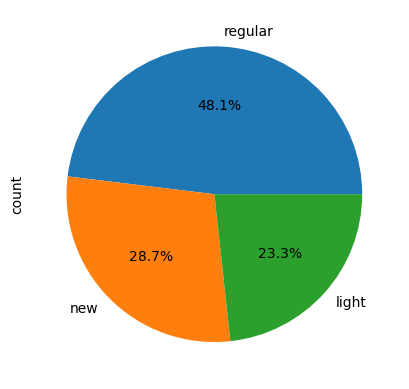

In [72]:
segments.value_counts().plot.pie(autopct='%1.1f%%');

## 5.1 Switching hybrid

### 5.1.1 Choosing the model for each segment on the validation week

In [73]:
val_start = train['t_dat'].max().normalize() - pd.Timedelta(days=6)
fit_part = train[train['t_dat'] < val_start]
val_part = train[train['t_dat'] >= val_start]
val_ids = val_part['customer_id'].drop_duplicates().sample(n=20_000, random_state=VAL_SEED)
val_sample = val_part[val_part['customer_id'].isin(val_ids)]

basic_stats(fit_part, 'customer_id', 'article_id');
basic_stats(val_sample, 'customer_id', 'article_id');

There are 3408839 ratings from 483961 users to 40183 items
There are 70342 ratings from 20000 users to 11736 items


In [74]:
def content_trends():
  return ContentBasedRecommender(recency_half_life_days=3, candidate_weeks=1, popularity_weight=0.4,
                                 exclude_purchased=False, fallback=NewCustomerRecommender(weeks=TREND_WEEKS))

candidates = {
    'Trending now': lambda: PopularityRecommender(weeks=TREND_WEEKS),
    'Buy again': lambda: BuyAgainRecommender(fallback=NewCustomerRecommender(weeks=TREND_WEEKS)),
    'Content + trends': content_trends,
    'ALS': lambda: ALSRecommender(factors=64, regularization=0.01, iterations=15),
    'Item-item CF': lambda: ItemItemCF(n_neighbors=100),
}

In [75]:
%%time
val_results = {}
for name, make in candidates.items():
  model = make().fit(fit_part, articles, customers)
  val_results[name] = evaluate(model, val_sample, train=fit_part)

val_df = pd.concat(val_results, names=['model'])
val_df['MAP@12'].unstack('group')[['all', 'new', 'light', 'regular']]

CPU times: user 2min 2s, sys: 4.56 s, total: 2min 6s
Wall time: 1min 39s


group,all,new,light,regular
model,,,,
Trending now,0.0074,0.0076,0.0080,0.0069
Buy again,0.0221,0.0087,0.0330,0.0251
Content + trends,0.0247,0.0087,0.0358,0.0293
ALS,0.0079,0.0049,0.0116,0.0079
Item-item CF,0.0077,0.0049,0.0108,0.0078


In [76]:
best_per_segment = val_df['MAP@12'].unstack('group')[['light', 'regular']].idxmax()
best_per_segment

group
light      Content + trends
regular    Content + trends
dtype: object

**Finding.** On the validation week, Content + trends ranks best for both light and regular customers (MAP@12 0.0358 and 0.0293). New customers keep the age-band trends because they have no history for a personal model to use.

### 5.1.2 Test week

In [77]:
content = content_trends()
switching_RS = SwitchingHybrid(new_model=NewCustomerRecommender(weeks=TREND_WEEKS),
                               light_model=content,
                               regular_model=content)

models = {
    'Random (today)': RandomRecommender(),
    'Trending now': PopularityRecommender(weeks=TREND_WEEKS),
    'Buy again': BuyAgainRecommender(fallback=NewCustomerRecommender(weeks=TREND_WEEKS)),
    'Switching hybrid': switching_RS,
}

In [78]:
%%time
test_results = {}
for name, model in models.items():
  model.fit(train, articles, customers)
  test_results[name] = evaluate(model, test, segments=segments, train=train, articles=articles)

results_df = pd.concat(test_results, names=['model'])
results_df

CPU times: user 1min 10s, sys: 3.46 s, total: 1min 14s
Wall time: 1min 14s


n_customers  MAP@12  Recall@12  NDCG@12  HitRate@12  coverage   gini  diversity  novelty
model            group                                                                                            
Random (today)   all            68984  0.0000     0.0001   0.0000      0.0003    0.9996 0.1998     0.4310  20.1911
                 new            19765  0.0000     0.0001   0.0001      0.0003    0.8945 0.2908     0.4309  20.1883
                 light          16051  0.0000     0.0002   0.0001      0.0004    0.8381 0.2881     0.4307  20.1951
                 regular        33168  0.0000     0.0000   0.0000      0.0002    0.9767 0.2688     0.4311  20.1907
Trending now     all            68984  0.0072     0.0250   0.0140      0.0613    0.0001 0.0000     0.2500  10.5660
                 new            19765  0.0072     0.0258   0.0142      0.0620    0.0001 0.0000     0.2500  10.5660
                 light          16051  0.0080     0.0274   0.0151      0.0599    0.0001 0.0000     0.2500  10.5660
                 regular        33168  0.0068     0.0233   0.0135      0.0615    0.0001 0.0000     0.2500  10.5660
Buy again        all            68984  0.0232     0.0536   0.0352      0.1037    0.2445 0.8667     0.2888  11.9107
                 new            19765  0.0092     0.0307   0.0176      0.0732    0.0004 0.4146     0.2432  10.8681
                 light          16051  0.0346     0.0623   0.0456      0.1054    0.1101 0.9004     0.2712  11.2594
                 regular        33168  0.0261     0.0630   0.0407      0.1210    0.2380 0.7476     0.3246  12.8472
Switching hybrid all            68984  0.0260     0.0530   0.0375      0.0993    0.1504 0.8295     0.1645  12.5539
                 new            19765  0.0092     0.0307   0.0176      0.0732    0.0004 0.4146     0.2432  10.8681
                 light          16051  0.0368     0.0633   0.0471      0.0947    0.1287 0.6860     0.1252  13.3790
                 regular        33168  0.0308     0.0613   0.0447      0.1171    0.1393 0.7708     0.1367  13.1592

**Finding.** The first switching plan has the best ranking so far (MAP@12 0.0260), but it reaches fewer shoppers than Buy Again (9.93% against 10.37%). Choosing one model per group loses the repeat purchases that Buy Again catches, so we test blending the two.

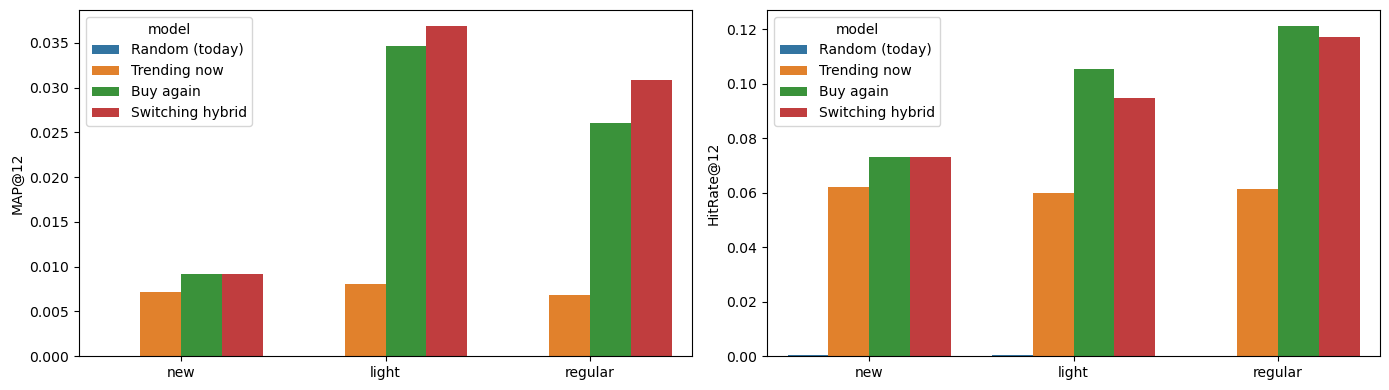

In [79]:
plot_df = results_df[['MAP@12', 'HitRate@12']].reset_index()
plot_df = plot_df[plot_df['group'] != 'all']

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, metric in zip(axes, ['MAP@12', 'HitRate@12']):
  sns.barplot(data=plot_df, x='group', y=metric, hue='model', ax=ax)
  ax.set_xlabel('')
plt.tight_layout()
plt.show();

## 5.2 Weighted and mixed hybrid

### 5.2.1 Rank points (S06 slide 22 example)

In [80]:
points = WeightedHybrid.rank_points([['D', 'A', 'B', 'C'], ['A', 'B', 'D', 'C']], [1, 1])
points, sorted(points, key=points.get, reverse=True)

({'D': 6, 'A': 7, 'B': 5, 'C': 2}, ['A', 'D', 'B', 'C'])

### 5.2.2 Choosing the weight on the validation week

In [81]:
%%time
content_val = content_trends().fit(fit_part, articles, customers)
buy_again_val = BuyAgainRecommender(fallback=NewCustomerRecommender(weeks=TREND_WEEKS)).fit(fit_part, articles, customers)

weights = [1.0, 0.8, 0.6, 0.5, 0.4, 0.2, 0.0]
weight_results = {}
for w in weights:
  hybrid_val = WeightedHybrid([content_val, buy_again_val], [w, 1 - w])
  weight_results[w] = evaluate(hybrid_val, val_sample, train=fit_part)

weight_df = pd.concat(weight_results, names=['content_weight'])
weight_df['MAP@12'].unstack('group')[['all', 'light', 'regular']]

CPU times: user 1min 37s, sys: 6.07 s, total: 1min 43s
Wall time: 1min 43s


group,all,light,regular
content_weight,,,
1.0000,0.0247,0.0358,0.0293
0.8000,0.0257,0.0367,0.0310
0.6000,0.0267,0.0378,0.0324
0.5000,0.0268,0.0378,0.0327
0.4000,0.0258,0.0357,0.0317
0.2000,0.0246,0.0345,0.0295
0.0000,0.0221,0.0330,0.0251


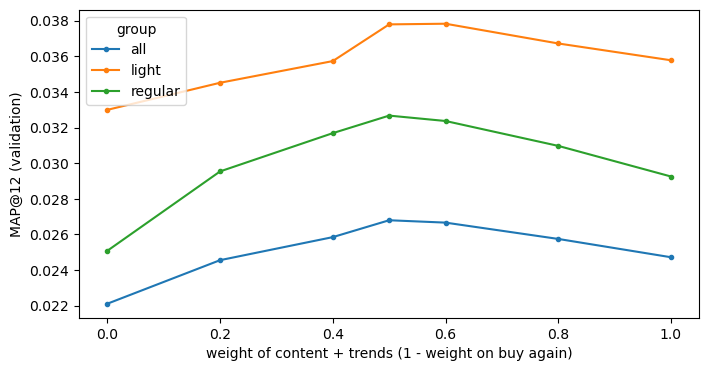

In [82]:
fig, ax = plt.subplots(figsize=(8, 4))
weight_df['MAP@12'].unstack('group')[['all', 'light', 'regular']].plot(marker='.', ax=ax)
ax.set_xlabel('weight of content + trends (1 - weight on buy again)')
ax.set_ylabel('MAP@12 (validation)')
plt.show();

In [83]:
best_weight = weight_df['MAP@12'].unstack('group')[['light', 'regular']].idxmax()
best_weight

group
light     0.6000
regular   0.5000
dtype: float64

**Finding.** A 50/50 blend gives the highest overall validation MAP@12 (0.0268), above Content + trends alone (0.0247) and Buy Again alone (0.0221). Light customers score the same at 0.5 and 0.6 to four decimals, so we use one simple 50/50 rule for both groups.

### 5.2.3 Final system on the test week

In [84]:
mixed_RS = WeightedHybrid([content, models['Buy again']], [0.5, 0.5])
final_RS = SwitchingHybrid(new_model=NewCustomerRecommender(weeks=TREND_WEEKS),
                           light_model=mixed_RS,
                           regular_model=mixed_RS)

In [85]:
%%time
fit_start = time.perf_counter()
final_RS.fit(train, articles, customers)
fit_seconds = time.perf_counter() - fit_start
test_results['Switching + mixed hybrid'] = evaluate(final_RS, test, segments=segments, train=train, articles=articles)

results_df = pd.concat(test_results, names=['model'])
results_df.xs('all', level='group')

CPU times: user 55.5 s, sys: 3.45 s, total: 59 s
Wall time: 59.5 s


,n_customers,MAP@12,Recall@12,NDCG@12,HitRate@12,coverage,gini,diversity,novelty
model,,,,,,,,,
Random (today),68984,0.0000,0.0001,0.0000,0.0003,0.9996,0.1998,0.4310,20.1911
Trending now,68984,0.0072,0.0250,0.0140,0.0613,0.0001,0.0000,0.2500,10.5660
Buy again,68984,0.0232,0.0536,0.0352,0.1037,0.2445,0.8667,0.2888,11.9107
Switching hybrid,68984,0.0260,0.0530,0.0375,0.0993,0.1504,0.8295,0.1645,12.5539
Switching + mixed hybrid,68984,0.0278,0.0592,0.0405,0.1097,0.2304,0.8465,0.2577,12.3503


**Finding.** The final system is the best on all four accuracy metrics: MAP@12 0.0278, Recall@12 0.0592, NDCG@12 0.0405 and hit rate 10.97%. Compared with Trending, it places the right item much higher (MAP is 3.9 times as high) and reaches 1.8 times as many shoppers.

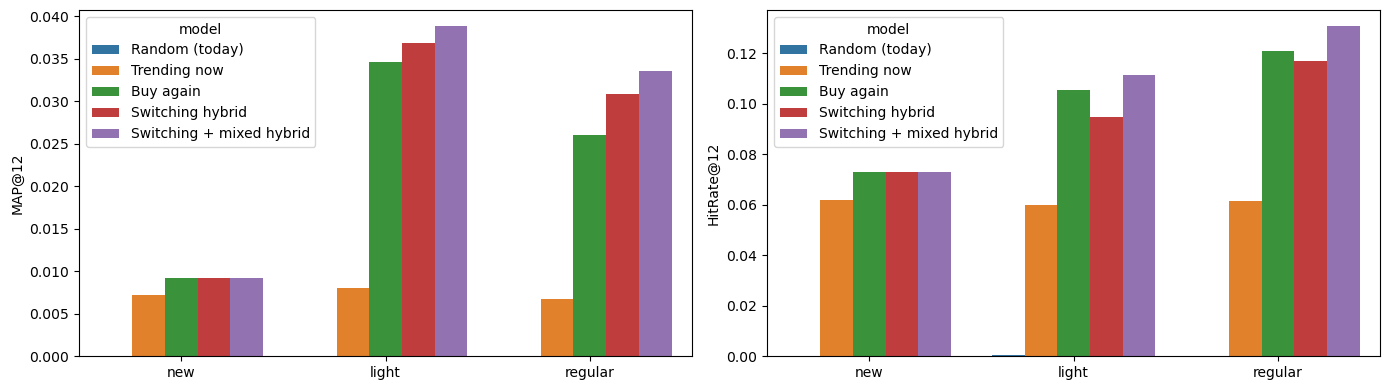

In [86]:
plot_df = results_df[['MAP@12', 'HitRate@12']].reset_index()
plot_df = plot_df[plot_df['group'] != 'all']

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, metric in zip(axes, ['MAP@12', 'HitRate@12']):
  sns.barplot(data=plot_df, x='group', y=metric, hue='model', ax=ax)
  ax.set_xlabel('')
plt.tight_layout()
plt.show();

**Finding.** Every customer group improves on Trending: new customers 7.32% against 6.20%, light 11.14% against 5.99%, and regular 13.06% against 6.15%. Gains are largest where we have purchase history to personalize from.

## 5.3 Personalization

In [87]:
sample_customers = test_customers.sample(n=2_000, random_state=my_seed).tolist()  # recmetrics builds a users x users matrix

all_models = {**models, 'Switching + mixed hybrid': final_RS}
personalization_scores = {}
for name, model in all_models.items():
  top_n = model.recommend_all(sample_customers, k=12)
  personalization_scores[name] = recmetrics.personalization(list(top_n.values()))

summary_df = results_df.xs('all', level='group')[['MAP@12', 'HitRate@12', 'coverage', 'diversity', 'novelty']].copy()
summary_df['personalization'] = pd.Series(personalization_scores)
summary_df

,MAP@12,HitRate@12,coverage,diversity,novelty,personalization
model,,,,,,
Random (today),0.0000,0.0003,0.9996,0.4310,20.1911,0.9999
Trending now,0.0072,0.0613,0.0001,0.2500,10.5660,-0.0000
Buy again,0.0232,0.1037,0.2445,0.2888,11.9107,0.7973
Switching hybrid,0.0260,0.0993,0.1504,0.1645,12.5539,0.9460
Switching + mixed hybrid,0.0278,0.1097,0.2304,0.2577,12.3503,0.9081


**Finding.** The final system is accurate without being narrow. It shows 23.04% of the catalogue against 0.01% for Trending, its lists are highly personal (0.91), and it shows about 3.1 product groups per list against 2.0 for the first plan. Its picks are about 3.4 times less mainstream than Trending (novelty 12.35 against 10.57). A Gini of 0.85 shows attention is still concentrated, so we monitor it after launch.

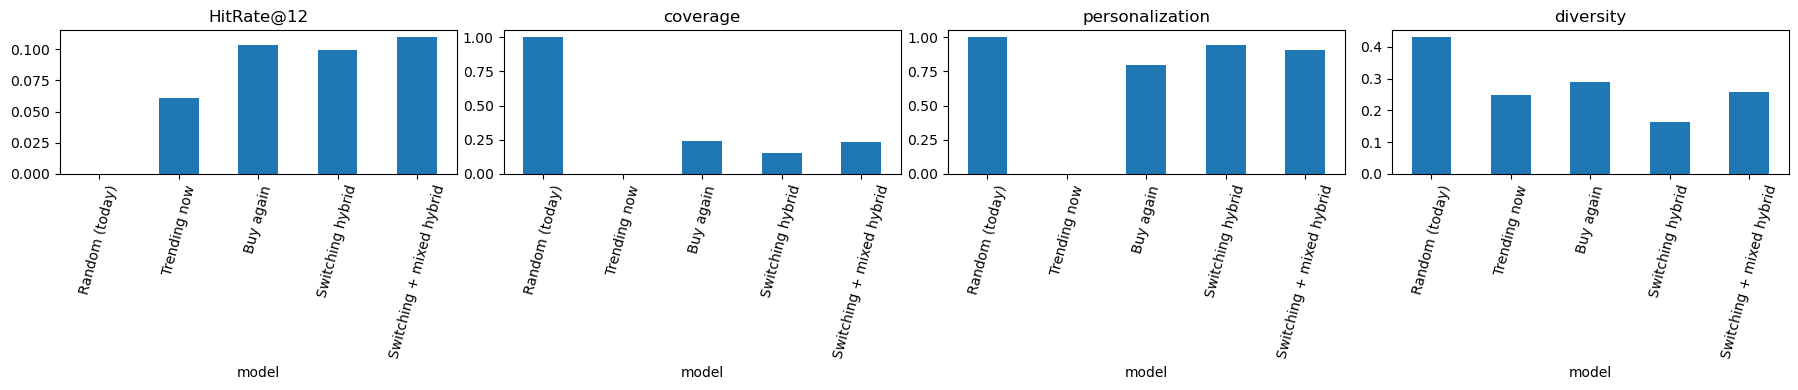

In [88]:
metrics_to_plot = ['HitRate@12', 'coverage', 'personalization', 'diversity']
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, metric in zip(axes, metrics_to_plot):
  summary_df[metric].plot.bar(ax=ax)
  ax.set_title(metric)
  ax.tick_params(axis='x', rotation=75)
plt.tight_layout()
plt.show();

## 5.4 Cross-validation through time

In [89]:
all_df = pd.concat([train, test], ignore_index=True)
all_df['week'] = (all_df['t_dat'] - all_df['t_dat'].min()).dt.days // 7
weeks = np.sort(all_df['week'].unique())

tscv = TimeSeriesSplit(n_splits=4, test_size=1)  # one week per test fold

fold = 1
for train_index, test_index in tscv.split(weeks):
  train_fold = all_df[all_df['week'].isin(weeks[train_index])]
  test_fold = all_df[all_df['week'].isin(weeks[test_index])]

  print(f'Fold {fold}:')
  fold += 1

  train_min = train_fold['t_dat'].min().strftime('%Y-%m-%d')
  train_max = train_fold['t_dat'].max().strftime('%Y-%m-%d')
  test_min = test_fold['t_dat'].min().strftime('%Y-%m-%d')
  test_max = test_fold['t_dat'].max().strftime('%Y-%m-%d')

  print(f'Train data of {train_fold.shape[0]} ratings from {train_min} to {train_max}')
  print(f'Test data of {test_fold.shape[0]} ratings from {test_min} to {test_max}\n')

Fold 1:
Train data of 2861001 ratings from 2020-06-24 to 2020-08-25
Test data of 283181 ratings from 2020-08-26 to 2020-09-01

Fold 2:
Train data of 3144182 ratings from 2020-06-24 to 2020-09-01
Test data of 264657 ratings from 2020-09-02 to 2020-09-08



Fold 3:
Train data of 3408839 ratings from 2020-06-24 to 2020-09-08
Test data of 255241 ratings from 2020-09-09 to 2020-09-15

Fold 4:
Train data of 3664080 ratings from 2020-06-24 to 2020-09-15
Test data of 240311 ratings from 2020-09-16 to 2020-09-22



In [90]:
%%time
cvtt_results = {}
for train_index, test_index in tqdm(list(tscv.split(weeks))):
  train_fold = all_df[all_df['week'].isin(weeks[train_index])]
  test_fold = all_df[all_df['week'].isin(weeks[test_index])]
  test_week = test_fold['t_dat'].min().strftime('%m-%d')

  content_fold = content_trends()
  buy_again_fold = BuyAgainRecommender(fallback=NewCustomerRecommender(weeks=TREND_WEEKS))
  mixed_fold = WeightedHybrid([content_fold, buy_again_fold], [0.5, 0.5])
  final_fold = SwitchingHybrid(new_model=NewCustomerRecommender(weeks=TREND_WEEKS),
                               light_model=mixed_fold, regular_model=mixed_fold).fit(train_fold, articles, customers)
  trending_fold = PopularityRecommender(weeks=TREND_WEEKS).fit(train_fold)

  fold_models = {'Trending now': trending_fold, 'Buy again': buy_again_fold,
                 'Content + trends': content_fold, 'Switching + mixed hybrid': final_fold}
  for name, model in fold_models.items():
    cvtt_results[(test_week, name)] = evaluate(model, test_fold, train=train_fold).loc['all']

cvtt_df = pd.DataFrame(cvtt_results).T.rename_axis(['test_week', 'model'])
cvtt_df['MAP@12'].unstack('model')

CPU times: user 7min 1s, sys: 25.1 s, total: 7min 26s
Wall time: 7min 30s


model,Buy again,Content + trends,Switching + mixed hybrid,Trending now
test_week,,,,
08-26,0.0184,0.0201,0.0215,0.0061
09-02,0.0217,0.0236,0.0255,0.0063
09-09,0.0229,0.0251,0.0273,0.0070
09-16,0.0232,0.0260,0.0278,0.0072


In [91]:
cvtt_df.groupby('model')[['MAP@12', 'HitRate@12']].agg(['mean', 'std'])

MAP@12        HitRate@12       
                           mean    std       mean    std
model                                                   
Buy again                0.0215 0.0022     0.0984 0.0055
Content + trends         0.0237 0.0026     0.0946 0.0056
Switching + mixed hybrid 0.0255 0.0029     0.1045 0.0059
Trending now             0.0067 0.0005     0.0587 0.0060

**Finding.** Across four weeks, retrained each time, the final system ranks first every week (MAP@12 0.0215, 0.0255, 0.0273 and 0.0278; mean 0.0255, standard deviation 0.0029). The 9 September week was also used for tuning, so the sealed 16 September week is the cleanest evidence.

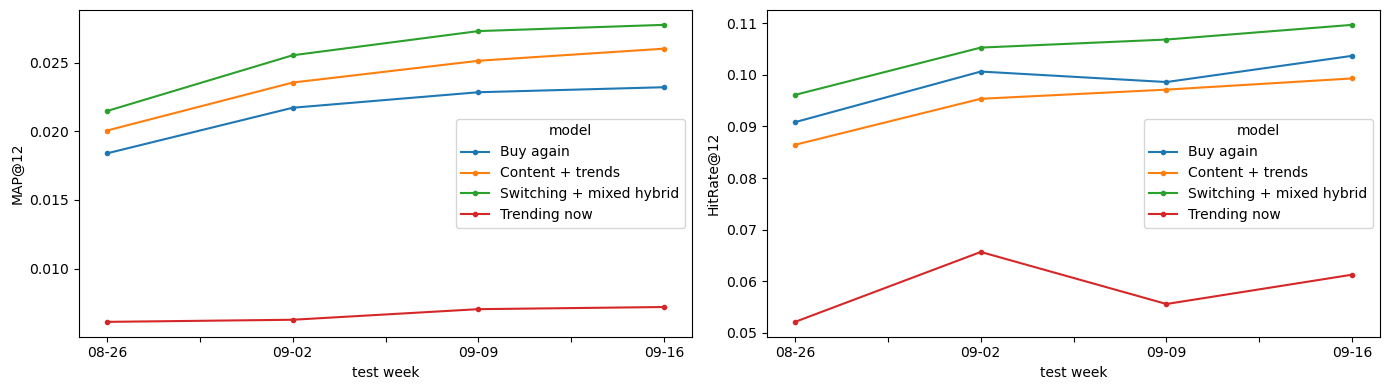

In [92]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, metric in zip(axes, ['MAP@12', 'HitRate@12']):
  cvtt_df[metric].unstack('model').plot(marker='.', ax=ax)
  ax.set_ylabel(metric)
  ax.set_xlabel('test week')
plt.tight_layout()
plt.show();

# Part 6. Context-aware recommender

**Lead:** Jade Beeks (Member 5)

The same customer can want different products in a different context. H&M records the sales channel of every purchase, so we test contextual pre-filtering from S19: keep only the purchases from the current context, train on them, and recommend for that context. Channel 1 is commonly reported as store and channel 2 as online, although the dataset does not confirm this.

## 6.1 Contextual pre-filtering by sales channel

In [93]:
context_df_dict = {'store (channel 1)': (train[train['sales_channel_id'] == 1], test[test['sales_channel_id'] == 1]),
                   'online (channel 2)': (train[train['sales_channel_id'] == 2], test[test['sales_channel_id'] == 2])}


def build_final_system(fit_df):
  content_context = content_trends()
  buy_again_context = BuyAgainRecommender(fallback=NewCustomerRecommender(weeks=TREND_WEEKS))
  mixed_context = WeightedHybrid([content_context, buy_again_context], [0.5, 0.5])
  return SwitchingHybrid(new_model=NewCustomerRecommender(weeks=TREND_WEEKS), light_model=mixed_context,
                         regular_model=mixed_context).fit(fit_df, articles, customers)


trending_all = PopularityRecommender(weeks=TREND_WEEKS).fit(train)

context_results = {}
for context, (train_context, test_context) in tqdm(context_df_dict.items()):
  trending_context = PopularityRecommender(weeks=TREND_WEEKS).fit(train_context)
  final_context = build_final_system(train_context)
  context_models = {'Trending, all channels': trending_all, 'Trending, same channel': trending_context,
                    'Final system, all channels': final_RS, 'Final system, same channel': final_context}
  for name, model in context_models.items():
    context_results[(context, name)] = evaluate(model, test_context).loc['all', ['n_customers', 'MAP@12', 'HitRate@12']]

context_results_df = pd.DataFrame(context_results).T.rename_axis(['context', 'model'])
context_results_df

n_customers  MAP@12  HitRate@12
context            model                                                      
store (channel 1)  Trending, all channels       29919.0000  0.0086      0.0497
                   Trending, same channel       29919.0000  0.0097      0.0541
                   Final system, all channels   29919.0000  0.0174      0.0706
                   Final system, same channel   29919.0000  0.0178      0.0793
online (channel 2) Trending, all channels       41529.0000  0.0064      0.0668
                   Trending, same channel       41529.0000  0.0075      0.0659
                   Final system, all channels   41529.0000  0.0349      0.1324
                   Final system, same channel   41529.0000  0.0362      0.1374

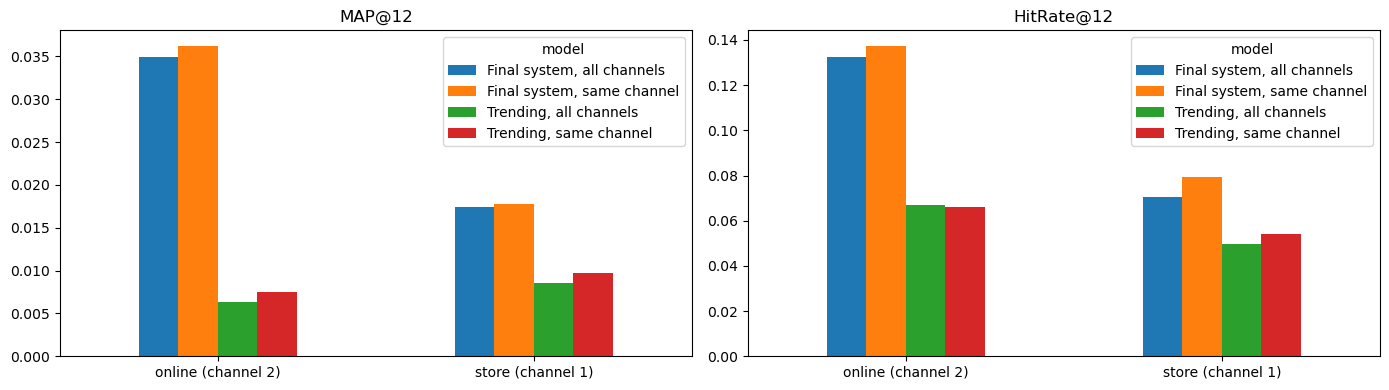

In [94]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, metric in zip(axes, ['MAP@12', 'HitRate@12']):
  context_results_df[metric].unstack('model').plot.bar(ax=ax, rot=0)
  ax.set_title(metric)
  ax.set_xlabel('')
plt.tight_layout()
plt.show()

**Finding.** Pre-filtering by channel improves the final system in both contexts: hit rate rises from 7.06% to 7.93% in store and from 13.24% to 13.74% online. We measured this on the test week and the channel must be known when recommending, so we keep it as the next experiment and do not change the final system.

In [95]:
free('context_df_dict', 'train_context', 'test_context', 'trending_context', 'final_context', 'context_models', 'trending_all')

# Part 7. Exploration-exploitation with bandits

**Lead:** Jade Beeks (Member 5)

## 7.1 Exploration-exploitation with multi-armed bandits

### 7.1.1 Beta distribution for each item

In [96]:
last_week = train[train['t_dat'] > train['t_dat'].max() - pd.Timedelta(days=7)]

def beta_table(df):  # H&M has no views: failure = shopping visit (customer-day) without buying the item, from its first sale day
  visits_df = df[['t_dat', 'customer_id']].drop_duplicates()
  visits_from_day = visits_df.groupby('t_dat').size()[::-1].cumsum()[::-1]
  buys_df = df[['t_dat', 'customer_id', 'article_id']].drop_duplicates()
  items_df = buys_df.groupby('article_id').agg(first_day=('t_dat', 'min'), successes=('customer_id', 'size'))
  beta_df = pd.DataFrame({1: items_df['successes'],
                          0: items_df['first_day'].map(visits_from_day) - items_df['successes']})
  beta_df.index.name = 'itemid'  # name used by S22 compute_probability
  return beta_df.astype('int')

beta_df = beta_table(last_week)
beta_df

,1,0
itemid,,
108775044,2,28994
111565001,22,54891
111586001,60,81100
111593001,44,81116
111609001,15,81145
...,...,...
952267001,15,81145
952938001,2,8285
953450001,9,54904


In [97]:
def plot_beta(items):

  dict_data = {}
  for item in items:
    dict_data[str(item)] = np.random.beta(*item, size=10000)

  df = pd.DataFrame(dict_data)

  plt.subplots(figsize=(8, 4))
  sns.kdeplot(data=df, alpha=.5, fill=True);

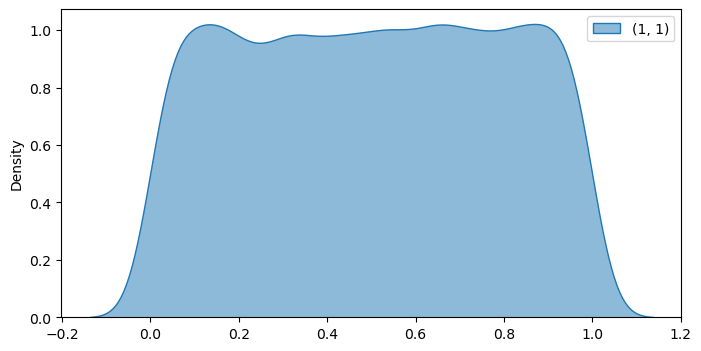

In [98]:
plot_beta([(1, 1)])

In [99]:
beta_df += 1
beta_df

,1,0
itemid,,
108775044,3,28995
111565001,23,54892
111586001,61,81101
111593001,45,81117
111609001,16,81146
...,...,...
952267001,16,81146
952938001,3,8286
953450001,10,54905


### 7.1.2 Exploration-exploitation

In [100]:
def compute_probability(beta_df, n_sample=10_000):
  beta_values = beta_df.reset_index()[['itemid', 1, 0]].values

  max_items = []
  for i in range(n_sample):
    rewards = {item[0]: np.random.beta(*item[[1,2]]) for item in beta_values}
    max_item = max(rewards, key=rewards.get)
    max_items.append(int(max_item))

  max_items_each = Counter(max_items)

  max_items_each_df = pd.DataFrame.from_dict(max_items_each, orient='index').rename(columns={0: 'num_sampled'})

  beta_sampled_df = pd.merge(beta_df, max_items_each_df, left_index=True, right_index=True, how='outer')
  beta_sampled_df = beta_sampled_df.fillna(0).astype('int')  # Missing value means item was sampled zero times

  return beta_sampled_df

In [101]:
def plot_probability(beta_sampled_df):
  fig, ax = plt.subplots(figsize=(15, 15))
  wedges, texts, autotexts = ax.pie(beta_sampled_df['num_sampled'], labels=beta_sampled_df.index, autopct='%1.2f%%');

  plt.show()

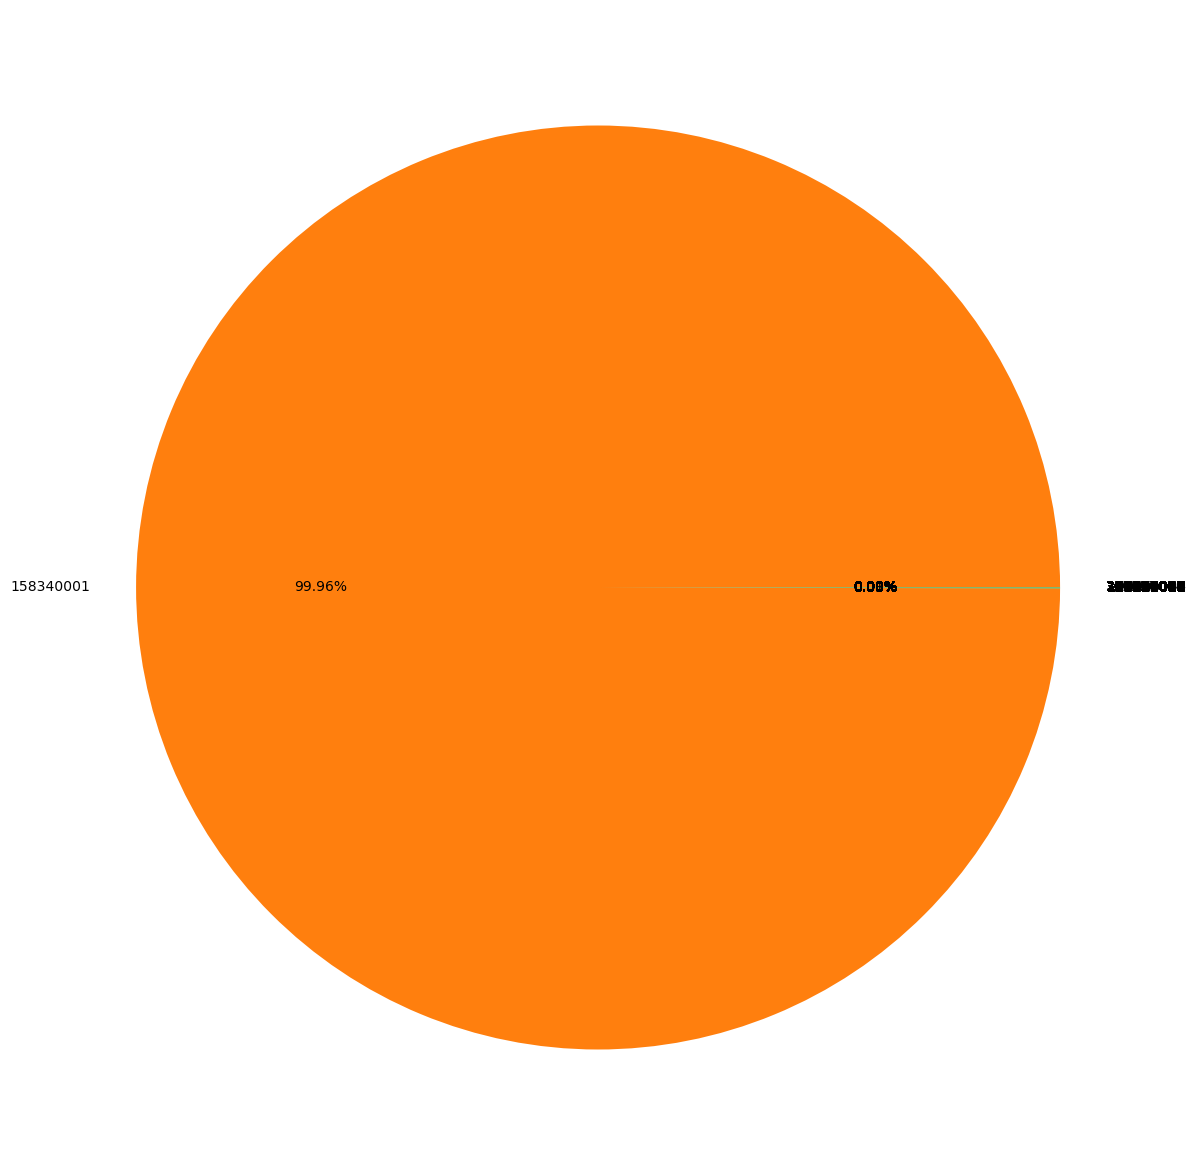

In [102]:
beta_sampled_df = compute_probability(beta_df.head(200))
plot_probability(beta_sampled_df)

In [103]:
beta_sampled_df = compute_probability(beta_df.sort_values(1, ascending=False).head(200))  # most bought items, not most interactions

beta_sampled_df['mean'] = beta_sampled_df[1] / (beta_sampled_df[0] + beta_sampled_df[1])
beta_sampled_df.sort_values('mean', ascending=False).head()

,1,0,num_sampled,mean
909370001,1078,80084,10000,0.0133
865799006,668,80494,0,0.0082
918522001,665,80497,0,0.0082
924243001,635,80527,0,0.0078
923758001,393,54522,0,0.0072


**Finding.** H&M has no product-view data, so a failure is a shopping visit without buying the item. With this much evidence, the strongest product wins all 10,000 draws among the 200 most-bought items, which is pure exploitation.

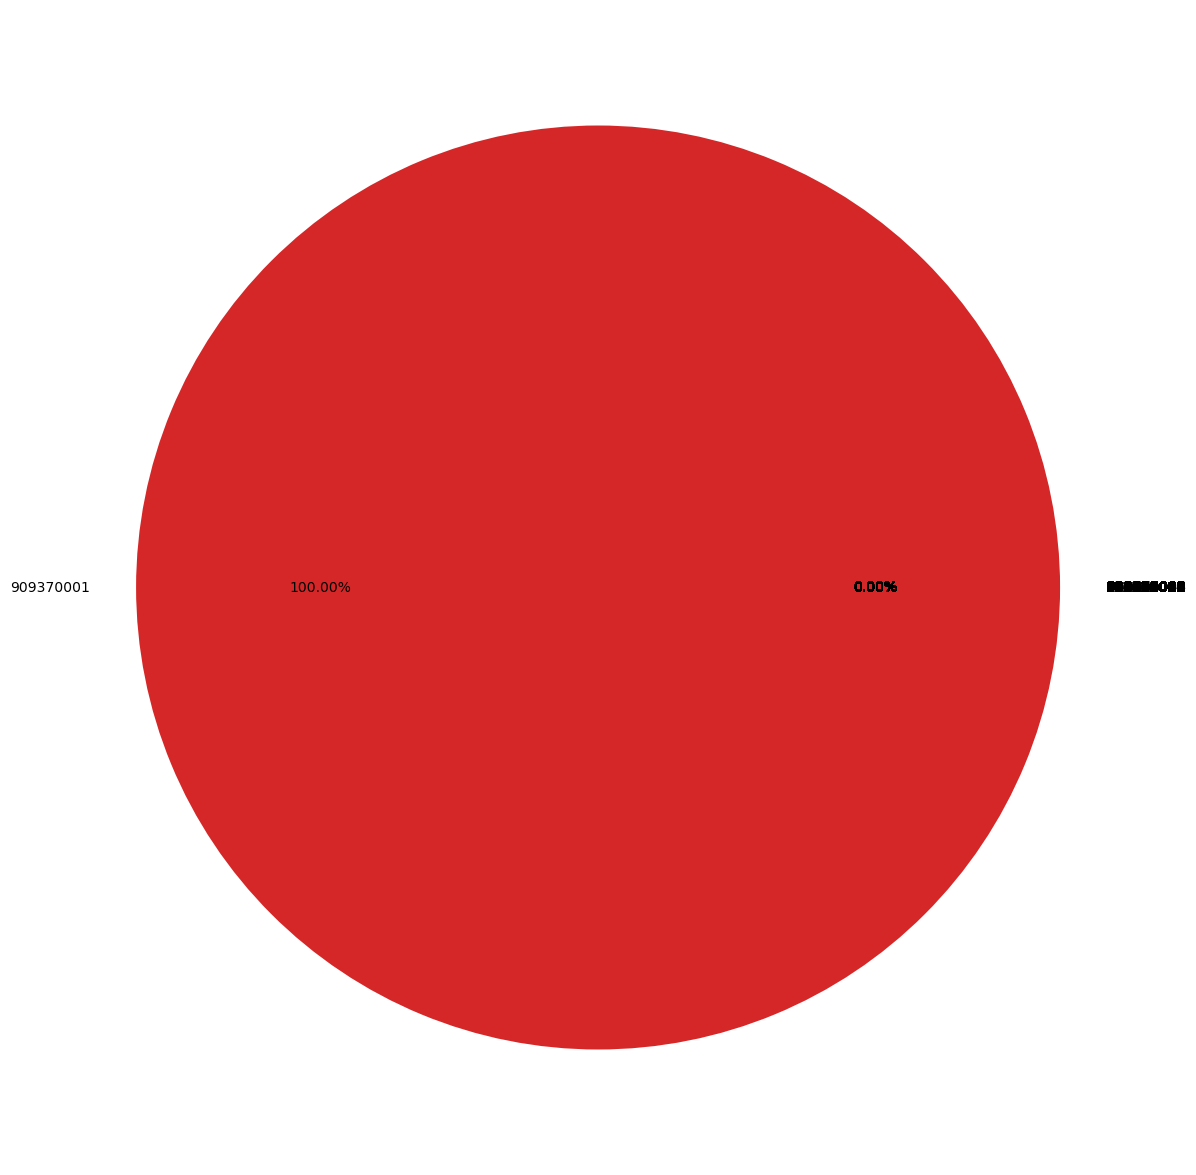

In [104]:
plot_probability(beta_sampled_df)

### 7.1.3 New items and the prior

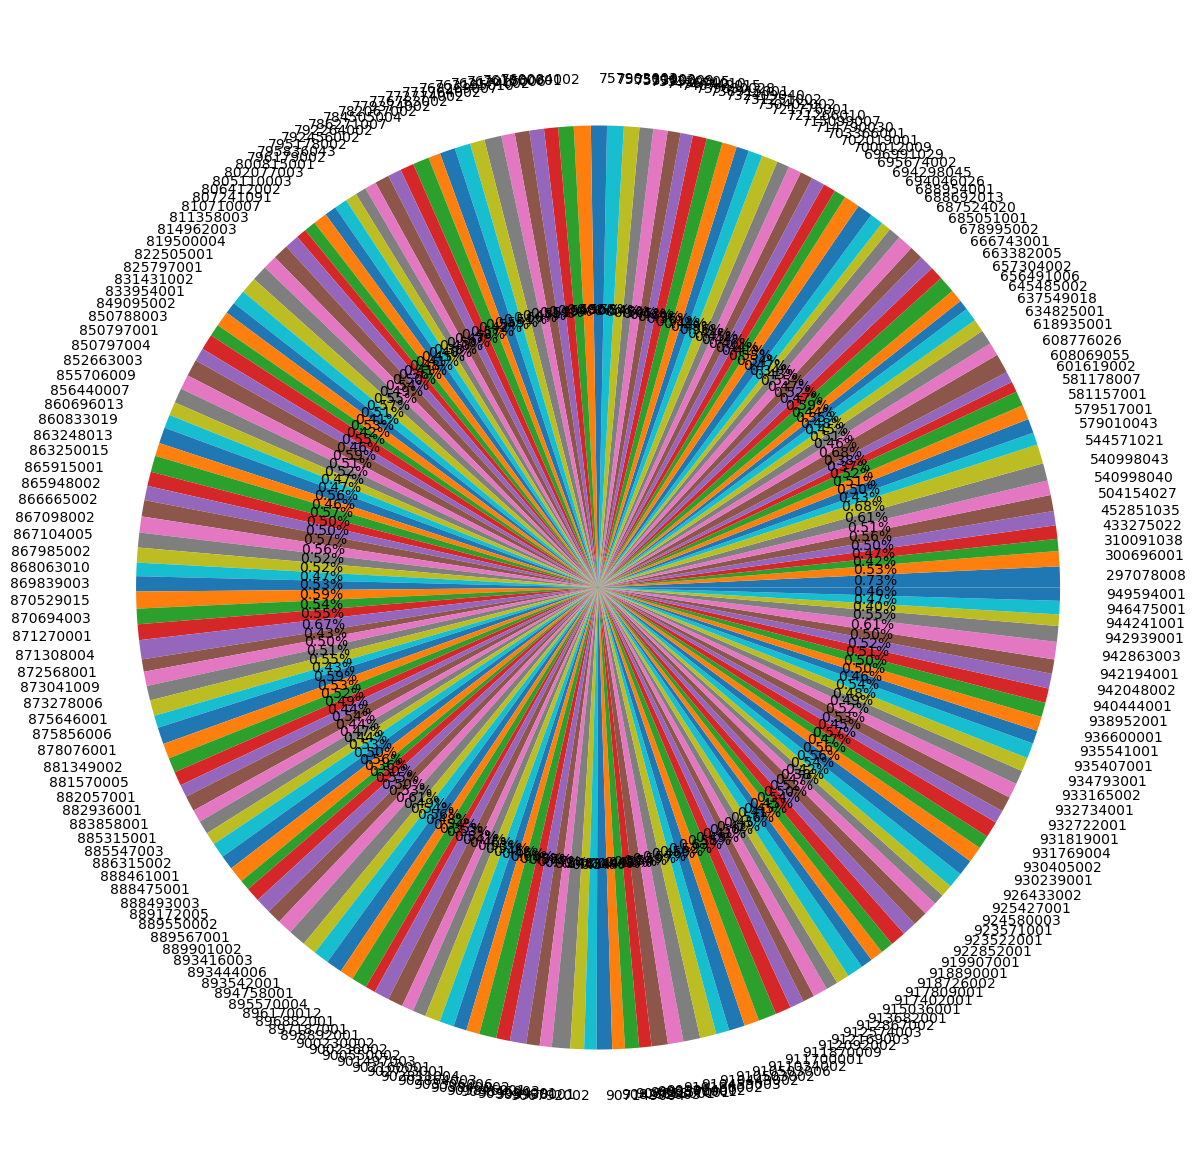

In [105]:
launches = sorted(new_items(train, test))
launch_items = pd.Series(launches).sample(200, random_state=my_seed).tolist()
top_item = beta_df[1].idxmax()

new_items_df = pd.DataFrame({1: 1, 0: 1}, index=pd.Index(launch_items, name='itemid'))
beta_df_newitems_and_top1popular = pd.concat([new_items_df, beta_df.loc[[top_item]]])

beta_sampled_df = compute_probability(beta_df_newitems_and_top1popular)
plot_probability(beta_sampled_df)

In [106]:
(beta_df[1] / (beta_df[0] + beta_df[1])).describe()

count   18611.0000
mean        0.0002
std         0.0004
min         0.0000
25%         0.0000
50%         0.0001
75%         0.0002
max         0.0133
dtype: float64

In [107]:
prior_results = {}
for extra_failures in [0, 20, 100, 420, 1000]:
  beta_df_newitems_and_top1popular = pd.concat([new_items_df, beta_df.loc[[top_item]]])
  beta_df_newitems_and_top1popular[0] += extra_failures
  beta_sampled_df = compute_probability(beta_df_newitems_and_top1popular)
  prior_results[extra_failures] = beta_sampled_df.loc[top_item, 'num_sampled'] / beta_sampled_df['num_sampled'].sum() * 100

pd.Series(prior_results, name='% top item selected').rename_axis('extra failures')

extra failures
0       0.0000
20      0.0000
100     0.0000
420    47.1300
1000   99.9800
Name: % top item selected, dtype: float64

**Finding.** With an uninformative prior, new items take almost all exposure from a proven best seller. Adding 420 prior failures balances the two: the best seller is chosen about 47% of the time and new items share the rest.

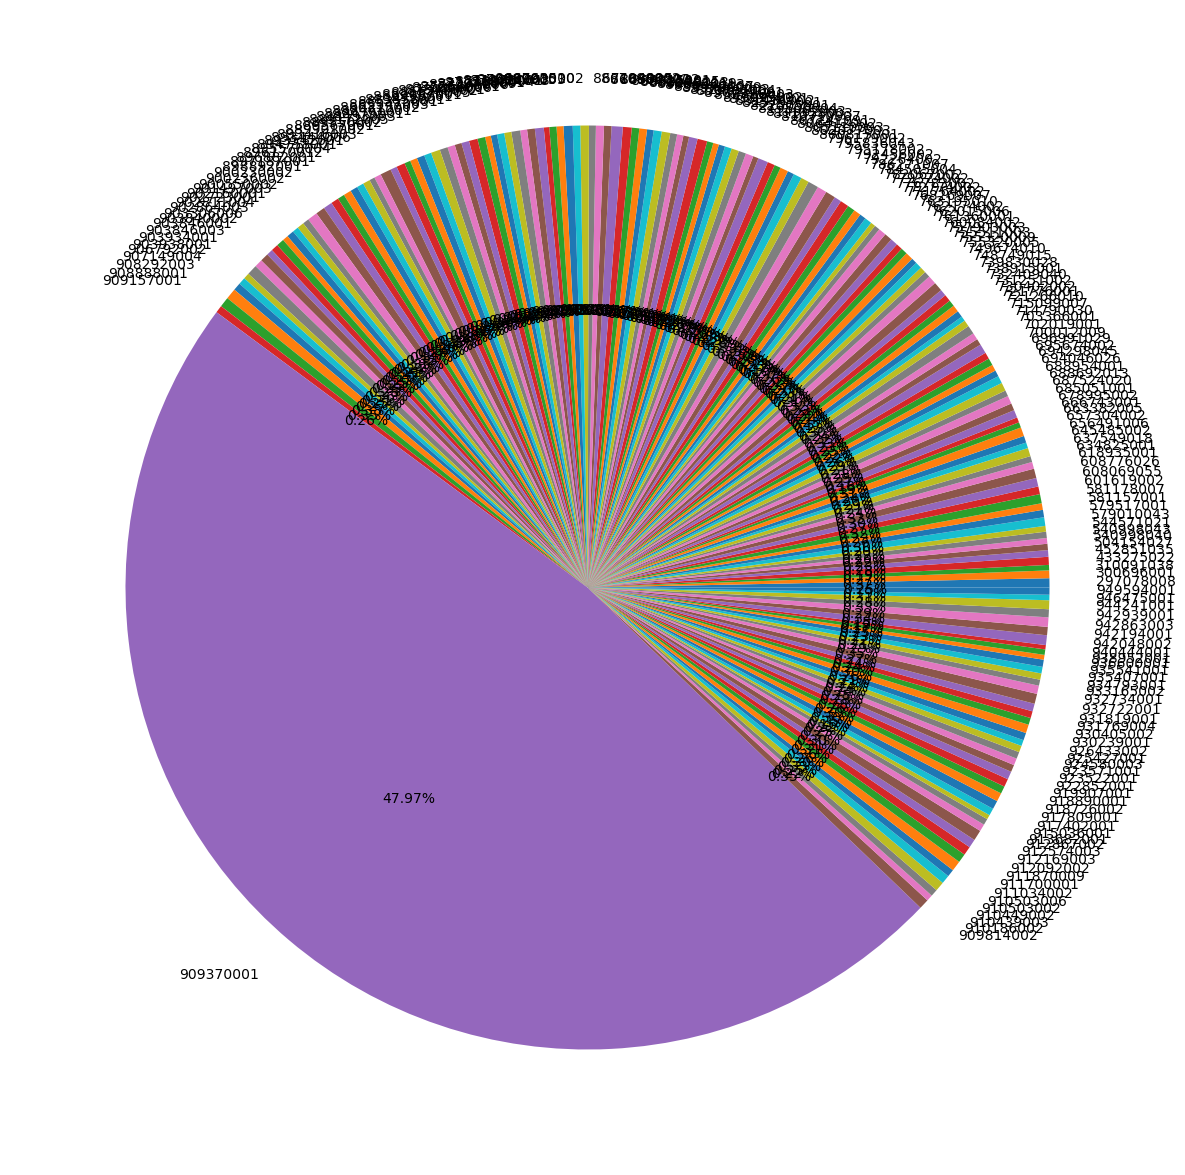

In [108]:
PRIOR_FAILURES = 420

beta_df_newitems_and_top1popular = pd.concat([new_items_df, beta_df.loc[[top_item]]])
beta_df_newitems_and_top1popular[0] += PRIOR_FAILURES

beta_sampled_df = compute_probability(beta_df_newitems_and_top1popular)
plot_probability(beta_sampled_df)

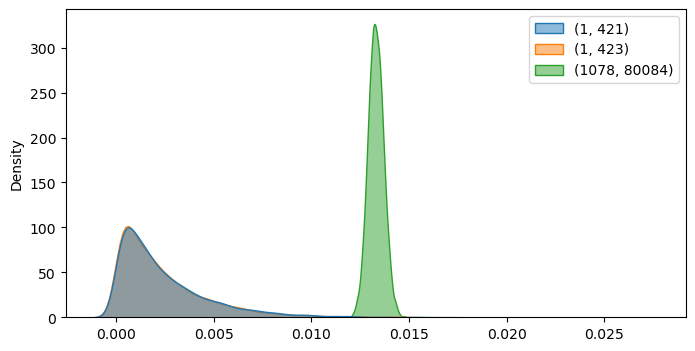

In [109]:
plot_beta([(1, 1 + PRIOR_FAILURES), (1, 3 + PRIOR_FAILURES), tuple(beta_df.loc[top_item, [1, 0]])])

### 7.1.4 Dynamic nature

In [110]:
ref_launch = (test[test['article_id'].isin(launch_items)]
              .groupby('article_id')['customer_id'].nunique().idxmax())
ref_launch, articles.set_index('article_id').loc[ref_launch, 'prod_name']

(np.int32(935541001), 'Aussi Leaf midi dress')

In [111]:
list_dates = pd.date_range(test['t_dat'].min(), periods=8).tolist()

prob_over_time = []
for date in tqdm(list_dates):
  history_df = pd.concat([last_week, test[test['t_dat'] < date]])

  beta_day_df = beta_table(history_df).reindex(launch_items + [top_item]).fillna(0).astype('int')
  beta_day_df.index.name = 'itemid'

  beta_day_df += 1
  beta_day_df[0] += PRIOR_FAILURES

  beta_sampled_df = compute_probability(beta_day_df)

  beta_sampled_df['num_sampled_percent'] = beta_sampled_df['num_sampled'] / beta_sampled_df['num_sampled'].sum() * 100
  print(date.strftime('%Y-%m-%d'))
  print(beta_sampled_df[beta_sampled_df['num_sampled_percent'] > 3])

  prob_over_time.append(beta_sampled_df.loc[[ref_launch, top_item], 'num_sampled_percent'].rename(date))

2020-09-16
              1      0  num_sampled  num_sampled_percent
909370001  1078  80504         4712              47.1200


2020-09-17
              1      0  num_sampled  num_sampled_percent
909370001  1136  89198         4514              45.1400


2020-09-18
              1       0  num_sampled  num_sampled_percent
909370001  1307  102230         5325              53.2500


2020-09-19
              1       0  num_sampled  num_sampled_percent
909370001  1395  115066         5355              53.5500


2020-09-20
              1       0  num_sampled  num_sampled_percent
909370001  1453  127241         5789              57.8900


2020-09-21
              1       0  num_sampled  num_sampled_percent
909370001  1486  136592         6167              61.6700


2020-09-22
              1       0  num_sampled  num_sampled_percent
909370001  1529  146668         7549              75.4900


2020-09-23
              1       0  num_sampled  num_sampled_percent
909370001  1550  157175        10000             100.0000


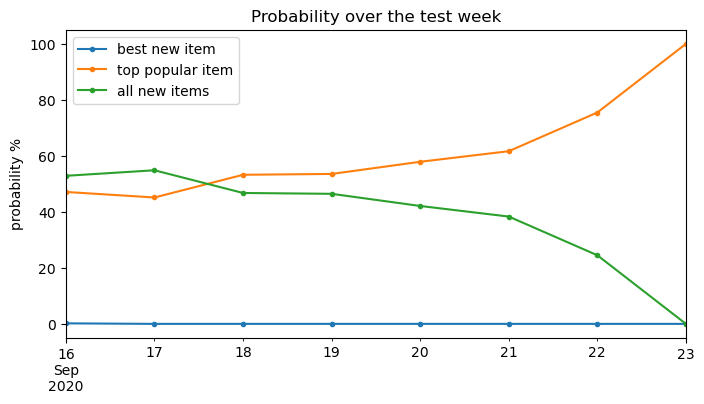

In [112]:
prob_over_time_df = pd.DataFrame(prob_over_time)
prob_over_time_df.columns = ['best new item', 'top popular item']
prob_over_time_df['all new items'] = 100 - prob_over_time_df['top popular item']

prob_over_time_df.plot(marker='.', figsize=(8, 4))
plt.ylabel('probability %')
plt.title('Probability over the test week')
plt.show();

**Finding.** As purchases arrive during the test week, the probability of choosing the strongest product rises from 47% to 100%. New items that do not sell lose exposure automatically, so the more data the bandit sees, the less it guesses.

### 7.1.5 Replay on the test week

In [113]:
def replay_bandit(candidates, alpha, beta, policy, seed=my_seed):  # own replay of the test week, not in S22
  rng = np.random.default_rng(seed)
  alpha, beta = alpha.astype(float).copy(), beta.astype(float).copy()
  bought = set(zip(test['t_dat'], test['customer_id'], test['article_id']))
  visits_df = test[['t_dat', 'customer_id']].drop_duplicates()
  reward, new_shown = 0, 0
  for day, customer in visits_df.itertuples(index=False):
    if policy == 'random':
      j = rng.integers(len(candidates))
    elif policy == 'greedy':
      j = np.argmax(alpha / (alpha + beta))
    else:
      j = np.argmax(rng.beta(alpha, beta))
    hit = (day, customer, candidates[j]) in bought
    reward += hit
    new_shown += candidates[j] in launch_set
    alpha[j] += hit
    beta[j] += 1 - hit
  return reward, new_shown / len(visits_df) * 100

In [114]:
%%time
popular_items = beta_df.sort_values(1, ascending=False).head(100).index.tolist()
launch_set = set(launch_items[:100])
candidates = popular_items + launch_items[:100]

replay_results = {}
for name, policy, extra_failures in [('Random (today)', 'random', 0),
                                     ('Always best seller', 'greedy', PRIOR_FAILURES),
                                     ('Thompson, prior (1, 1)', 'thompson', 0),
                                     ('Thompson, prior (1, 1+20)', 'thompson', 20),
                                     (f'Thompson, prior (1, 1+{PRIOR_FAILURES})', 'thompson', PRIOR_FAILURES)]:
  alpha = np.array([beta_df.loc[i, 1] if i in beta_df.index else 1 for i in candidates])
  beta = np.array([beta_df.loc[i, 0] if i in beta_df.index else 1 + extra_failures for i in candidates])
  reward, new_share = replay_bandit(candidates, alpha, beta, policy)
  replay_results[name] = {'purchases': reward, '% slots on new items': new_share}

pd.DataFrame(replay_results).T

CPU times: user 5.11 s, sys: 632 ms, total: 5.75 s
Wall time: 5.99 s


,purchases,% slots on new items
Random (today),130.0000,49.9436
Always best seller,472.0000,0.0000
"Thompson, prior (1, 1)",91.0000,67.1610
"Thompson, prior (1, 1+20)",97.0000,65.7908
"Thompson, prior (1, 1+420)",364.0000,21.7687


**Finding.** In the offline replay, Thompson Sampling with our prior makes 364 matches, 2.8 times as many as random (130), while giving new products 21.8% of the slots. Always showing the best seller makes more matches (472) but gives new products no exposure, and that gap is the cost of discovery. Without a calibrated prior, Thompson Sampling does worse than random (91 matches).

## 7.2 Contextual bandit per age band

In [115]:
age_bands = customer_age_bands(customers)
item_names = articles.set_index('article_id')['prod_name']
top200 = beta_df.sort_values(1, ascending=False).head(200).index

band_top = {}
for band in ['all'] + AGE_LABELS:
  band_week = last_week if band == 'all' else last_week[last_week['customer_id'].map(age_bands) == band]
  n_visits = band_week[['t_dat', 'customer_id']].drop_duplicates().shape[0]

  beta_band_df = beta_table(band_week).reindex(top200)
  beta_band_df[1] = beta_band_df[1].fillna(0)
  beta_band_df[0] = beta_band_df[0].fillna(n_visits)
  beta_band_df = beta_band_df.astype('int')
  beta_band_df.index.name = 'itemid'
  beta_band_df += 1

  beta_sampled_df = compute_probability(beta_band_df)
  share = beta_sampled_df['num_sampled'] / beta_sampled_df['num_sampled'].sum() * 100
  top3 = share.sort_values(ascending=False).head(3)
  band_top[band] = [f'{item_names[i]} ({p:.0f}%)' for i, p in top3.items()]

pd.DataFrame(band_top, index=['1st', '2nd', '3rd']).T

,1st,2nd,3rd
all,FF PI Haley dress (100%),Highwaist 30 den 1p Tights (0%),ED Georgia leggings (0%)
16-24,FF PI Haley dress (51%),Jackie cable vest (43%),Perrie Slim Mom Denim TRS (5%)
25-34,FF PI Haley dress (100%),Highwaist 30 den 1p Tights (0%),ED Georgia leggings (0%)
35-44,FF PI Haley dress (100%),Vanessa (0%),Highwaist 30 den 1p Tights (0%)
45-54,Pluto RW slacks (1) (79%),Jackie cable vest (9%),FF PI Haley dress (6%)
55-64,Jackie cable vest (45%),Amelie (36%),Ohlsson (12%)
65+,FF PI Cilla dress (17%),Jackie cable vest (16%),Ohlsson (9%)


**Finding.** Preferences change by age. The same dress dominates for ages 25 to 44, while other products lead for ages 45 to 54 and 55 to 64. One bandit per age group can therefore explore products that suit each audience.

# Part 8. Business value

**Lead:** Jade Beeks (Member 5)

## 8.1 Business value

### 8.1.1 Purchases caught by the recommendations

In [116]:
%%time
test_ids = test_customers.tolist()
bought_df = test.groupby(['customer_id', 'article_id'])['price'].agg(['size', 'sum']).reset_index()
week_revenue = test['price'].sum()

top_n_all = {}
value_results = {}
for name, model in all_models.items():  # own business metric, not in the course notebooks
  top_n_all[name] = model.recommend_all(test_ids, k=12)
  top_n_df = pd.DataFrame([(c, i) for c, items in top_n_all[name].items() for i in items],
                          columns=['customer_id', 'article_id'])
  hits_df = bought_df.merge(top_n_df, on=['customer_id', 'article_id'])
  value_results[name] = {'customers with a purchase from their list': hits_df['customer_id'].nunique(),
                         'items bought from the list': hits_df['size'].sum(),
                         'items per 1,000 customers': hits_df['size'].sum() / len(test_ids) * 1000,
                         '% of week sales value': hits_df['sum'].sum() / week_revenue * 100}

value_df = pd.DataFrame(value_results).T
value_df

CPU times: user 1min 3s, sys: 4.11 s, total: 1min 7s
Wall time: 1min 8s


,customers with a purchase from their list,items bought from the list,"items per 1,000 customers",% of week sales value
Random (today),18.0000,19.0000,0.2754,0.0074
Trending now,4227.0000,5086.0000,73.7272,2.1921
Buy again,7152.0000,9849.0000,142.7722,4.3700
Switching hybrid,6850.0000,9830.0000,142.4968,4.2604
Switching + mixed hybrid,7566.0000,10862.0000,157.4568,4.7570


**Finding.** The final system puts 157 purchased items per 1,000 customers in their lists, 2.1 times as many as Trending (74). Those matched items represent 4.76% of the week's sales value.

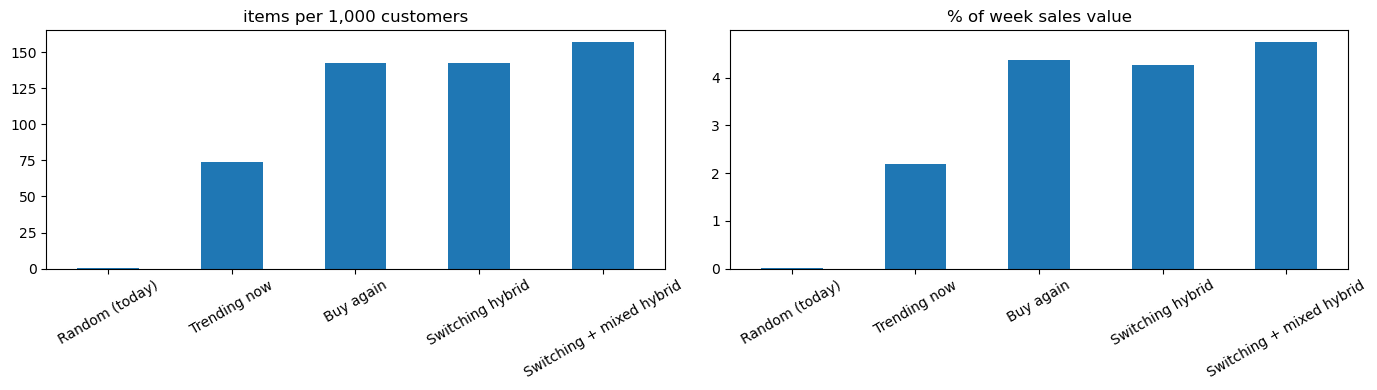

In [117]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, metric in zip(axes, ['items per 1,000 customers', '% of week sales value']):
  value_df[metric].plot.bar(ax=ax)
  ax.set_title(metric)
  ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show();

In [118]:
value_df.loc['Switching + mixed hybrid', 'items per 1,000 customers'] / value_df.loc['Trending now', 'items per 1,000 customers']

np.float64(2.1356665355878883)

### 8.1.2 Scenarios

In [119]:
extra_vs_random = value_df.loc['Switching + mixed hybrid', '% of week sales value'] - value_df.loc['Random (today)', '% of week sales value']
extra_vs_trending = value_df.loc['Switching + mixed hybrid', '% of week sales value'] - value_df.loc['Trending now', '% of week sales value']

scenario_df = pd.DataFrame({'incremental share of matched purchases (%)': [10, 25, 50]})
scenario_df['sales uplift vs random (%)'] = scenario_df.iloc[:, 0] / 100 * extra_vs_random
scenario_df['sales uplift vs trending now (%)'] = scenario_df.iloc[:, 0] / 100 * extra_vs_trending
scenario_df

,incremental share of matched purchases (%),sales uplift vs random (%),sales uplift vs trending now (%)
0,10,0.4750,0.2565
1,25,1.1874,0.6412
2,50,2.3748,1.2824


**Finding.** A matched purchase is not always caused by the recommendation. If only 10%, 25% or 50% of matches were truly extra sales, revenue would rise by 0.26%, 0.64% or 1.28% compared with Trending.

## 8.2 Estimated added value from published lifts

In [120]:
recommend_start = time.perf_counter()
final_lists = final_RS.recommend_all(test_ids, k=12)
recommend_seconds = time.perf_counter() - recommend_start

final_df = pd.DataFrame([(c, i) for c, items in final_lists.items() for i in items], columns=['customer_id', 'article_id'])
hits_df = bought_df.merge(final_df, on=['customer_id', 'article_id'])
matched_share = hits_df['sum'].sum() / test['price'].sum()

print(f"Purchased items in the lists per 1,000 shoppers: {hits_df['size'].sum() / len(test_ids) * 1000:.1f}")
print(f'Share of test-week sales value in the lists: {matched_share:.2%}')

Purchased items in the lists per 1,000 shoppers: 157.5
Share of test-week sales value in the lists: 4.76%


In [121]:
net_sales_sek_m = 187_031  # H&M Annual Report 2020
online_share = 0.28  # H&M Annual Report 2020
gross_margin = 0.50  # H&M Annual Report 2020
online_sales_sek_m = net_sales_sek_m * online_share

scenario_df = pd.DataFrame({'measured lift': [0.003, 0.018]}, index=['Lower study', 'Higher study'])  # Jannach & Jugovac 2019, online grocery
scenario_df['extra sales (SEK m)'] = online_sales_sek_m * scenario_df['measured lift']
scenario_df['gross profit (SEK m)'] = scenario_df['extra sales (SEK m)'] * gross_margin
scenario_df['matched purchases that must be incremental'] = scenario_df['measured lift'] / matched_share
scenario_df

,measured lift,extra sales (SEK m),gross profit (SEK m),matched purchases that must be incremental
Lower study,0.0030,157.1060,78.5530,0.0631
Higher study,0.0180,942.6362,471.3181,0.3784


In [122]:
sek_per_eur = 10.5  # about the 2020 average exchange rate

euro_df = scenario_df[['measured lift']].copy()
euro_df['extra sales (EUR m)'] = scenario_df['extra sales (SEK m)'] / sek_per_eur
euro_df['gross profit (EUR m)'] = scenario_df['gross profit (SEK m)'] / sek_per_eur
print(f'2020 online sales: about EUR {online_sales_sek_m / sek_per_eur / 1000:.1f} billion')
euro_df

2020 online sales: about EUR 5.0 billion


,measured lift,extra sales (EUR m),gross profit (EUR m)
Lower study,0.0030,14.9625,7.4812
Higher study,0.0180,89.7749,44.8874


**Finding.** Published online grocery experiments measured sales lifts of 0.3% to 1.8%. Applied to about €5 billion of 2020 online sales, this gives an estimated **€15m to €90m in extra sales a year**, or about €7.5m to €45m in gross profit. The low end needs the system to cause only 1 in 16 of the purchases it matched. The studies come from another retail category and exclude build and delivery costs, so the A/B test must confirm the effect.

# Part 9. End-to-end system for all clients

**Lead:** Jade Beeks (Member 5)

## 9.1 Recommendations for any customer

In [123]:
item_info = articles.set_index('article_id')[['prod_name', 'product_type_name', 'colour_group_name']]
purchases = train.groupby('customer_id').size()

examples = {
    'Never seen': 'this-customer-does-not-exist',
    'New in test week': segments[segments == 'new'].index[0],
    'Light': segments[segments == 'light'].index[0],
    'Regular': segments[segments == 'regular'].index[0],
}

example_lists = {}
for name, customer_id in examples.items():
  items = final_RS.recommend(customer_id, k=12)
  assert len(items) == 12 and len(set(items)) == 12
  example_lists[name] = item_info.loc[items, 'prod_name'].to_numpy()
  print(f"{name}: routed to '{final_RS.segments([customer_id]).iloc[0]}', {purchases.get(customer_id, 0)} past purchases")

pd.DataFrame(example_lists, index=range(1, 13))

Never seen: routed to 'new', 0 past purchases


New in test week: routed to 'new', 0 past purchases


Light: routed to 'light', 4 past purchases


Regular: routed to 'regular', 57 past purchases


,Never seen,New in test week,Light,Regular
1,Nika vest,Nika vest,Perrie Trash HW Denim TRS,Lucien lace
2,Pluto RW slacks (1),Perrie Slim Mom Denim TRS,Pixie HW woven TRS,Lucien lace
3,FF PI Haley dress,STRONG HW seamless tights,Perrie Trash HW Denim TRS,Tinos mesh tights
4,STRONG HW seamless tights,Jackie cable vest,Delila ss,Lucien lace
5,Pluto RW slacks (1),Jade HW Skinny Denim TRS,Perrie Trash HW Denim TRS,Roxy Blouse.
6,Jackie cable vest,RICHIE HOOD,Perrie Slim Mom Denim TRS,Lucien CONSCIOUS
7,Liliana,Pluto RW slacks (1),SPORT Cava body,Lucien CONSCIOUS
8,Jade HW Skinny Denim TRS,Liliana,FF PI Haley dress,Claudine rib t-shirt
9,Perrie Slim Mom Denim TRS,FF PI Haley dress,Perrie Trash HW Denim TRS,Lucien CONSCIOUS
10,Baraboom throw-on,RICHIE HOOD,STRONG HW seamless tights,Swim skirt


### Every customer in the database

In [124]:
all_customer_ids = customers['customer_id'].astype(str).tolist()
all_customers_seconds = None

if RUN_ALL_CUSTOMERS:
  all_customers_start = time.perf_counter()
  valid_lists = 0
  for start in tqdm(range(0, len(all_customer_ids), 50_000)):
    batch_lists = final_RS.recommend_all(all_customer_ids[start:start + 50_000], k=12)
    valid_lists += sum(len(items) == 12 and len(set(items)) == 12 for items in batch_lists.values())
  all_customers_seconds = time.perf_counter() - all_customers_start
  assert valid_lists == len(all_customer_ids)
  print(f'{valid_lists:,} of {len(all_customer_ids):,} customers received 12 distinct products')
  print(f'Full refresh: {all_customers_seconds / 60:.1f} minutes')

1,371,980 of 1,371,980 customers received 12 distinct products
Full refresh: 5.6 minutes


**Finding.** The system works end to end for all clients. All 1,371,980 customers received 12 distinct products in 5.6 minutes, including the 866,670 customers with no purchases in the training window.

## 9.2 Demo: three customers

In [125]:
item_info = articles.set_index('article_id')[['prod_name', 'product_type_name', 'colour_group_name']]
bought_test = test.groupby('customer_id')['article_id'].apply(set)
final_top_n = top_n_all['Switching + mixed hybrid']
random_top_n = top_n_all['Random (today)']

personas = {}
for seg in ['new', 'light', 'regular']:
  for c in segments[segments == seg].index:
    if len(set(final_top_n[c]) & bought_test[c]) >= 1:
      personas[seg] = c
      break
personas

{'new': '009036de9af83a9007908591e2c6e551860e0474e5b823db8a86eb700c4e38f9',
 'light': '005bacbfe58ad471b3ca1e6a4efbacd9231458137d39299c0b68e424aa9bbbc0',
 'regular': '000fb6e772c5d0023892065e659963da90b1866035558ec16fca51b0dcfb7e59'}

In [126]:
def describe_items(items, customer_id):
  df = item_info.loc[items].reset_index()
  df['bought this week'] = df['article_id'].isin(bought_test[customer_id]).map({True: 'yes', False: ''})
  return df[['prod_name', 'product_type_name', 'colour_group_name', 'bought this week']]

def show_persona(segment):
  customer_id = personas[segment]
  history = train[train['customer_id'] == customer_id].sort_values('t_dat')['article_id'].tail(5)
  print(f'{segment} customer, {len(train[train.customer_id == customer_id])} past purchases')
  if len(history):
    display(item_info.loc[history.tolist()])
  display(pd.concat({'Random (today)': describe_items(random_top_n[customer_id], customer_id),
                     'Our recommendations': describe_items(final_top_n[customer_id], customer_id)}, axis=1))

In [127]:
show_persona('new')

new customer, 0 past purchases


Random (today)                                                                Our recommendations                                                     
                   prod_name  product_type_name colour_group_name bought this week                    prod_name product_type_name colour_group_name bought this week
0               LUCAS JOGGER           Trousers             Black                                     Nika vest           Sweater         Off White                 
1         Taylor Fancy Denim           Trousers             Black                     Perrie Slim Mom Denim TRS          Trousers              Blue                 
2         Marigold SP Andes^                Bra             White                     STRONG HW seamless tights   Leggings/Tights             Black                 
3         Westeros Shearling             Jacket       Dark Orange                             Jackie cable vest           Sweater         Off White                 
4            FRIDA Pile hood             Hoodie        Light Pink                      Jade HW Skinny Denim TRS          Trousers             Black                 
5   Bunny fur cardigan ISW46             Blazer            Orange                                   RICHIE HOOD            Hoodie             White                 
6            Doris ballerina         Ballerinas             Black                           Pluto RW slacks (1)          Trousers             Black                 
7            Stina scarf new              Scarf             Beige                                       Liliana           Sweater             Black              yes
8                 Alex fancy             Jacket        Light Pink                             FF PI Haley dress             Dress         Off White                 
9     Coleman l/s ruffle top             Blouse             White                                   RICHIE HOOD            Hoodie             Black                 
10           Scarf Scrunchie  Other accessories        Dark Green                                  Becka hoodie            Hoodie             Black                 
11            Charlie A-line              Skirt             Black                   Merry HW Slim Mom Denim TRS          Trousers              Blue

In [128]:
show_persona('light')

light customer, 2 past purchases


,prod_name,product_type_name,colour_group_name
article_id,,,
845790002,Fancy Pants,Trousers,Light Purple
868164001,Fancy Minami,Top,Black


Random (today)                                                       Our recommendations                                                     
                         prod_name product_type_name colour_group_name bought this week            prod_name product_type_name colour_group_name bought this week
0             Florence knitted top          Vest top       Light Green                          Fancy Minami               Top             Black                 
1               River Cargo Shorts            Shorts        Dark Beige                           Fancy Pants          Trousers      Light Purple              yes
2   MILTON transitional trouser BB          Trousers             Black                          Fancy Minami               Top         Off White                 
3                SPD COLUMBIA polo        Polo shirt              Grey                   Pluto RW slacks (1)          Trousers             Black                 
4              Manson slim blz TVP            Blazer              Grey                                Minami               Top             Black                 
5                     Chelsea crew           Sweater              Grey                   Pluto RW slacks (1)          Trousers             Black                 
6                     ELLEN Sunhat          Hat/brim        Light Blue                           Fancy Pants          Trousers             Black                 
7                 BB Bob bomber TP            Jacket         Dark Blue                     Baraboom throw-on          Cardigan             Black                 
8         MELROSE FEDORA STRAW HAT          Hat/brim        Light Pink                           Fancy Pants          Trousers             Black                 
9                 tina rem padding               Bra         Dark Grey                           Lucy blouse             Shirt        Dark Green                 
10                         LENA PJ        Pyjama set        Light Grey                                Minami               Top             Black                 
11       LOGG Fireball chino SPEED          Trousers    Greenish Khaki                      Lucien CONSCIOUS            Blouse       Light Beige

In [129]:
show_persona('regular')

regular customer, 57 past purchases


,prod_name,product_type_name,colour_group_name
article_id,,,
762846026,Lucy blouse,Shirt,Dark Turquoise
919273004,Lucien lace,Blouse,Green
919273004,Lucien lace,Blouse,Green
927922002,Roxy Blouse.,Blouse,Black
927922002,Roxy Blouse.,Blouse,Black


Random (today)                                                        Our recommendations                                                     
                    prod_name product_type_name colour_group_name bought this week             prod_name product_type_name colour_group_name bought this week
0                 Golbat wool              Coat              Pink                            Lucien lace            Blouse             Green              yes
1                       Robin            Blazer          Dark Red                            Lucien lace            Blouse             Black                 
2              BROADWAY SHIRT             Shirt               Red                      Tinos mesh tights   Leggings/Tights             Black                 
3                 Shiva dress             Dress             Black                            Lucien lace            Blouse         Off White                 
4   TOCA BOCA COLAB FUN FANCY           Sweater              Grey                           Roxy Blouse.            Blouse             Black                 
5        JACK fancy hoodie SB            Hoodie         Dark Blue                       Lucien CONSCIOUS            Blouse       Light Beige                 
6              Ultimate parka            Jacket         Dark Grey                       Lucien CONSCIOUS            Blouse              Pink                 
7        JAIPUR SPRING BLOUSE            Blouse             Black                   Claudine rib t-shirt           T-shirt             Black                 
8        SUGARPUFF MUSCLE TEE           T-shirt             Black                       Lucien CONSCIOUS            Blouse       Light Beige                 
9        Bowie premium blouse            Blouse         Off White                             Swim skirt             Skirt             Black                 
10            Waterloo blazer            Blazer         Dark Grey                       Lucien CONSCIOUS            Blouse             Beige                 
11              Mykonos tunic             Dress             White                             Ushi dress             Dress         Turquoise

In [130]:
for seg in ['light', 'regular']:
  customer_id = personas[seg]
  hit_item = next(i for i in final_top_n[customer_id] if i in bought_test[customer_id])
  print(seg, '-', item_info.loc[hit_item, 'prod_name'], 'because you bought:')
  explain_df = content.explain(customer_id, hit_item)
  explain_df['prod_name'] = item_info.loc[explain_df['article_id'], 'prod_name'].values
  display(explain_df)

light - Fancy Pants because you bought:


,article_id,weight,similarity,prod_name
0,845790002,0.3969,1.0000,Fancy Pants
1,868164001,0.6300,0.0720,Fancy Minami


regular - Lucien lace because you bought:


,article_id,weight,similarity,prod_name
0,919273004,0.6300,1.0000,Lucien lace
1,884319006,0.3150,0.8090,Lucien CONSCIOUS
2,909588006,0.0124,0.3747,Dalton blouse


**Finding.** Each type of customer receives a relevant list and, for returning customers, a simple "because you bought" reason. These three customers were chosen because their list contained a purchase, so they illustrate how the system works and do not measure its performance.

# Part 10. A/B test, deployment, monitoring and ethics

**Leads:** Jade Beeks (Member 5), with Avisa Ansari (Member 1) on the evaluation design

## 10.1 A/B test design

Offline testing shows which model best matches past purchases. A live test measures whether recommendations actually change what customers buy (S20).

| Element | Plan |
|---|---|
| Randomization | By customer, so each person always sees the same version |
| Group A | Today's random display |
| Group B | Trending now |
| Group C | Final recommendation system |
| Duration | 14 days, covering two full weekday and weekend cycles |
| Primary metric | Share of customers who buy within 14 days |
| Secondary metrics | Net sales per customer, purchases from recommended items |
| Guardrails | Return rate (our satisfaction check), page load time, coverage, share of sales from new items, buying rate by customer group and age band |
| Decision | Roll out if C beats A and B on buying rate and no guardrail worsens. If C only beats A, roll out Trending now. |

In [131]:
pilot_start = all_df['t_dat'].max() - pd.Timedelta(days=13)
before_df = all_df[all_df['t_dat'] < pilot_start]
during_df = all_df[all_df['t_dat'] >= pilot_start]

eligible = pd.Series(before_df['customer_id'].unique())
baseline_rate = eligible.isin(set(during_df['customer_id'])).mean()
spend = during_df.groupby('customer_id')['price'].sum().reindex(eligible).fillna(0)
spend_cv = spend.std() / spend.mean()

print(f'Eligible customers: {len(eligible):,}')
print(f'Share buying in 14 days: {baseline_rate:.2%}')
print(f'Spend per customer, std / mean: {spend_cv:.2f}')

Eligible customers: 483,961
Share buying in 14 days: 18.02%
Spend per customer, std / mean: 3.59


In [132]:
def sample_size_two_proportions(p1, p2, alpha, power):  # standard two-proportion formula, not in the course notebooks
  z_alpha = norm.ppf(1 - alpha / 2)
  z_power = norm.ppf(power)
  p_bar = (p1 + p2) / 2
  n = (z_alpha * np.sqrt(2 * p_bar * (1 - p_bar)) + z_power * np.sqrt(p1 * (1 - p1) + p2 * (1 - p2))) ** 2 / (p2 - p1) ** 2
  return int(np.ceil(n))

ALPHA = 0.05 / 2  # Bonferroni: final system vs today and vs trending
POWER = 0.80

size_rows = []
for lift in [0.02, 0.03, 0.059]:
  n = sample_size_two_proportions(baseline_rate, baseline_rate * (1 + lift), ALPHA, POWER)
  size_rows.append({'relative lift': lift, 'buying rate after': baseline_rate * (1 + lift), 'customers per group': n,
                    'customers in test': 3 * n, 'share of eligible': 3 * n / len(eligible)})
size_df = pd.DataFrame(size_rows)
size_df

,relative lift,buying rate after,customers per group,customers in test,share of eligible
0,0.0200,0.1838,217864,653592,1.3505
1,0.0300,0.1856,97200,291600,0.6025
2,0.0590,0.1909,25408,76224,0.1575


In [133]:
pilot_n = sample_size_two_proportions(baseline_rate, baseline_rate * 1.03, ALPHA, POWER)
z_total = norm.ppf(1 - ALPHA / 2) + norm.ppf(POWER)
sales_mde = z_total * np.sqrt(2 / pilot_n) * spend_cv

print(f'Pilot: {pilot_n:,} customers per group, {3 * pilot_n:,} in total, 14 days')
print(f'Detects a 3% rise in customers buying: {baseline_rate:.2%} to {baseline_rate * 1.03:.2%}')
print(f'Smallest sales-per-customer change detectable in this pilot: {sales_mde:.1%}')

Pilot: 97,200 customers per group, 291,600 in total, 14 days
Detects a 3% rise in customers buying: 18.02% to 18.56%
Smallest sales-per-customer change detectable in this pilot: 5.0%


**Finding.** With 97,200 customers per group (291,600 in total, 60% of the 483,961 eligible), a 14-day test can detect a 3% rise in customers buying, from 18.02% to 18.56%. Spending varies too much to detect a sales change below about 5.0%, so buying rate is the primary metric. After rollout, 10% of customers stay on Trending as a long-term comparison.

## 10.2 Future deployment plan

This proof of concept is not deployed yet. We would first use the setup below for the 14-day A/B test and, if the test succeeds, extend it to 90% of customers.

Every night, the system would take the latest purchase and product data, prepare it and retrain the models. It would then build a list of 12 products for each customer and save it in a recommendation store, which the H&M app or website would read when a customer visits.

| Customer | What they would receive |
|---|---|
| No purchase history | Trending items for their age band, or global trends if age is unknown |
| 1 to 4 purchases | 50/50 rank blend of Content + Trends and Buy Again |
| 5 or more purchases | 50/50 rank blend of Content + Trends and Buy Again |
| Never seen before | Same route as no purchase history |

A nightly batch would suit fashion, where trends change over days, and reading a stored list would keep pages fast. If a nightly job failed, the app would keep serving the last valid lists, and a customer with no stored list would receive the trending list. Before launch, H&M would need to connect its daily sales data and app to the recommendation store.

## 10.3 Scalability

In [134]:
print(f'Train the final system on {len(train):,} purchases: {fit_seconds:.0f} seconds')
print(f'Recommendations for {len(test_ids):,} customers: {recommend_seconds:.0f} seconds')
print(f'Throughput: {len(test_ids) / recommend_seconds:,.0f} customers per second')
print(f'Linear estimate for all {customers.customer_id.nunique():,} customers: {customers.customer_id.nunique() / (len(test_ids) / recommend_seconds) / 60:.1f} minutes')
if all_customers_seconds:
  print(f'Measured refresh for all customers: {all_customers_seconds / 60:.1f} minutes')

Train the final system on 3,664,080 purchases: 23 seconds
Recommendations for 68,984 customers: 33 seconds
Throughput: 2,115 customers per second


Linear estimate for all 1,371,980 customers: 10.8 minutes
Measured refresh for all customers: 5.6 minutes


To scale further: generate lists in parallel batches, refresh active customers nightly and inactive customers less often, keep sparse matrices with a limited candidate pool, and serve all unknown customers from one shared trending list.

## 10.4 Monitoring

Reference values come from the sealed test week. An alert fires when a quality metric falls below its reference for two weeks in a row.

| What to watch | Why it matters | Response |
|---|---|---|
| Hit rate@12 and MAP@12 | Recommendation quality | Compare with Trending, check the data, retrain |
| Catalogue coverage and Gini | Whether attention narrows onto few products | Review the blend, increase exploration |
| Hit rate by customer group and age band | One group may be getting worse | Review that group's route |
| Job success and data freshness | Stale lists | Alert, then serve the last valid lists |
| Page load time | Customer experience | Roll back if significantly slower |
| Return rate | Customer satisfaction | Stop and investigate if it worsens |

## 10.5 Ethics and fairness

In [135]:
age_models = {'Trending now': all_models['Trending now'], 'Final system': final_RS}
age_results = {name: evaluate(model, test, customers=customers) for name, model in age_models.items()}

age_df = pd.DataFrame({name: result['HitRate@12'] for name, result in age_results.items()}) * 100
age_df = age_df[age_df.index.str.startswith('age:')].rename(index=lambda x: x.removeprefix('age:'))
age_df['n_customers'] = age_results['Final system'].loc[[f'age:{x}' for x in age_df.index], 'n_customers'].to_numpy()
age_df

,Trending now,Final system,n_customers
group,,,
35-44,4.5841,11.3231,7286
25-34,6.0954,11.0741,21311
0-24,7.3813,9.9112,18696
45-54,5.4593,11.1549,12694
unknown,3.0822,8.9041,292
55-64,5.7244,12.0358,6813
65+,6.4482,14.0592,1892


**Finding.** The final system beats Trending in every age group. Quality is still uneven, from 9.91% for ages 0 to 24 to 14.06% for ages 65 and over, so results by age are a guardrail in the pilot.

- **Popularity bias:** recommending only bestsellers reinforces itself, because popular products get more exposure and sell even more (S21). We track coverage and Gini, and Thompson Sampling can reserve exposure for new products.
- **Filter bubbles:** content-based lists can become repetitive. Blending with Buy Again improves variety, and customers must still be able to browse the full catalogue.
- **Privacy:** the system uses anonymized IDs, purchase history, product information and age. Age is only used to choose trends for customers without purchases. In production, H&M would need a lawful basis for personalization, clear customer information and an opt-out.
- **Responsible selling:** a system that raises sales can also encourage overconsumption, so the pilot tracks returns as well as sales.
- **Limits of the evidence:** the data only shows purchases under the display customers actually saw (exposure bias, S20 and S21). A match between a recommendation and a purchase does not prove that the recommendation caused it, which is why the A/B test is required.

# Part 11. Conclusions

## 11.1 Conclusions and recommendation

**What we built.** A working recommender for every H&M client, covering non-personalized, collaborative, content-based, hybrid, context-aware and bandit approaches.

**Why this design.** Popularity is a strong baseline but identical for everyone. Collaborative filtering struggles because only 1 in 6,458 customer-product pairs is filled. Content and Buy Again catch different shoppers, so blending them performs better than either alone.

**Evidence of value.** The final system reaches 10.97% of shoppers against 0.03% for today's random display and 6.13% for Trending, and it wins across four time periods. Our estimate of added value is €15m to €90m a year.

**Limits.** The evaluation is offline, covers late summer 2020 and cannot prove that a recommendation caused a purchase. The value estimate relies on studies from online grocery.

**Recommendation.** Approve a 14-day A/B test on 291,600 customers. If buying rate rises and returns and page speed hold, roll out to 90% of customers and keep 10% as a long-term comparison.

**Next steps.** Test sales-channel context, add stock data and product images, cap repeated colour variants, and test Thompson Sampling for new products as a separate experiment.

## 11.2 Team contributions

| Member | Role | Main contribution |
|---|---|---|
| Avisa Ansari | Data and evaluation | Exploration, preprocessing, time-based split, customer segments, leakage checks, shared scoring tool |
| Patrick Morton | Baselines | Random, popularity, trending, demographic and buy-again models, new-customer path, popularity-bias analysis |
| Marie Chikovani | Collaborative filtering | Item-item CF, ALS, parameter comparison, analysis of where CF fails |
| Karim Samaan | Content-based | BoW, TF-IDF, lemmatization, Sentence-BERT, recency profiles, new-product path, diversity analysis |
| Jade Beeks | Hybrid and business value | Switching and weighted hybrids, CVTT, bandits, business case, A/B test, deployment, monitoring, ethics |

## 11.3 References

- H&M Group (2020). *Annual and Sustainability Report 2020*.
- Jannach, D., & Jugovac, M. (2019). Measuring the business value of recommender systems. *ACM Transactions on Management Information Systems*.
- Lee, D., & Hosanagar, K. (2016). How do recommender systems affect sales diversity? A cross-category investigation via randomized field experiment.
- Course materials: S05 to S22, Recommendation Engines.